# Projekt 1 z Interpretowalności i Wyjaśnialności Uczenia Maszynowego
### Autorzy: Filip Kowalczyk i Paweł Stefańczyk

**Zbiór:** `zbiór_3.csv` · **Target:** `default` · **Modele:** regresja logistyczna i XGBoost

## Plan notebooka

| Sekcja | Zbiory użyte | Cel |
|---|---|---|
| 1–3. Dane, podział, EDA | **train**, podział stratyfikowany | jakość danych, rozkłady |
| 4. Przygotowanie cech | transformacje dopasowywane **wewnątrz foldów** | brak leaków |
| 5–6. Modele i wyjaśnialność | **train** (uczenie, CV), **val** (wyjaśnienia, case studies) | model interpretowalny, black-box, SHAP/LIME |
| 7. Wierność i stabilność wyjaśnień | train/val | eksperymenty |
| 8. Kalibracja statystyczna i 4% | kalibratory dopasowane na **val** | calibration-in-the-large |
| 9. Progi, ratingi, kontrfaktyk | **val** (progi i wybór obserwacji do kontrfaktyku) | decyzje biznesowe |
| 10. **Ocena końcowa** | **test** – po raz pierwszy tutaj | raportowanie, bez żadnych dalszych decyzji |

## 0. Konfiguracja i biblioteki

In [3]:
import os, re, json, glob, random, warnings, itertools
from pathlib import Path
os.environ["NB_FAST"] = "0"   # 1 = tryb szybki, 0 = pełne uruchomienie
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from scipy.stats import spearmanr, chi2, beta as beta_dist, binomtest
from scipy.optimize import minimize_scalar, brentq

import sklearn
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, StratifiedGroupKFold,
                                     GridSearchCV, RandomizedSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.metrics import (roc_auc_score, roc_curve, average_precision_score, precision_recall_curve,
                             log_loss, brier_score_loss, r2_score, confusion_matrix)
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeRegressor, plot_tree
from xgboost import XGBClassifier
import shap
from lime.lime_tabular import LimeTabularExplainer

warnings.filterwarnings("ignore")
sklearn.set_config(transform_output="pandas")      # transformery zwracają DataFrame i nie tracimy nazw cech
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.max_columns", 60, "display.width", 220, "display.float_format", "{:.4f}".format)

# KONFIGURACJA
SEED       = 42
TARGET     = "default"
TARGET_PD  = 0.04            
N_FOLDS    = 5
EAD_COL    = None            # brak kolumny ekspozycji w danych => domyślnie ekspozycja jednostkowa
WYKLUCZONE = []              # lista potencjalnych cech powodujących przeciek
# Oczekiwane znaki dla wskaźników o dość jednoznacznej interpretacji ekonomicznej.
# Znak '+' oznacza wzrost log-szans defaultu, '-' ich spadek.
OCZEKIWANY_ZNAK = {
    "wsk_liczba_dni_istnienia": "-",
    "wsk_marza_brutto_1": "-",
    "wsk_marza_brutto_2": "-",
    "wsk_stopa_marzy_brutto": "-",
    "wsk_rent_operacyjna": "-",
    "wsk_ROS": "-",
    "wsk_ROA": "-",
    "wsk_s_ROA": "-",
    "wsk_rent_operacyjna_aktywow": "-",
    "wsk_ROE": "-",
    "wsk_s_ROE": "-",
    "wsk_zwrot_aktywa_trwale": "-",
    "wsk_rent_kaptial_podstawowy": "-",
    "wsk_rent_sprzedazy": "-",
    "wsk_ebit": "-",
    "wsk_ebitda_1": "-",
    "wsk_ebitda_2": "-",
    "wsk_ebitda_3": "-",
    "wsk_marza_ebitda_1": "-",
    "wsk_marza_ebitda_2": "-",
    "wsk_marza_ebitda_3": "-",
    "wsk_marza_ebit": "-",
    "wsk_ebitda_aktywa_1": "-",
    "wsk_ebitda_aktywa_2": "-",
    "wsk_ebitda_aktywa_3": "-",
    "wsk_zwrot_aktywa_mat": "-",
    "wsk_zysk_zobowiazania": "-",
    "wsk_zysk_op_zobowiazania": "-",
    "wsk_zysk_operacyjny_zob_1": "-",
    "wsk_zysk_operacyjny_zob_2": "-",
    "wsk_zysk_ebitda_1": "-",
    "wsk_zysk_ebitda_2": "-",
    "wsk_zysk_ebitda_3": "-",
    "wsk_akt_generowania_got_1": "-",
    "wsk_akt_generowania_got_2": "-",
    "wsk_pokrycie_wyd_fin_gotowkowe_1": "-",
    "wsk_pokrycie_wyd_fin_gotowkowe_2": "-",
    "wsk_pokrycie_zob_kr_gotowkowe_1": "-",
    "wsk_pokrycie_zob_kr_gotowkowe_2": "-",
    "wsk_pokrycia_odsetek_zyskiem": "-",
    "wsk_ebitda_koszty_odsetkowe_1": "-",
    "wsk_ebitda_koszty_odsetkowe_2": "-",
    "wsk_ebitda_koszty_odsetkowe_3": "-",
    "wsk_ebitda_koszty_finansowe_1": "-",
    "wsk_ebitda_koszty_finansowe_2": "-",
    "wsk_ebitda_koszty_finansowe_3": "-",
    "wsk_ebitda_zobowiazan_odsetki_1": "-",
    "wsk_ebitda_zobowiazan_odsetki_2": "-",
    "wsk_ebitda_zobowiazan_odsetki_3": "-",
    "wsk_ebitda_zobowiazan_odsetki_4": "-",
    "wsk_ebitda_zobowiazan_1": "-",
    "wsk_ebitda_zobowiazan_2": "-",
    "wsk_ebitda_zobowiazan_3": "-",
    "wsk_plynnosc_biez_1": "-",
    "wsk_plynnosc_biez_2": "-",
    "wsk_plynnosc_biez_3": "-",
    "wsk_plynnosc_szybka_1": "-",
    "wsk_plynnosc_szybka_2": "-",
    "wsk_plynnosc_gotowkowa_1": "-",
    "wsk_poziom_kapitalu_obrotowego_netto": "-",
    "wsk_udzial_kapitalu_obrotowego_netto": "-",
    "wsk_udzial_kap_wlasnego_aktywa_1": "-",
    "wsk_udzial_kap_wlasnego_aktywa_2": "-",
    "wsk_kapital_do_aktywa": "-",
    "wsk_pokrycie_aktywow_tr_kapitalem_st": "-",
    "wsk_pokrycie_aktywow_kap_stalym": "-",
    "wsk_mnoznik_kap_wl": "+",
    "wsk_koszty_operacyjne": "+",
    "wsk_Zobowiazania_krotkoterminowe": "+",
    "wsk_Zobowiazania_dlugoterminowe": "+",
    "wsk_koszty_przychody": "+",
    "wsk_koszty_fin_przychody": "+",
    "wsk_koszty_odsetki_przychody": "+",
    "wsk_koszt_długu_1": "+",
    "wsk_koszt_długu_2": "+",
    "wsk_ogolnego_zadluzenia_1": "+",
    "wsk_ogolnego_zadluzenia_2": "+",
    "wsk_ogolnego_zadluzenia_pozyczki": "+",
    "wsk_zadluzenia_pozyczki_dlugie": "+",
    "wsk_zadluzenia_dlugie": "+",
    "wsk_zadluzenia_krotkie": "+",
    "wsk_zadluzenia_gotowki_1": "+",
    "wsk_zadluzenia_gotowki_2": "+",
    "wsk_zadluzenie_gotowka": "+",
    "wsk_zadluzenie_kap_wlasnego": "+",
    "wsk_zob_oprocentowanych": "+",
    "wsk_zob_oprocentowanych_aktywa_rzeczowe": "+",
    "wsk_zob_dlugoterminowe_aktywa_rzeczowe": "+",
    "wsk_zob_s_aktywa_rzeczowe": "+",
    "wsk_struktura_kap_obcego_s": "+",
    "wsk_udzial_zob_biez_sprzedaz_1": "+",
    "wsk_udzial_zob_biez_sprzedaz_2": "+",
    "wsk_udzial_zob_biez_aktywa_1": "+",
    "wsk_udzial_zob_biez_aktywa_2": "+",
    "wsk_poziom_kosztow_operacyjnych": "+",
    "wsk_poziom_kosztow_finansowych": "+",
    "wsk_cykl_operacyjny": "+",
    "wsk_cykl_konwersji_gotowki": "+",
    "wsk_rotacja_aktywow_1": "-",
    "wsk_rotacja_aktywow_2": "-",
    "wsk_rotacja_rz_aktywow_trwalych": "-",
    "wsk_rotacja_zapasow": "-",
    "wsk_rotacja_naleznosci": "-",
    "wsk_rotacja_naleznosci_dostaw_uslug": "-",
    "wsk_obrotowsci_naleznosci": "-",
    "wsk_sprzedaz_kap_obrotowy": "-"
}
ID_COL     = None            # brak kolumny identyfikatorów podmiotów w danych
CODE_COLS  = ["szczegolnaFormaPrawna_Symbol", "formaWlasnosci_Symbol", "pkdKod",
              "schemat_wsk_bilans", "schemat_wsk_rzis"]       # kolumny traktowane jako kategorie
FAST       = os.environ.get("NB_FAST") == "1"                 # sprawdzenie czy jest ustawiony tryb szybki (do testu działania)
N_ITER_XGB = 6 if FAST else 40                                 # liczba losowań w searchach
N_LIME_SEEDS = 5 if FAST else 20
N_BOOT     = 50 if FAST else 500
LIME_N     = 1000 if FAST else 3000

# Założenia biznesowe do funkcji kosztu/korzyści
MARGIN = 0.10                # zysk z dobrego kredytu
LGD    = 0.45                # strata przy defaulcie

random.seed(SEED); np.random.seed(SEED)
ART = Path("artifacts"); ART.mkdir(exist_ok=True)               # folder z plikami pomocniczymi/do raportu
CACHE = str(ART / "cache")                                      # cache pipeline'ów (przyspiesza CV)

DATA_PATH = "zbiór_3.csv"
assert DATA_PATH, "Nie znaleziono pliku zbiór_3.csv w katalogu roboczym"
print("sklearn", sklearn.__version__, "| dane:", DATA_PATH, "| FAST =", FAST)

sklearn 1.9.1 | dane: zbiór_3.csv | FAST = False


## Zbiór - wnioski

- Zbiór ma 3000 obserwacji i 223 kolumny; default występuje w 405 wierszach (13,5%).
- Nie stwierdzono duplikatów całych wierszy ani duplikatów obserwacji po usunięciu targetu.
- Nie ma oczywistej kolumny identyfikatora podmiotu ani ekspozycji EAD; pozostawiono `ID_COL = None` i `EAD_COL = None`.
- Kilka kolumn ma bardzo dużo braków (około 96–99%) - ich potencjalnie wysoka pozycja w późniejszym screeningu może być niestabilna; pipeline powinien je usunąć zgodnie z regułą >50% braków.

## 1. Wczytanie danych i kontrola jakości
Kontrola jakości jest wykonywana na pełnym zbiorze czysto opisowo.

In [6]:
dane = pd.read_csv(DATA_PATH)
print("Wymiary:", dane.shape)
print("Typy:", dane.dtypes.value_counts().to_dict())
print(f"Obserwacje bez targetu: {dane[TARGET].isna().sum()}")

# braki
braki = pd.DataFrame({"liczba": dane.isna().sum(), "procent": dane.isna().mean() * 100})
braki = braki[braki.liczba > 0].sort_values("procent", ascending=False)
print("\nKolumny z brakami (top 10):"); print(braki.head(10).round(2))

# wartości nieskończone
num_cols_all = dane.select_dtypes(include=np.number).columns
n_inf = pd.Series({c: int(np.isinf(dane[c].to_numpy(dtype=float)).sum()) for c in num_cols_all})
print("\nKolumny z wartościami nieskończonymi:"); print(n_inf[n_inf > 0].sort_values(ascending=False))

# duplikaty
print("\nDuplikaty wierszy:", dane.duplicated().sum(),
      "| duplikaty wierszy po cechach:", dane.drop(columns=[TARGET]).duplicated().sum())
dup_cols = dane.columns[dane.T.duplicated()].tolist()
print("Identyczne kolumny:", len(dup_cols), dup_cols)

# potencjalny identyfikator podmiotu (raczej nie ma -> napisane dla formalności)
kand = [c for c in dane.columns if re.search(r"(^|_)(id|nip|krs|regon|podmiot)(_|$)", c.lower())]
print("\nKandydaci na identyfikator podmiotu:", kand if kand else "brak")
print("ID_COL =", ID_COL, "-> ", "podział GRUPOWY" if ID_COL else
      "brak identyfikatora i duplikatów => zakładamy 1 wiersz = 1 podmiot (dane przekrojowe), podział klasyczny stratyfikowany")

# target (default)
dane = dane.dropna(subset=[TARGET]).reset_index(drop=True)
dane[TARGET] = dane[TARGET].astype(int)
print("\nTarget (po usunięciu braków):"); print(dane[TARGET].value_counts().to_frame("n").assign(udział=lambda d: d.n / d.n.sum()))
DR_ALL = dane[TARGET].mean()
print(f"\n>>> Częstość defaultów w danych = {DR_ALL:.2%}, założona tendencja centralna PD = {TARGET_PD:.0%}")

Wymiary: (3000, 223)
Typy: {dtype('float64'): 216, dtype('int64'): 5, dtype('O'): 2}
Obserwacje bez targetu: 0

Kolumny z brakami (top 10):
                                  liczba  procent
RP_przeplywy_operacyjne             2972  99.0700
wsk_akt_generowania_got_2           2972  99.0700
wsk_zysk_CF_operacyjny              2972  99.0700
wsk_pokrycie_wyd_fin_gotowkowe_2    2972  99.0700
wsk_pokrycie_zob_kr_gotowkowe_2     2972  99.0700
wsk_zadluzenia_gotowki_2            2972  99.0700
RP_amortyzacja                      2874  95.8000
wsk_plynnosc_biez_1                  120   4.0000
wsk_struktura_kap_wlasnego_s_2        40   1.3300
wsk_kapital_do_aktywa                 39   1.3000

Kolumny z wartościami nieskończonymi:
wsk_plynnosc_biez_1               941
wsk_struktura_kap_wlasnego_s_2    103
wsk_kapital_do_aktywa              10
dtype: int64

Duplikaty wierszy: 0 | duplikaty wierszy po cechach: 0
Identyczne kolumny: 8 ['wsk_rent_sprzedazy', 'wsk_zysk_operacyjny_zob_1', 'wsk_zadluzeni

## 2. Podział danych i schemat walidacji
* **Train 60% / Validation 20% / Test 20%**, stratyfikowany po `default`.
* **Stratified 5-fold CV** wewnątrz zbioru train.
* Jeśli zdefiniowano `ID_COL`, używany jest podział grupowy (`StratifiedGroupKFold`) – ten sam podmiot nie trafia do kilku zbiorów (w naszym przypadku tego nie używamy).

In [8]:
X = dane.drop(columns=[TARGET]); y = dane[TARGET]
EAD_ALL = np.ones(len(dane))
groups_all = None # ponieważ brak kolumny ID

idx_tr, idx_tmp = train_test_split(np.arange(len(y)), test_size=0.4, stratify=y, random_state=SEED)
idx_va, idx_te  = train_test_split(idx_tmp, test_size=0.5, stratify=y.iloc[idx_tmp], random_state=SEED)

X_train, y_train = X.iloc[idx_tr], y.iloc[idx_tr]
X_val,   y_val   = X.iloc[idx_va], y.iloc[idx_va]
X_test,  y_test  = X.iloc[idx_te], y.iloc[idx_te]
ead = {"train": EAD_ALL[idx_tr], "valid": EAD_ALL[idx_va], "test": EAD_ALL[idx_te]}
G_train = None # ponieważ brak kolumny ID

# zapis podziałów dla replikowalności
pd.concat([pd.DataFrame({"row": idx_tr, "split": "train"}), pd.DataFrame({"row": idx_va, "split": "val"}),
           pd.DataFrame({"row": idx_te, "split": "test"})]).sort_values("row").to_csv(ART / "splits.csv", index=False)

cv = (StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED))

tab = pd.DataFrame({n: {"n": len(yy), "defaulty": int(yy.sum()), "DR": yy.mean()}
                    for n, yy in [("train", y_train), ("val", y_val), ("test", y_test)]}).T
print(tab)
print("\nFoldy CV (train):")
for k, (a, b) in enumerate(cv.split(X_train, y_train, G_train), 1):
    print(f"  fold {k}: train={len(a)}, val={len(b)}, defaulty w val={int(y_train.iloc[b].sum())}")

              n  defaulty     DR
train 1800.0000  243.0000 0.1350
val    600.0000   81.0000 0.1350
test   600.0000   81.0000 0.1350

Foldy CV (train):
  fold 1: train=1440, val=360, defaulty w val=48
  fold 2: train=1440, val=360, defaulty w val=48
  fold 3: train=1440, val=360, defaulty w val=49
  fold 4: train=1440, val=360, defaulty w val=49
  fold 5: train=1440, val=360, defaulty w val=49


## 3. EDA na train

In [10]:
# typy cech
CAT_COLS = [c for c in X_train.columns if c in CODE_COLS or not pd.api.types.is_numeric_dtype(X_train[c])]
NUM_COLS = [c for c in X_train.columns if c not in CAT_COLS]
print(f"Cechy numeryczne: {len(NUM_COLS)}, kategoryczne/kody: {len(CAT_COLS)} -> {CAT_COLS}")

# braki/nieskończoności w zbiorze treningowym
Xn = X_train[NUM_COLS].replace([np.inf, -np.inf], np.nan)
miss_tr = Xn.isna().mean().sort_values(ascending=False)
print("\nBraki w train (po zamianie inf->NaN), top 10:"); print((miss_tr.head(10) * 100).round(1))

# zależność z targetem: korelacja rangowa Spearmana, dla cech z dużą liczbą braków liczona na wartościach niepustych
def sp_target(c):
    m = Xn[c].notna()
    return spearmanr(Xn.loc[m, c], y_train[m])[0] if m.sum() > 30 and Xn.loc[m, c].nunique() > 1 else np.nan # liczone dla minimum 30 niepustych oraz niejednowartościowych cech
eda_corr = pd.DataFrame({"spearman_z_targetem": {c: sp_target(c) for c in NUM_COLS}, "braki_%": miss_tr * 100}).dropna()
eda_corr["n_nonmissing"] = [Xn[c].notna().sum() for c in eda_corr.index]
eda_corr = eda_corr.reindex(eda_corr.spearman_z_targetem.abs().sort_values(ascending=False).index)
print("\nNajsilniejsze zależności jednowymiarowe z targetem, UWAGA korelacje na kilkudziesięciu obserwacjach są niewiarygodne:")
print(eda_corr.head(15).round(3))

Cechy numeryczne: 217, kategoryczne/kody: 5 -> ['szczegolnaFormaPrawna_Symbol', 'formaWlasnosci_Symbol', 'pkdKod', 'schemat_wsk_bilans', 'schemat_wsk_rzis']

Braki w train (po zamianie inf->NaN), top 10:
RP_przeplywy_operacyjne            98.9000
wsk_pokrycie_wyd_fin_gotowkowe_2   98.9000
wsk_pokrycie_zob_kr_gotowkowe_2    98.9000
wsk_zadluzenia_gotowki_2           98.9000
wsk_zysk_CF_operacyjny             98.9000
wsk_akt_generowania_got_2          98.9000
RP_amortyzacja                     95.7000
wsk_plynnosc_biez_1                36.4000
wsk_struktura_kap_wlasnego_s_2      5.2000
wsk_kapital_do_aktywa               2.0000
dtype: float64

Najsilniejsze zależności jednowymiarowe z targetem, UWAGA korelacje na kilkudziesięciu obserwacjach są niewiarygodne:
                           spearman_z_targetem  braki_%  n_nonmissing
RP_amortyzacja                         -0.2890  95.7220            77
wsk_index_nowe                          0.2370   0.0000          1800
wsk_index_skr_zaw     

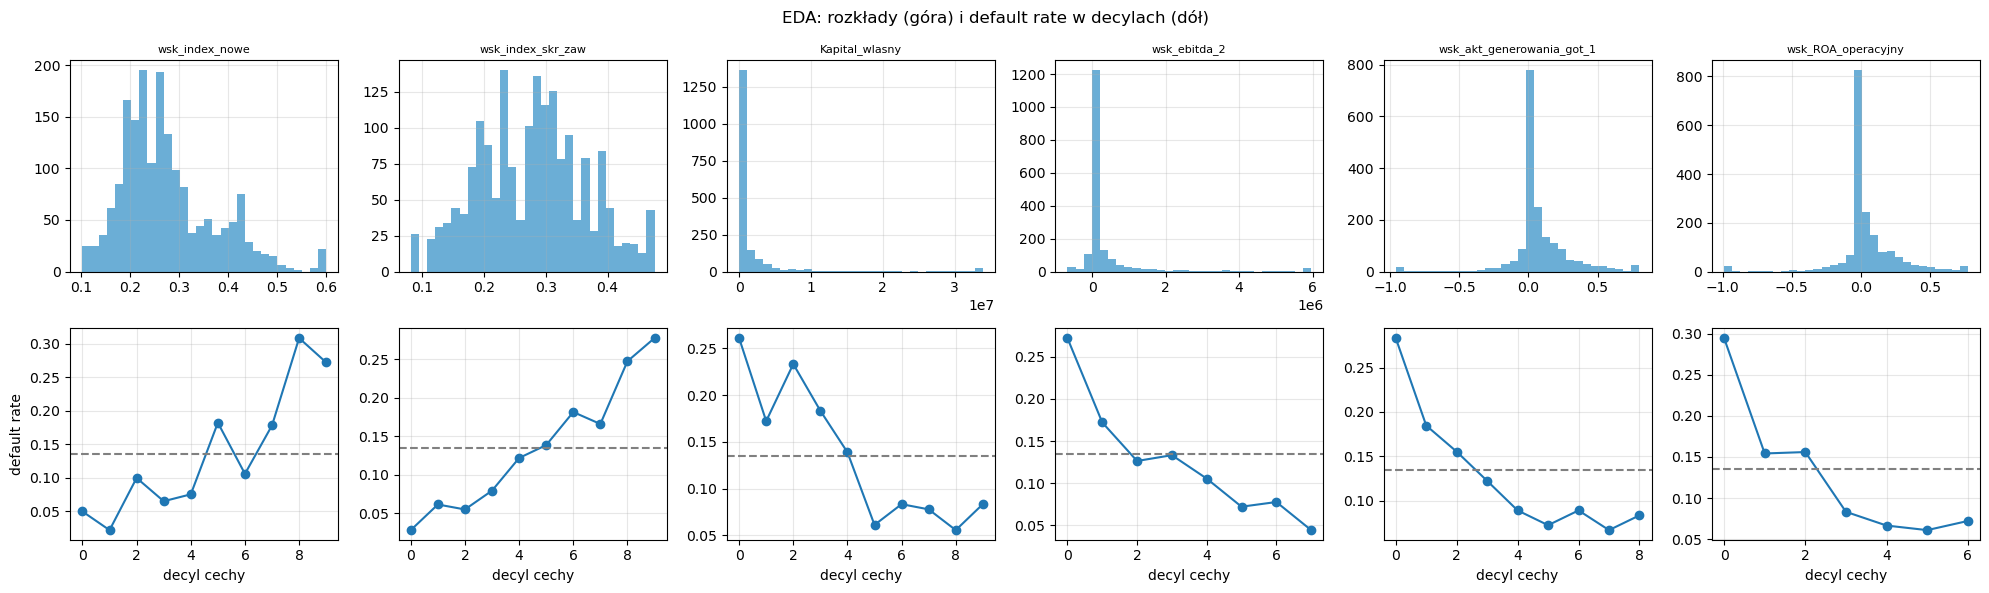

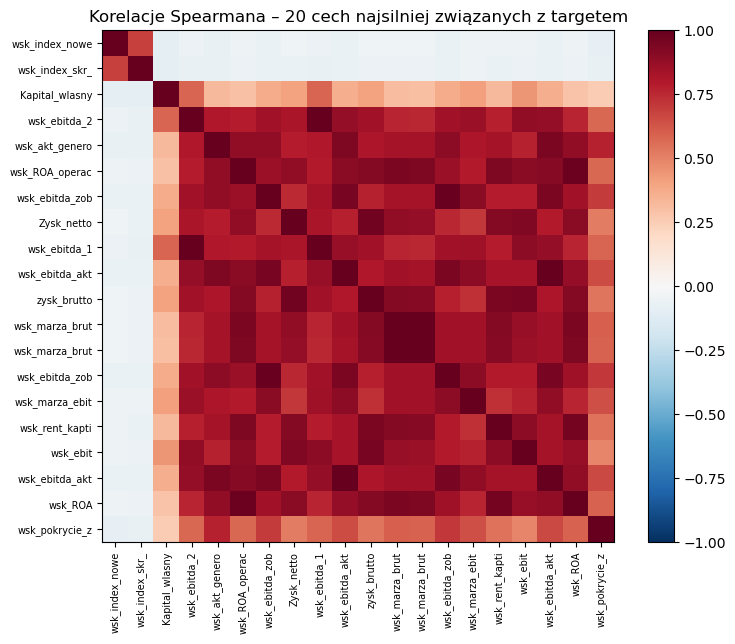


Default rate wg formaWlasnosci_Symbol:
                       count     DR
formaWlasnosci_Symbol              
0                        119 0.1345
112                        7 0.2857
113                       19 0.0000
131                        2 0.0000
214                     1154 0.1256
215                      185 0.1405
216                      171 0.1930
224                       50 0.1400
225                       21 0.1429
226                       36 0.1667
227                       28 0.1071
234                        2 0.0000
235                        3 0.3333
338                        3 0.3333

Default rate wg szczegolnaFormaPrawna_Symbol:
                              count     DR
szczegolnaFormaPrawna_Symbol              
117                            1800 0.1350

Odsetek obserwacji odstających wg IQR (top 8):
                          cecha  %_odstajacych
         wsk_zysk_CF_operacyjny        42.1000
         wsk_stopa_marzy_brutto        32.2000
           wsk_kosz

In [11]:
# Rozkłady (po winsoryzacji 1–99% na potrzeby wizualizacji) i default rate w decylach dla najsilniejszych cech
top_eda = [c for c in eda_corr[eda_corr.n_nonmissing > 0.5 * len(Xn)].index[:6]]
fig, axes = plt.subplots(2, 6, figsize=(20, 6))
for j, c in enumerate(top_eda):
    s = Xn[c].dropna(); lo, hi = s.quantile([.01, .99])
    axes[0, j].hist(s.clip(lo, hi), bins=30, color="#6baed6"); axes[0, j].set_title(c[:28], fontsize=8)
    q = pd.qcut(s, 10, duplicates="drop"); dr = y_train.loc[s.index].groupby(q, observed=True).mean()
    axes[1, j].plot(range(len(dr)), dr.values, "o-"); axes[1, j].axhline(y_train.mean(), color="gray", ls="--")
    axes[1, j].set_xlabel("decyl cechy"); axes[1, j].set_ylabel("default rate" if j == 0 else "")
plt.suptitle("EDA: rozkłady (góra) i default rate w decylach (dół)"); plt.tight_layout(); plt.show()

# Korelacje między cechami (top 20 wg |Spearman z targetem|)
top20 = [c for c in eda_corr[eda_corr.n_nonmissing > 0.5 * len(Xn)].index[:20]]
cm = Xn[top20].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5)); im = ax.imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(20)); ax.set_xticklabels([c[:14] for c in top20], rotation=90, fontsize=7)
ax.set_yticks(range(20)); ax.set_yticklabels([c[:14] for c in top20], fontsize=7); ax.grid(False)
plt.colorbar(im); ax.set_title("Korelacje Spearmana – 20 cech najsilniej związanych z targetem"); plt.tight_layout(); plt.show()

# default rate po kategoriach
for c in ["formaWlasnosci_Symbol", "szczegolnaFormaPrawna_Symbol"]:
    if c in X_train.columns:
        t = y_train.groupby(X_train[c]).agg(["count", "mean"]).rename(columns={"mean": "DR"}); print(f"\nDefault rate wg {c}:"); print(t)

# Obserwacje odstające metodą rozstępu międzykwartylowego
rows = []
for c in NUM_COLS:
    s = Xn[c].dropna()
    if s.nunique() > 1:
        q1, q3 = s.quantile([.25, .75]); i = q3 - q1
        if i > 0: rows.append((c, ((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).mean() * 100))
print("\nOdsetek obserwacji odstających wg IQR (top 8):"); print(pd.DataFrame(rows, columns=["cecha", "%_odstajacych"]).sort_values("%_odstajacych", ascending=False).head(8).round(1).to_string(index=False))

### 3.1 Kontrola przecieku: AUC jednowymiarowe każdej cechy
Heurystyka: cecha silniejsza niż jakikolwiek sensowny model (AUC > 0,85) to sygnał alarmowy – najczęściej informacja z przyszłości.

In [13]:
rows = []
for c in NUM_COLS:
    m = Xn[c].notna()
    if m.sum() > 30 and y_train[m].nunique() == 2 and Xn.loc[m, c].nunique() > 1:
        auc = roc_auc_score(y_train[m], Xn.loc[m, c]); rows.append({"cecha": c, "AUC jednowymiarowe": max(auc, 1 - auc), "kierunek": "+" if auc >= 0.5 else "-", "braki": 1 - m.mean()})
tab_auc = pd.DataFrame(rows).set_index("cecha").sort_values("AUC jednowymiarowe", ascending=False)
display(tab_auc.head(12).round(3))
podejrzane = tab_auc.index[tab_auc["AUC jednowymiarowe"] > 0.85].tolist()
print("Podejrzanie silne cechy (AUC > 0,85):", podejrzane if podejrzane else "brak")
print("Aktualnie wykluczone (zmienna WYKLUCZONE):", WYKLUCZONE)

,AUC jednowymiarowe,kierunek,braki
cecha,,,
RP_amortyzacja,0.7370,-,0.9570
wsk_index_nowe,0.7000,+,0.0000
wsk_index_skr_zaw,0.6850,+,0.0000
Kapital_wlasny,0.6550,-,0.0000
wsk_ebitda_2,0.6530,-,0.0000
wsk_akt_generowania_got_1,0.6530,-,0.0000
wsk_ebitda_zobowiazan_2,0.6520,-,0.0000
wsk_ebitda_1,0.6510,-,0.0000
wsk_ebitda_aktywa_2,0.6510,-,0.0000


Podejrzanie silne cechy (AUC > 0,85): brak
Aktualnie wykluczone (zmienna WYKLUCZONE): []


In [14]:
# zastosowanie decyzji o wykluczeniu cech (dla formalności, ponieważ żadnej nie wykluczamy)
if WYKLUCZONE:
    X_train, X_val, X_test = [d.drop(columns=WYKLUCZONE) for d in (X_train, X_val, X_test)]
CAT_COLS = [c for c in X_train.columns if c in CODE_COLS or not pd.api.types.is_numeric_dtype(X_train[c])]
NUM_COLS = [c for c in X_train.columns if c not in CAT_COLS]
FEATURES = list(X_train.columns)
print(f"Cechy do modelowania: {len(FEATURES)} (liczbowe: {len(NUM_COLS)}, kategoryczne: {len(CAT_COLS)})")

Cechy do modelowania: 222 (liczbowe: 217, kategoryczne: 5)


## 4. Przygotowanie cech – pipeline
Wszystkie kroki dopasowywane do danych są wewnątrz transformera, który uczy się na danych treningowych (w CV – na foldzie treningowym):

1. `±inf → NaN` (często dzielenie przez 0 we wskaźnikach),
2. usunięcie cech o >50% braków lub stałych,
3. winsoryzacja do kwantyli 1–99%,
4. imputacja medianą + flaga braku dla cech z ≥2% braków (informacja o brakach bywa predyktywna),
5. filtr |ρ|>0,95 (zostaje cecha silniej skorelowana z targetem) i filtr VIF>5 (dla cech liczbowych, przed dodaniem flag braków),
6. kategorie: One-Hot z grupowaniem rzadkich poziomów (<20 obs.) do „infrequent”.

Standaryzacja dla regresji logistycznej jest osobnym krokiem pipeline'u; XGBoost jej nie potrzebuje, bo jest oparty na drzewach.

In [16]:
def to_str(X):                       # kody -> tekst, braki jako osobna kategoria "nan"
    return pd.DataFrame(X).astype(str)

class NumPrep(BaseEstimator, TransformerMixin):
    def __init__(self, max_missing=0.5, q_low=0.01, q_high=0.99, corr_thr=0.95, vif_thr=5.0, ind_min=0.02):
        self.max_missing = max_missing; self.q_low = q_low; self.q_high = q_high
        self.corr_thr = corr_thr; self.vif_thr = vif_thr; self.ind_min = ind_min

    def _clean(self, X):
        return pd.DataFrame(X).replace([np.inf, -np.inf], np.nan)

    def fit(self, X, y=None):
        X = self._clean(X); self.input_cols_ = list(X.columns)
        miss = X.isna().mean()
        keep = [c for c in X.columns if miss[c] <= self.max_missing and X[c].nunique(dropna=True) > 1]
        X = X[keep]
        self.lo_, self.hi_ = X.quantile(self.q_low), X.quantile(self.q_high)
        Xc = X.clip(self.lo_, self.hi_, axis=1)
        self.median_ = Xc.median(); Xi = Xc.fillna(self.median_)
        # po winsoryzacji/imputacji cecha może stać się stała (np. >98% zer) -> usuwamy (NaN w korelacjach, brak informacji)
        nonconst = [c for c in Xi.columns if Xi[c].std() > 1e-12]
        keep = [c for c in keep if c in nonconst]; X = X[keep]; Xc = Xc[keep]; Xi = Xi[keep]
        self.lo_, self.hi_, self.median_ = self.lo_[keep], self.hi_[keep], self.median_[keep]
        # filtr korelacji
        if y is not None:
            ys = pd.Series(np.asarray(y), index=Xi.index)
            tgt = Xi.corrwith(ys, method="spearman").abs().fillna(0).values
        else:
            tgt = np.zeros(Xi.shape[1])
        cmat = np.nan_to_num(np.abs(np.corrcoef(Xi.values, rowvar=False)))
        kept = []
        for i in np.argsort(-tgt, kind="stable"):
            if all(cmat[i, j] <= self.corr_thr for j in kept): kept.append(i)
        cols = [Xi.columns[i] for i in sorted(kept)]
        # iteracyjny VIF 
        while len(cols) > 2:
            R = np.nan_to_num(np.corrcoef(Xi[cols].values, rowvar=False), nan=0.0); np.fill_diagonal(R, 1.0)
            try: vif = np.diag(np.linalg.pinv(R))
            except np.linalg.LinAlgError: vif = np.diag(np.linalg.pinv(R + 1e-6 * np.eye(len(R))))
            j = int(np.argmax(vif))
            if vif[j] <= self.vif_thr: break
            cols.pop(j)
        self.keep_, self.final_num_ = keep, cols
        # flagi braków (tylko dla zachowanych cech, bez duplikatów)
        cand = [c for c in cols if miss[c] >= self.ind_min]
        if cand:
            ind = X[cand].isna().astype(float); ind = ind.loc[:, ~ind.T.duplicated()]
            ind = ind.loc[:, ind.nunique() > 1]; self.ind_cols_ = list(ind.columns)
        else:
            self.ind_cols_ = []
        self.out_cols_ = cols + [c + "__NA" for c in self.ind_cols_]
        return self

    def transform(self, X):
        X = self._clean(X)[self.keep_]
        Xc = X.clip(self.lo_, self.hi_, axis=1)
        out = Xc.fillna(self.median_)[self.final_num_]
        for c in self.ind_cols_: out[c + "__NA"] = X[c].isna().astype(float)
        return out

    def get_feature_names_out(self, input_features=None):
        return np.array(self.out_cols_)

class Sanitize(BaseEstimator, TransformerMixin):
    # XGBoost nie akceptuje znaków [ ] < w nazwach cech
    def fit(self, X, y=None):
        self.cols_ = [re.sub(r"[\[\]<>]", "_", str(c)) for c in X.columns]; return self
    def transform(self, X):
        X = X.copy(); X.columns = self.cols_; return X
    def get_feature_names_out(self, input_features=None):
        return np.array(self.cols_)

def make_prep(drop=None, exclude=()):      
    # drop="first" dla regresji logistycznej; drzewa - pełne one-hot
    cat = Pipeline([("str", FunctionTransformer(to_str, feature_names_out="one-to-one")),
                    ("ohe", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False, drop=drop))])
    ct = ColumnTransformer([("num", NumPrep(), [c for c in NUM_COLS if c not in exclude]),
                            ("cat", cat, [c for c in CAT_COLS if c not in exclude])], verbose_feature_names_out=False)
    return ct

def make_lr():
    return Pipeline([("prep", make_prep("first")), ("san", Sanitize()), ("scaler", StandardScaler()),
                     ("clf", LogisticRegression(max_iter=5000))], memory=CACHE)

def make_xgb(exclude=()):
    return Pipeline([("prep", make_prep(exclude=exclude)), ("san", Sanitize()),
                     ("clf", XGBClassifier(tree_method="hist", eval_metric="logloss", n_jobs=4,
                                           random_state=SEED, verbosity=0))], memory=CACHE)

def tdf(pipe, X):
    # dane po wszystkich krokach poza ostatnim (klasyfikatorem), jako DataFrame
    return pipe[:-1].transform(X)

# podgląd: ile cech zostaje po przygotowaniu
_p = make_prep().fit(X_train, y_train); _o = _p.transform(X_train)
print(f"Cechy wejściowe: {X_train.shape[1]} -> po przygotowaniu: {_o.shape[1]} (numeryczne+flagi: {len(_p.named_transformers_['num'].out_cols_)}, one-hot: {_o.shape[1]-len(_p.named_transformers_['num'].out_cols_)})")
print("Usunięte wskutek >50% braków/stałości:", len(NUM_COLS) - len(_p.named_transformers_['num'].keep_))

Cechy wejściowe: 222 -> po przygotowaniu: 153 (numeryczne+flagi: 121, one-hot: 32)
Usunięte wskutek >50% braków/stałości: 16


## 5. Metryki i model interpretowalny – regresja logistyczna
Metryki dyskryminacji: AUC, Gini, KS, PR-AUC. Metryki kalibracji:
Brier, log-loss, ECE, ACE, CITL a (calibration-in-the-large: $a>0$ – PD zaniżone, $a<0$ – zawyżone), nachylenie (Cox; $b<1$ – PD zbyt skrajne) oraz test Hosmera-Lemeshowa (czytany ostrożnie – p-wartość zależy od liczby obserwacji).

In [18]:
EPS = 1e-6
def logit(p):
    p = np.clip(np.asarray(p, float), EPS, 1 - EPS); return np.log(p / (1 - p))
def sigmoid(z): return 1 / (1 + np.exp(-np.asarray(z, float)))
_z = logit

def ks_stat(y, p):
    fpr, tpr, _ = roc_curve(y, p); return float(np.max(tpr - fpr))

def ece(y, p, n_bins=10):                      # przedziały równej szerokości
    edges = np.linspace(0, 1, n_bins + 1); idx = np.clip(np.digitize(p, edges[1:-1]), 0, n_bins - 1)
    return float(sum(np.mean(idx == m) * abs(y[idx == m].mean() - p[idx == m].mean()) for m in range(n_bins) if np.any(idx == m)))

def przedzialy_rowne_liczebnie(p, n_bins=10):
    edges = np.unique(np.quantile(p, np.linspace(0, 1, n_bins + 1)))
    return np.clip(np.digitize(p, edges[1:-1], right=True), 0, len(edges) - 2), len(edges) - 1

def ace(y, p, n_bins=10):                      # przedziały równoliczne
    idx, k = przedzialy_rowne_liczebnie(p, n_bins)
    return float(sum(np.mean(idx == m) * abs(y[idx == m].mean() - p[idx == m].mean()) for m in range(k) if np.any(idx == m)))

def murphy(y, p, n_bins=10):                   # Brier ≈ rzetelność - rozdzielczość + niepewność
    idx, k = przedzialy_rowne_liczebnie(p, n_bins); o = y.mean(); rel = res = 0.0
    for m in range(k):
        msk = idx == m
        if msk.any(): w = msk.mean(); rel += w * (p[msk].mean() - y[msk].mean()) ** 2; res += w * (y[msk].mean() - o) ** 2
    return rel, res, o * (1 - o)

def cox(y, p):                                 # CITL a (przy nachyleniu = 1) i nachylenie b
    z = logit(p); a = brentq(lambda d: sigmoid(z + d).mean() - y.mean(), -15, 15)
    if np.ptp(z) < 1e-9: return a, np.nan
    return a, LogisticRegression(C=1e6, max_iter=1000).fit(z.reshape(-1, 1), y).coef_[0, 0]

def hosmer_lemeshow(y, p, n_bins=10):
    idx, k = przedzialy_rowne_liczebnie(p, n_bins); hl = 0.0
    for m in range(k):
        msk = idx == m; n_g = msk.sum(); o, e = y[msk].sum(), p[msk].sum(); hl += (o - e) ** 2 / (e * (1 - e / n_g))
    return hl, chi2.sf(hl, k)

def point_metrics(y, p):
    return {"AUC": roc_auc_score(y, p), "PR_AUC": average_precision_score(y, p), "KS": ks_stat(y, p),
            "LogLoss": log_loss(y, np.clip(p, EPS, 1 - EPS), labels=[0, 1]), "Brier": brier_score_loss(y, p)}

def full_metrics(y, p):
    y, p = np.asarray(y), np.asarray(p); m = point_metrics(y, p); m["Gini"] = 2 * m["AUC"] - 1; a, b = cox(y, p)
    m.update({"Mean_PD": float(p.mean()), "DR": float(y.mean()), "ECE": ece(y, p), "ACE": ace(y, p), "CITL": a, "Slope": b})
    return m

def cv_oof(est, X, y, cv, groups=None):
    ya = np.asarray(y); oof = np.zeros(len(ya)); rows = []
    for k, (a, b) in enumerate(cv.split(X, ya, groups), 1):
        m = clone(est).fit(X.iloc[a], ya[a]); p = m.predict_proba(X.iloc[b])[:, 1]; oof[b] = p
        rows.append({"fold": k, **point_metrics(ya[b], p)})
    return oof, pd.DataFrame(rows).set_index("fold")

def cv_summary(df): return pd.DataFrame({"średnia": df.mean(), "odch.std": df.std(), "min": df.min(), "max": df.max()})

In [19]:
# Przeszukiwanie siatki hiperparametrów dla Regresji Logistycznej
lr_grid = [{"clf__solver": ["lbfgs"], "clf__penalty": ["l2"], "clf__C": [0.003, 0.01, 0.03, 0.1, 0.3, 1]},
           {"clf__solver": ["liblinear"], "clf__penalty": ["l1"], "clf__C": [0.01, 0.03, 0.1, 0.3, 1]}]

lr_search = GridSearchCV(make_lr(), lr_grid, scoring={"auc": "roc_auc", "ll": "neg_log_loss"}, refit="auc",
                         cv=cv, n_jobs=1, return_train_score=True)
lr_search.fit(X_train, y_train, groups=G_train)

# Wyświetlenie pełnych wyników posortowanych po AUC na teście (CV)
res = pd.DataFrame(lr_search.cv_results_)[["param_clf__penalty", "param_clf__C", "mean_train_auc", "mean_test_auc", "std_test_auc", "mean_test_ll"]]
print("Wyniki grid searcha (posortowane po mean_test_auc):")
print(res.sort_values("mean_test_auc", ascending=False).round(4).to_string(index=False))

print("\nNajlepsze parametry wg GridSearchCV:", lr_search.best_params_)

Wyniki grid searcha (posortowane po mean_test_auc):
param_clf__penalty  param_clf__C  mean_train_auc  mean_test_auc  std_test_auc  mean_test_ll
                l1        0.1000          0.8357         0.7568        0.0252       -0.3466
                l1        0.0300          0.7666         0.7507        0.0237       -0.3576
                l2        0.0100          0.8503         0.7435        0.0212       -0.3524
                l2        0.0030          0.8318         0.7433        0.0233       -0.3553
                l2        0.0300          0.8621         0.7365        0.0222       -0.3628
                l1        0.3000          0.8638         0.7359        0.0208       -0.3696
                l2        0.1000          0.8697         0.7242        0.0218       -0.3861
                l1        1.0000          0.8728         0.7171        0.0217       -0.4066
                l1        0.0100          0.7233         0.7165        0.0283       -0.4063
                l2        0.

In [20]:
# Konfiguracja wybranego modelu, walidacja OOF i test na zbiorze walidacyjnym
# Wybrane parametry: C=0.03, L1. Uzasadnienie: mało przeucza i prostszy
chosen_params = {'clf__C': 0.03, 'clf__penalty': 'l1', 'clf__solver': 'liblinear'}

print(f"Używane parametry modelu: {chosen_params}")
try:   # porównanie wybranej konfiguracji z najlepszą wg grid searcha
    _r = pd.DataFrame(lr_search.cv_results_)
    _m = (_r["param_clf__penalty"] == chosen_params["clf__penalty"]) & (_r["param_clf__C"].astype(float) == chosen_params["clf__C"])
    print(f"CV AUC wybranej konfiguracji: {_r.loc[_m, 'mean_test_auc'].iloc[0]:.4f} (±{_r.loc[_m, 'std_test_auc'].iloc[0]:.4f}) | najlepsza wg grid searcha {lr_search.best_params_['clf__C']}: {lr_search.best_score_:.4f}")
except Exception as e:
    print("Nie udało się porównać z grid searchem:", repr(e))

# wytrenowanie ostatecznego modelu z wybranymi parametrami
best_lr = make_lr().set_params(**chosen_params)
best_lr.fit(X_train, y_train)

# Walidacja OOF na train
oof_lr, cv_lr = cv_oof(make_lr().set_params(**chosen_params), X_train, y_train, cv, G_train)
print("\nLR – metryki w 5-fold CV (train):")
print(cv_summary(cv_lr).round(4))

# Ocena na zbiorze walidacyjnym
pv_lr = best_lr.predict_proba(X_val)[:, 1]
print("\nLR – walidacja (val, surowe PD):")
print(pd.Series(full_metrics(y_val, pv_lr)).round(4).to_frame("LR (val)").T)

Używane parametry modelu: {'clf__C': 0.03, 'clf__penalty': 'l1', 'clf__solver': 'liblinear'}
CV AUC wybranej konfiguracji: 0.7507 (±0.0237) | najlepsza wg grid searcha 0.1: 0.7568

LR – metryki w 5-fold CV (train):
         średnia  odch.std    min    max
AUC       0.7507    0.0265 0.7205 0.7821
PR_AUC    0.3545    0.0361 0.3089 0.4001
KS        0.4293    0.0618 0.3462 0.5080
LogLoss   0.3576    0.0096 0.3452 0.3683
Brier     0.1056    0.0033 0.1013 0.1092

LR – walidacja (val, surowe PD):
            AUC  PR_AUC     KS  LogLoss  Brier   Gini  Mean_PD     DR    ECE    ACE    CITL  Slope
LR (val) 0.7546  0.3526 0.4105   0.3537 0.1050 0.5093   0.1546 0.1350 0.0308 0.0329 -0.1677 1.5562


Kategorie referencyjne (drop='first'):


,cecha,kategoria referencyjna
0,szczegolnaFormaPrawna_Symbol,117
1,formaWlasnosci_Symbol,0
2,pkdKod,3511
3,schemat_wsk_bilans,SFJIN
4,schemat_wsk_rzis,SFJIN


Cech po przygotowaniu: 148, niezerowych β: 11 | wyraz wolny = -1.818


,beta,OR (na 1 odch. std.),oczekiwany,znak jednowym.(Spearman),zgodny z oczekiwanym,zgodny z jednowym.
wsk_index_nowe,0.2670,1.3070,?,1.0000,-,True
wsk_index_skr_zaw,0.2240,1.2510,?,1.0000,-,True
wsk_ROE_brutto,-0.1650,0.8480,?,-1.0000,-,True
wsk_zadluzenia_krotkie,0.1480,1.1600,+,1.0000,tak,True
wsk_ebitda_aktywa_2,-0.0820,0.9220,-,-1.0000,tak,True
wsk_zast_kapitalu_podstawowego,0.0610,1.0630,?,1.0000,-,True
wsk_koszty_fin_przychody,0.0600,1.0620,+,1.0000,tak,True
Zysk_netto,-0.0470,0.9540,?,-1.0000,-,True
wsk_rent_kaptial_podstawowy,-0.0310,0.9700,-,-1.0000,tak,True
wsk_poziom_kapitalu_obrotowego_netto,-0.0230,0.9770,-,-1.0000,tak,True



|β| nie porównujemy między cechami liczbowymi i zero-jedynkowymi.


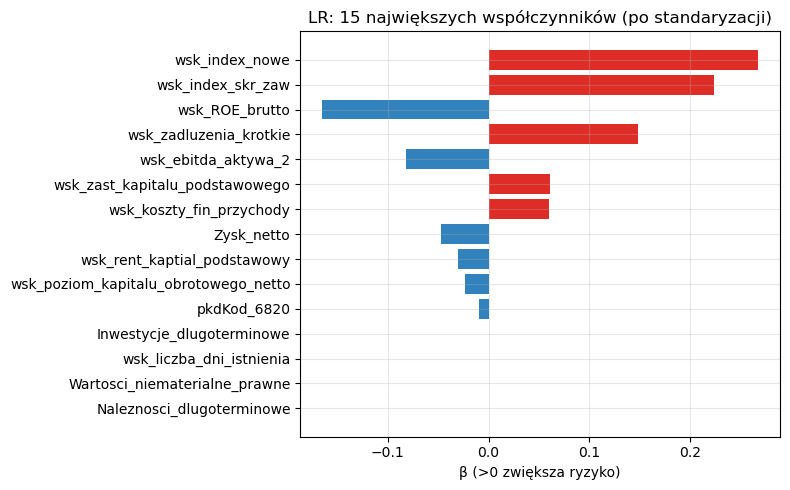

VIF końcowych cech (top 6):
schemat_wsk_bilans_SFJMI    34.8700
schemat_wsk_rzis_SFJMI      31.3300
pkdKod_infrequent_sklearn   28.0900
schemat_wsk_bilans_SFJMA    19.8800
schemat_wsk_rzis_SFJMA      19.4300
wsk_plynnosc_biez_1__NA      8.3200
dtype: float64


In [21]:
# Interpretacja globalna LR: β na 1 odch. std., OR = exp(β), kategorie referencyjne, kontrola znaków
lr_clf = best_lr[-1]; Xt_tr_lr = tdf(best_lr, X_train)
coef = pd.Series(lr_clf.coef_.ravel(), index=Xt_tr_lr.columns)
ohe_l = best_lr.named_steps["prep"].named_transformers_["cat"].named_steps["ohe"]
try:
    ref = pd.DataFrame({"cecha": CAT_COLS, "kategoria referencyjna": [ohe_l.categories_[i][ohe_l.drop_idx_[i]] for i in range(len(CAT_COLS))]})
    print("Kategorie referencyjne (drop='first'):"); display(ref)
except Exception: pass

def zrodlo(n):                       # kolumna po przekształceniu -> cecha źródłowa
    if n.endswith("__NA"): return n[:-4]
    for c in CAT_COLS:
        if n.startswith(c + "_"): return c
    return n
def grupy(cols):
    src = []; [src.append(zrodlo(c)) for c in cols if zrodlo(c) not in src]
    return np.array([[float(zrodlo(c) == s) for s in src] for c in cols]), src

sp_uni = pd.Series({c: spearmanr(Xt_tr_lr[c], y_train)[0] for c in Xt_tr_lr.columns})
exp_sign = pd.Series({c: OCZEKIWANY_ZNAK.get(zrodlo(c), "?") for c in Xt_tr_lr.columns})
coef_tab = pd.DataFrame({"beta": coef, "OR (na 1 odch. std.)": np.exp(coef), "oczekiwany": exp_sign, "znak jednowym.(Spearman)": np.sign(sp_uni)})
coef_tab["zgodny z oczekiwanym"] = np.where(coef_tab.oczekiwany == "?", "-", np.where(np.sign(coef_tab.beta) == coef_tab.oczekiwany.map({"+": 1, "-": -1}), "tak", "NIE"))
coef_tab["zgodny z jednowym."] = np.sign(coef_tab.beta) == coef_tab["znak jednowym.(Spearman)"]
coef_tab = coef_tab.reindex(coef_tab.beta.abs().sort_values(ascending=False).index)
print(f"Cech po przygotowaniu: {len(coef)}, niezerowych β: {(coef.abs() > 1e-8).sum()} | wyraz wolny = {lr_clf.intercept_[0]:.3f}")
display(coef_tab.head(15).round(3))
print("\n|β| nie porównujemy między cechami liczbowymi i zero-jedynkowymi.")

fig, ax = plt.subplots(figsize=(8, 5)); t = coef_tab.head(15).iloc[::-1]
ax.barh(t.index, t.beta, color=np.where(t.beta > 0, "#de2d26", "#3182bd")); ax.set_title("LR: 15 największych współczynników (po standaryzacji)"); ax.set_xlabel("β (>0 zwiększa ryzyko)")
plt.tight_layout(); plt.show()
Rm = np.corrcoef(Xt_tr_lr.values, rowvar=False); vif_final = pd.Series(np.diag(np.linalg.pinv(Rm)), index=Xt_tr_lr.columns).sort_values(ascending=False)
print("VIF końcowych cech (top 6):"); print(vif_final.head(6).round(2))

In [22]:
# Test monotoniczności regresji logistycznej w decylach
rows = []
for c in coef_tab.index[:12]:
    s = Xt_tr_lr[c]
    if s.nunique() < 5:
        continue
    q = pd.qcut(s.rank(method="first"), 10, labels=False)
    dr = y_train.groupby(q.values).mean()
    rho = spearmanr(dr.index, dr.values)[0]
    rows.append({"cecha": c, "znak β": np.sign(coef[c]),
                 "Spearman(decyl, DR)": rho,
                 "monotoniczny(|ρ|≥0,8)": abs(rho) >= 0.8,
                 "zgodny z β": np.sign(rho) == np.sign(coef[c])})
print(pd.DataFrame(rows).round(3).to_string(index=False))
print("PDP/ICE dla LR i XGBoost są liczone wspólnie w sekcji 6.4, na surowych cechach i w skali log-szans.")

                               cecha  znak β  Spearman(decyl, DR)  monotoniczny(|ρ|≥0,8)  zgodny z β
                      wsk_index_nowe  1.0000               0.9270                   True        True
                   wsk_index_skr_zaw  1.0000               0.9760                   True        True
                      wsk_ROE_brutto -1.0000              -0.7540                  False        True
              wsk_zadluzenia_krotkie  1.0000              -0.0180                  False       False
                 wsk_ebitda_aktywa_2 -1.0000              -0.8350                   True        True
      wsk_zast_kapitalu_podstawowego  1.0000               0.7810                  False        True
            wsk_koszty_fin_przychody  1.0000               0.0360                  False        True
                          Zysk_netto -1.0000              -0.8420                   True        True
         wsk_rent_kaptial_podstawowy -1.0000              -0.9060                   True   

### 5.1 SHAP dla baseline'u
Dla regresji logistycznej: $\phi_k=\beta_k\,(z_k-E[z_k])$. Wartości SHAP kolumn jednej cechy źródłowej sumujemy – grupa kolumn zachowuje się jak jeden gracz. Wartość bazowa = przeciętne log-szanse w danych treningowych.

In [24]:
def shap_lr(pipe, X, X_bg):
    # φ_k = β_k (z_k - E_T[z_k]), potem suma kolumn każdej cechy źródłowej. Zwraca DataFrame (n × cechy) i wartość bazową.
    Z = tdf(pipe, X); mu = tdf(pipe, X_bg).mean(); clf_ = pipe[-1]
    phi = (Z - mu) * clf_.coef_.ravel(); G, src = grupy(list(Z.columns))
    base = float(clf_.intercept_[0] + (mu.values * clf_.coef_.ravel()).sum())
    return pd.DataFrame(phi.values @ G, index=Z.index, columns=src), base

PHI_L_val, BASE_L = shap_lr(best_lr, X_val, X_train)
f_val = best_lr[-1].decision_function(tdf(best_lr, X_val))
print(f"Baseline: wartość bazowa = {BASE_L:+.3f} log-szans | maks. |baza + Σφ − f(x)| = {np.abs(BASE_L + PHI_L_val.sum(axis=1).values - f_val).max():.1e} (efektywność SHAP)")
try:     # kontrola względem biblioteki shap
    Xt_va_lr = tdf(best_lr, X_val); Xt_bg = tdf(best_lr, X_train)
    lib = shap.LinearExplainer(lr_clf, shap.maskers.Independent(Xt_bg, max_samples=len(Xt_bg)))(Xt_va_lr.iloc[:200]).values @ grupy(list(Xt_va_lr.columns))[0]
    print(f"Zgodność wzoru z shap.LinearExplainer: maks. różnica = {np.abs(lib - PHI_L_val.iloc[:200].values).max():.1e}")
except Exception as e: print("shap.LinearExplainer niedostępny:", type(e).__name__)

Baseline: wartość bazowa = -1.818 log-szans | maks. |baza + Σφ − f(x)| = 4.4e-16 (efektywność SHAP)
Zgodność wzoru z shap.LinearExplainer: maks. różnica = 0.0e+00


**Krótki komentarz do modelu interpretowalnego:** lasso nie wyzerowało jedynie 10-ciu cech, ich znaki β zgadzają się z oczekiwanymi (dla tych cech, dla których mogliśmy jednoznacznie wskazać oczekiwany znak), 6 cech jest silnie monotonicznych.

## 6. Model „black-box” – XGBoost, strojenie i SHAP (TreeSHAP)
Strojenie: `RandomizedSearchCV` (5-fold CV na train); kontrola overfittingu oraz luka train–CV.

In [27]:
from scipy.stats import loguniform, randint, uniform
xgb_dist = {"clf__n_estimators": randint(100, 600), "clf__learning_rate": loguniform(0.01, 0.1), "clf__max_depth": randint(2, 5),
            "clf__min_child_weight": [1, 3, 5, 10, 20], "clf__subsample": uniform(0.6, 0.4), "clf__colsample_bytree": uniform(0.5, 0.5),
            "clf__reg_lambda": loguniform(1, 50), "clf__gamma": [0, 0.5, 1, 3]}
xgb_search = RandomizedSearchCV(make_xgb(), xgb_dist, n_iter=N_ITER_XGB, scoring={"auc": "roc_auc", "ll": "neg_log_loss"}, refit="auc",
                                cv=cv, random_state=SEED, n_jobs=1, return_train_score=True)
xgb_search.fit(X_train, y_train, groups=G_train)
best_xgb = xgb_search.best_estimator_
r = pd.DataFrame(xgb_search.cv_results_); r["gap_train_cv"] = r.mean_train_auc - r.mean_test_auc
print(r.sort_values("mean_test_auc", ascending=False)[["mean_train_auc", "mean_test_auc", "std_test_auc", "gap_train_cv", "mean_test_ll"]].head(8).round(4))
print("\nNajlepsze parametry XGB:", {k.replace("clf__", ""): (round(float(v), 4) if isinstance(v, (float, np.floating)) else int(v)) for k, v in xgb_search.best_params_.items()})
print(f"Luka train-CV (AUC) najlepszej konfiguracji: {r.loc[xgb_search.best_index_, 'gap_train_cv']:.3f}  <- kontrola overfittingu")
oof_xgb, cv_xgb = cv_oof(make_xgb().set_params(**xgb_search.best_params_), X_train, y_train, cv, G_train)
print("\nXGB – metryki w 5-fold CV (train):"); print(cv_summary(cv_xgb).round(4))
pv_xgb = best_xgb.predict_proba(X_val)[:, 1]
print("\nPorównanie na VAL (surowe PD):"); print(pd.DataFrame({"LR": full_metrics(y_val, pv_lr), "XGB": full_metrics(y_val, pv_xgb)}).T.round(4))

    mean_train_auc  mean_test_auc  std_test_auc  gap_train_cv  mean_test_ll
37          0.9503         0.7739        0.0179        0.1765       -0.3393
3           0.9456         0.7737        0.0227        0.1719       -0.3387
20          0.9386         0.7729        0.0189        0.1656       -0.3398
11          0.9593         0.7729        0.0211        0.1864       -0.3394
13          0.9853         0.7721        0.0130        0.2132       -0.3454
25          0.9204         0.7720        0.0190        0.1484       -0.3411
2           0.8848         0.7714        0.0280        0.1134       -0.3397
31          0.9254         0.7714        0.0302        0.1540       -0.3395

Najlepsze parametry XGB: {'colsample_bytree': 0.9642, 'gamma': 0, 'learning_rate': 0.0357, 'max_depth': 4, 'min_child_weight': 5, 'n_estimators': 287, 'reg_lambda': 28.1344, 'subsample': 0.7178}
Luka train-CV (AUC) najlepszej konfiguracji: 0.176  <- kontrola overfittingu

XGB – metryki w 5-fold CV (train):
       

### 6.1 TreeSHAP
**Ustawienia:** wariant `tree_path_dependent`, skala log-szanse, wartość bazowa = przeciętne log-szanse w danych treningowych modelu, wyjaśniany zbiór: validation. Wartości SHAP kolumn one-hot i wskaźników braków sumujemy do cechy źródłowej.

Wartość bazowa = -1.856 log-szans (PD 13.52%) | maks. błąd addytywności = 3.4e-06
Cechy źródłowe w modelu: 124 (kolumn po przekształceniu: 153)


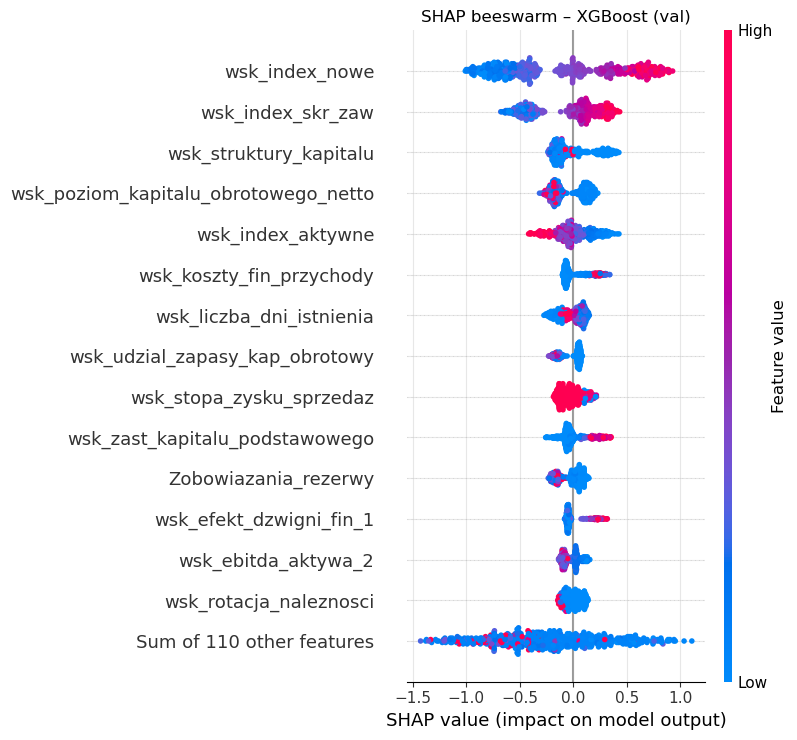

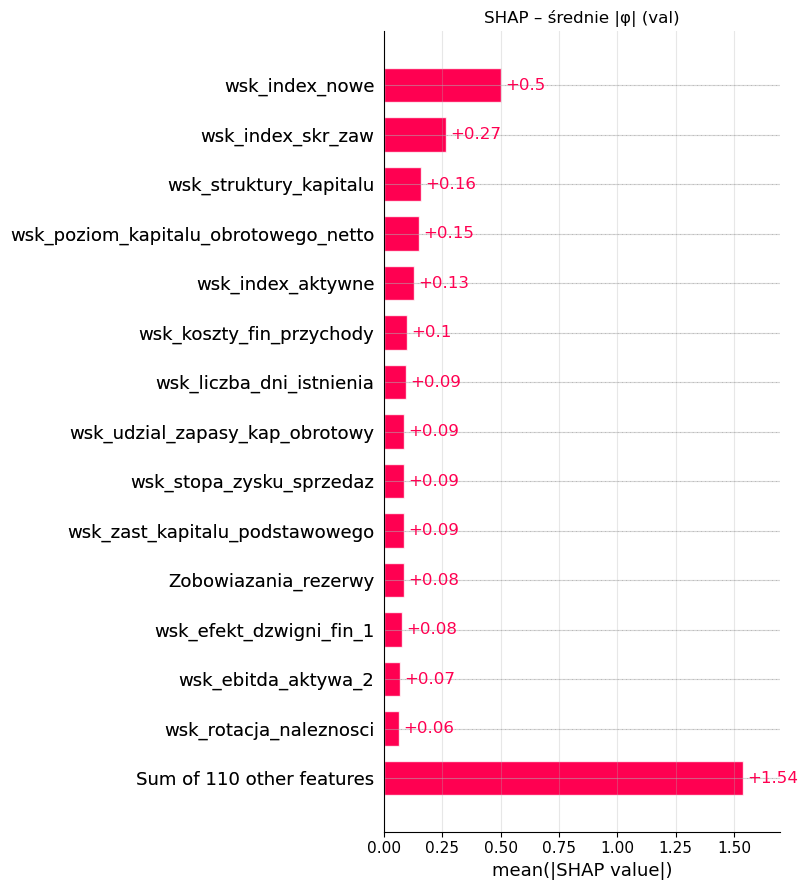

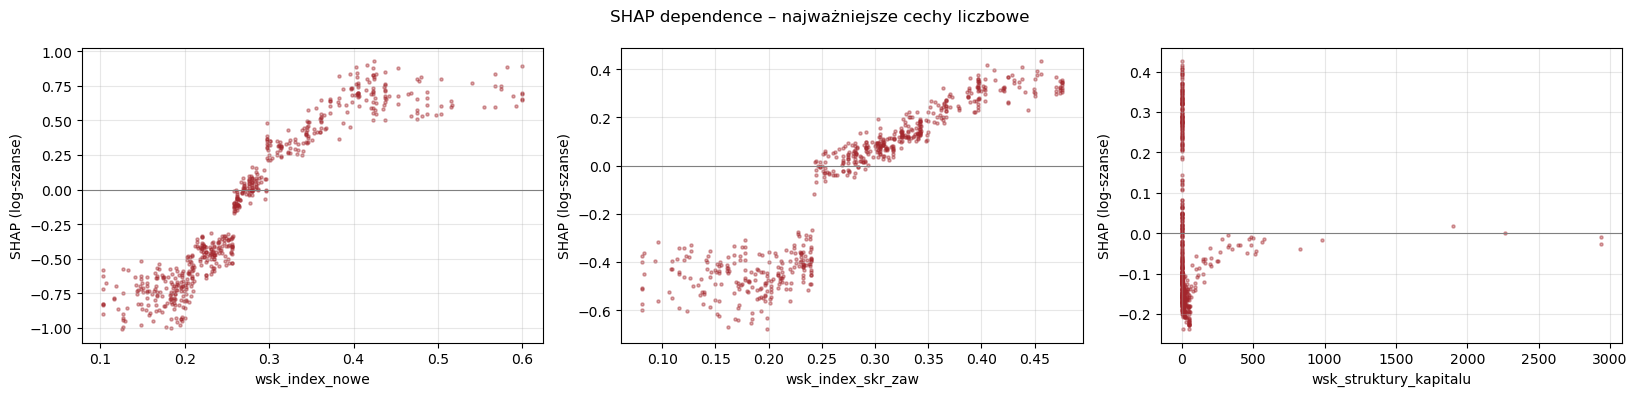


Top 10 cech wg SHAP:
wsk_index_nowe                         0.5020
wsk_index_skr_zaw                      0.2662
wsk_struktury_kapitalu                 0.1578
wsk_poziom_kapitalu_obrotowego_netto   0.1496
wsk_index_aktywne                      0.1261
wsk_koszty_fin_przychody               0.0971
wsk_liczba_dni_istnienia               0.0942
wsk_udzial_zapasy_kap_obrotowy         0.0866
wsk_stopa_zysku_sprzedaz               0.0854
wsk_zast_kapitalu_podstawowego         0.0853
dtype: float64


In [29]:
Xt_tr_x = tdf(best_xgb, X_train); Xt_va_x = tdf(best_xgb, X_val); xgb_clf = best_xgb[-1]; cols_x = list(Xt_va_x.columns)
explainer = shap.TreeExplainer(xgb_clf)
sv = explainer(Xt_va_x)
G_x, SRC_X = grupy(cols_x)
PHI_X = sv.values @ G_x                                    # (n, cechy źródłowe)
BASE_X = float(np.ravel(sv.base_values)[0])
margin = xgb_clf.predict(Xt_va_x, output_margin=True)
shap_add_err = float(np.max(np.abs(BASE_X + PHI_X.sum(axis=1) - margin)))
print(f"Wartość bazowa = {BASE_X:+.3f} log-szans (PD {sigmoid(BASE_X):.2%}) | maks. błąd addytywności = {shap_add_err:.1e}")
print(f"Cechy źródłowe w modelu: {len(SRC_X)} (kolumn po przekształceniu: {len(cols_x)})")

dane_kol = np.column_stack([Xt_va_x[s].to_numpy(float) if s in Xt_va_x.columns else np.full(len(Xt_va_x), np.nan) for s in SRC_X])   # kolor tylko dla cech liczbowych
E_x = shap.Explanation(values=PHI_X, base_values=np.full(len(PHI_X), BASE_X), data=dane_kol, feature_names=SRC_X)
shap_imp = pd.Series(np.abs(PHI_X).mean(0), index=SRC_X).sort_values(ascending=False)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    plt.figure(); shap.plots.beeswarm(E_x, max_display=15, show=False); plt.title("SHAP beeswarm – XGBoost (val)"); plt.tight_layout(); plt.show()
    plt.figure(); shap.plots.bar(E_x, max_display=15, show=False); plt.title("SHAP – średnie |φ| (val)"); plt.tight_layout(); plt.show()
top_num = [f for f in shap_imp.index if f in NUM_COLS][:3]
fig, ax = plt.subplots(1, len(top_num), figsize=(5.5 * len(top_num), 4), squeeze=False)
for a, f in zip(ax[0], top_num):
    j = SRC_X.index(f); a.scatter(dane_kol[:, j], PHI_X[:, j], s=5, alpha=0.4, color="#A3262C"); a.axhline(0, color="gray", lw=0.8); a.set_xlabel(f); a.set_ylabel("SHAP (log-szanse)"); a.grid(alpha=0.3)
plt.suptitle("SHAP dependence – najważniejsze cechy liczbowe"); plt.tight_layout(); plt.show()
print("\nTop 10 cech wg SHAP:"); print(shap_imp.head(10).round(4))

### 6.2 Spójność z baseline'em
Porównujemy globalną ważność (średnie |φ| na val) obu modeli oraz ważność permutacyjną (spadek AUC po przemieszaniu cechy), a także kierunki wpływu i kształt zależności SHAP (logit – jedna krzywa, black-box – chmura punktów).

Korelacja rang (Spearman) ważności SHAP: 0.34 | Jaccard top-10: 0.33


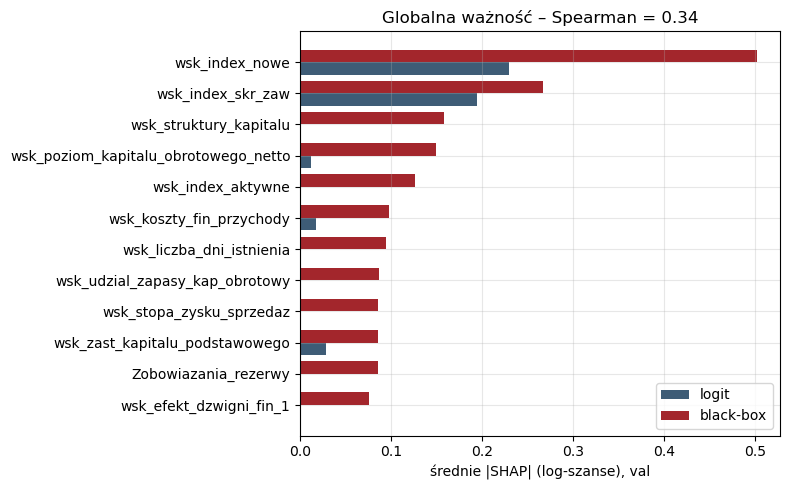

,kierunek SHAP black-box,kierunek SHAP logit,zgodne
cecha,,,
wsk_index_nowe,1.0000,1.0000,True
wsk_index_skr_zaw,1.0000,1.0000,True
wsk_struktury_kapitalu,-1.0000,NaN,False
wsk_poziom_kapitalu_obrotowego_netto,-1.0000,-1.0000,True
wsk_index_aktywne,-1.0000,NaN,False
wsk_koszty_fin_przychody,1.0000,1.0000,True
wsk_liczba_dni_istnienia,1.0000,NaN,False
wsk_udzial_zapasy_kap_obrotowy,-1.0000,NaN,False


Zgodność kierunków: 50%


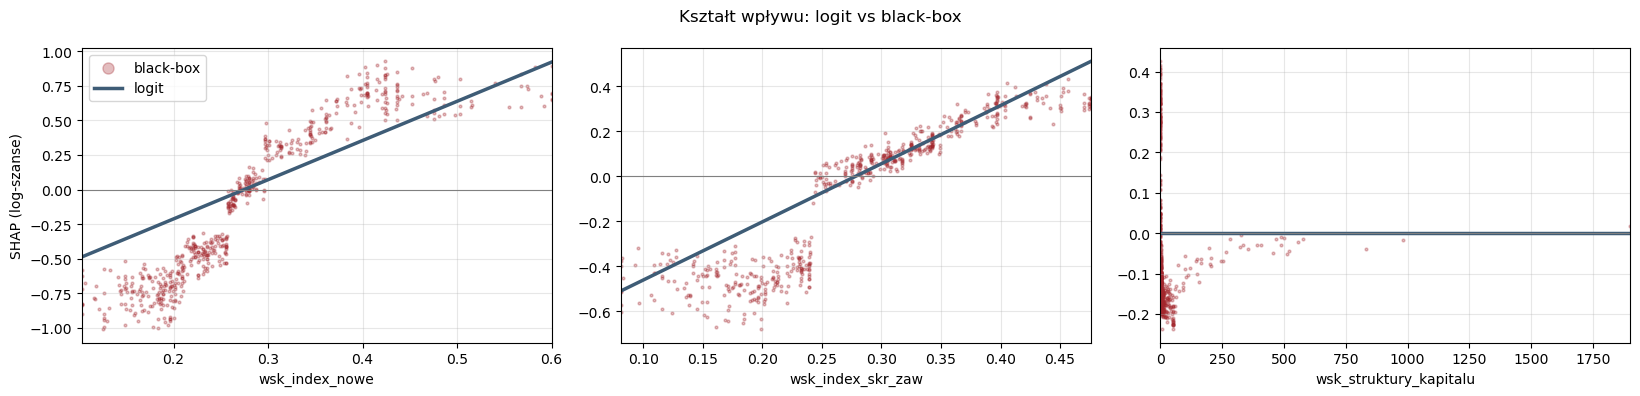

Ważność permutacyjna i SHAP – validation (top 40 cech wg SHAP XGB, 5 powtórzeń):


,permutacyjna LR,permutacyjna XGB,odch.std XGB,SHAP LR,SHAP XGB
wsk_index_nowe,0.0585,0.0664,0.0185,0.2295,0.5020
wsk_index_skr_zaw,0.0581,0.0366,0.0058,0.1940,0.2662
wsk_index_aktywne,0.0000,0.0110,0.0026,0.0000,0.1261
wsk_poziom_kapitalu_obrotowego_netto,0.0045,0.0094,0.0051,0.0122,0.1496
wsk_udzial_zapasy_kap_obrotowy,0.0000,0.0092,0.0018,0.0000,0.0866
wsk_liczba_dni_istnienia,0.0000,0.0071,0.0039,0.0000,0.0942
Zobowiazania_rezerwy,0.0000,0.0069,0.0016,0.0000,0.0848
wsk_koszty_fin_przychody,-0.0016,0.0066,0.0026,0.0177,0.0971
wsk_rent_kaptial_podstawowy,0.0011,0.0029,0.0016,0.0116,0.0590
wsk_zast_kapitalu_podstawowego,0.0009,0.0028,0.0033,0.0286,0.0853



Korelacja rang permutacja–SHAP XGB: 0.385


In [ ]:
# ważność permutacyjna (spadek AUC na valid, odch. std. z powtórzeń) obok SHAP
common = [c for c in SRC_X if c in PHI_L_val.columns]
waz = pd.DataFrame({"logit": np.abs(PHI_L_val[common]).mean(0), "black-box": pd.Series(np.abs(PHI_X).mean(0), index=SRC_X)[common]}).sort_values("black-box", ascending=False)
rho_waz = spearmanr(waz["logit"], waz["black-box"])[0]
k10 = 10; t_x, t_l = set(waz["black-box"].nlargest(k10).index), set(waz["logit"].nlargest(k10).index)
print(f"Korelacja rang (Spearman) ważności SHAP: {rho_waz:.2f} | Jaccard top-{k10}: {len(t_x & t_l) / len(t_x | t_l):.2f}")
fig, ax = plt.subplots(figsize=(8, 5)); w2 = waz.head(12).iloc[::-1]; yy = np.arange(len(w2))
ax.barh(yy - 0.2, w2["logit"], 0.4, color="#3E5C76", label="logit"); ax.barh(yy + 0.2, w2["black-box"], 0.4, color="#A3262C", label="black-box")
ax.set_yticks(yy); ax.set_yticklabels(w2.index); ax.set_xlabel("średnie |SHAP| (log-szanse), val"); ax.set_title(f"Globalna ważność – Spearman = {rho_waz:.2f}"); ax.legend(); ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()

# kierunki: znak korelacji (wartość cechy, SHAP) dla obu modeli
rows = []
for f in [c for c in waz.index if c in NUM_COLS][:8]:
    j = SRC_X.index(f); xv = dane_kol[:, j]
    rows.append({"cecha": f, "kierunek SHAP black-box": np.sign(np.corrcoef(xv, PHI_X[:, j])[0, 1]),
                 "kierunek SHAP logit": np.sign(np.corrcoef(xv, PHI_L_val[f].values)[0, 1])})
dirs = pd.DataFrame(rows).set_index("cecha"); dirs["zgodne"] = dirs.iloc[:, 0] == dirs.iloc[:, 1]; display(dirs); print(f"Zgodność kierunków: {dirs.zgodne.mean():.0%}")

# kształt zależności: logit (krzywa) vs black-box (chmura)
fig, ax = plt.subplots(1, len(top_num), figsize=(5.5 * len(top_num), 4), squeeze=False)
for a, f in zip(ax[0], top_num):
    j = SRC_X.index(f); xv = dane_kol[:, j]; o = np.argsort(xv)
    a.scatter(xv, PHI_X[:, j], s=4, alpha=0.3, color="#A3262C", label="black-box"); a.plot(xv[o], PHI_L_val[f].values[o], color="#3E5C76", lw=2.5, label="logit")
    a.axhline(0, color="gray", lw=0.8); a.set_xlabel(f); a.set_xlim(np.nanpercentile(xv, [0.5, 99.5])); a.grid(alpha=0.3)
ax[0, 0].legend(markerscale=4); ax[0, 0].set_ylabel("SHAP (log-szanse)"); plt.suptitle("Kształt wpływu: logit vs black-box"); plt.tight_layout(); plt.show()

# Ważność permutacyjna na validation – tylko najważniejsze cechy wg SHAP (pełna lista ~200 cech x powtórzenia x 2 modele trwała bardzo długo)
N_PERM_FEATS = 15 if FAST else 40      # ile najważniejszych cech (wg SHAP XGB) sprawdzamy
N_PERM_REP   = 3  if FAST else 5       # powtórzenia permutacji
def perm_imp(model, X, y, feats, n_rep=5, seed=SEED):
    rng = np.random.default_rng(seed)
    base = roc_auc_score(y, model.predict_proba(X)[:, 1])
    Xp = X.copy()                       # jedna kopia; po każdej permutacji przywracamy oryginalną kolumnę
    rows = []
    for f in feats:
        orig = X[f].to_numpy(); spadki = []
        for _ in range(n_rep):
            Xp[f] = rng.permutation(orig)
            spadki.append(base - roc_auc_score(y, model.predict_proba(Xp)[:, 1]))
        Xp[f] = orig
        rows.append({"cecha": f, "spadek AUC": np.mean(spadki), "odch.std": np.std(spadki, ddof=1)})
    return pd.DataFrame(rows).set_index("cecha")

feats_perm = [f for f in waz.index if f in FEATURES][:N_PERM_FEATS]
perm_lr  = perm_imp(best_lr,  X_val, y_val.to_numpy(), feats_perm, n_rep=N_PERM_REP)
perm_xgb = perm_imp(best_xgb, X_val, y_val.to_numpy(), feats_perm, n_rep=N_PERM_REP)

tab_perm = pd.DataFrame({
    "permutacyjna LR": perm_lr["spadek AUC"],
    "permutacyjna XGB": perm_xgb["spadek AUC"],
    "odch.std XGB": perm_xgb["odch.std"],
    "SHAP LR": np.abs(PHI_L_val).mean(axis=0),
    "SHAP XGB": pd.Series(np.abs(PHI_X).mean(axis=0), index=SRC_X)
}).loc[feats_perm].sort_values("permutacyjna XGB", ascending=False)

print(f"Ważność permutacyjna i SHAP – validation (top {len(feats_perm)} cech wg SHAP XGB, {N_PERM_REP} powtórzeń):")
display(tab_perm.round(4))
print("\nKorelacja rang permutacja–SHAP XGB:", round(spearmanr(tab_perm["permutacyjna XGB"], tab_perm["SHAP XGB"])[0], 3))


### 6.2a Ważność cech – permutacyjna
Ważność permutacyjna (na valid) pokazuje, o ile spadnie AUC, gdy model straci informację o cesze. Przy skorelowanych cechach metoda pyta model o kombinacje, których nie ma w danych, więc ranking nie musi być zgodny z rankingiem SHAP.

In [ ]:
# Interakcje SHAP: siła interakcji pary = średnie |2 φ_ij|; kolumny sumowane do cech źródłowych
idx_i = np.random.default_rng(SEED).choice(len(Xt_va_x), min(1000, len(Xt_va_x)), replace=False)
IV = np.einsum("nij,ia,jb->nab", explainer.shap_interaction_values(Xt_va_x.iloc[idx_i]), G_x, G_x, optimize=True)
sila = np.abs(IV).mean(0)
pary_int = pd.DataFrame([(SRC_X[a], SRC_X[b], 2 * sila[a, b]) for a in range(len(SRC_X)) for b in range(a + 1, len(SRC_X))], columns=["cecha 1", "cecha 2", "siła interakcji"]).sort_values("siła interakcji", ascending=False).reset_index(drop=True)
pary_int.index += 1; display(pary_int.head(8).round(4))
print("Średni |efekt główny| (porównanie):", pd.Series(np.diag(sila), index=SRC_X).sort_values(ascending=False).head(5).round(3).to_dict())
print("Uwaga: interakcje mogą wynikać także z korelacji cech – oceń, czy mają sens biznesowy.")

,cecha 1,cecha 2,siła interakcji
1,wsk_index_aktywne,wsk_index_skr_zaw,0.0442
2,wsk_index_skr_zaw,wsk_index_nowe,0.0428
3,wsk_index_aktywne,wsk_index_nowe,0.0343
4,wsk_index_nowe,wsk_ebitda_zobowiazan_2,0.0296
5,wsk_index_nowe,wsk_poziom_kapitalu_obrotowego_netto,0.0252
6,wsk_index_nowe,wsk_zysk_zobowiazania,0.0222
7,wsk_index_nowe,wsk_struktury_kapitalu,0.0215
8,wsk_index_nowe,wsk_zast_kapitalu_podstawowego,0.0205


Średni |efekt główny| (porównanie): {'wsk_index_nowe': 0.523, 'wsk_index_skr_zaw': 0.279, 'wsk_poziom_kapitalu_obrotowego_netto': 0.159, 'wsk_struktury_kapitalu': 0.154, 'wsk_index_aktywne': 0.121}
Uwaga: interakcje mogą wynikać także z korelacji cech – oceń, czy mają sens biznesowy.


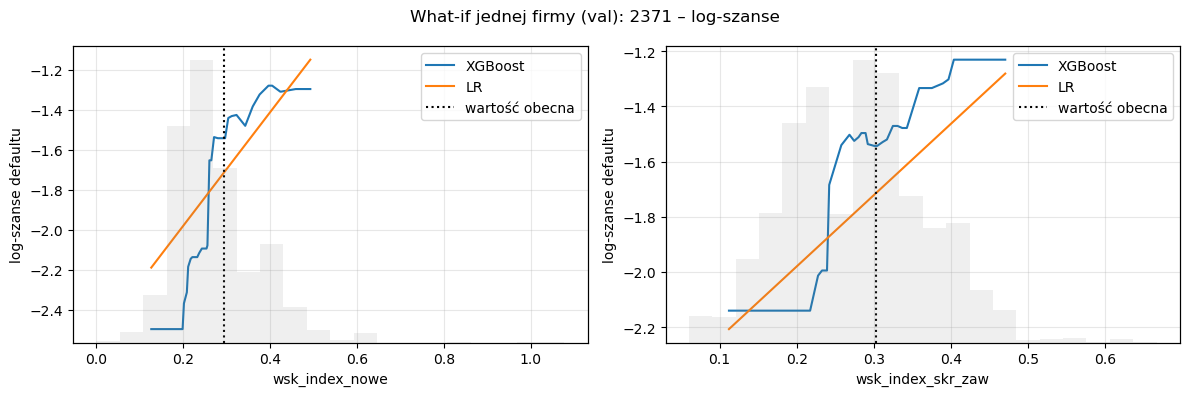

Uwaga: przy podstawianiu wartości surowej pipeline ustawia flagę braku tej cechy na 0. Dla cech z brakami (np. wsk_plynnosc_biez_1) wykres zakłada więc obserwację bez braku.


In [ ]:
# What-if: pojedyncza firma; skala log-szans i siatka z kwantyli train
raw_feats = [f for f in shap_imp.index if f in NUM_COLS and f in X_train.columns][:2]
i_w = X_val.index[int(np.argsort(pv_xgb)[len(pv_xgb) * 3 // 4])]
fig, ax = plt.subplots(1, len(raw_feats), figsize=(6 * len(raw_feats), 4), squeeze=False)
for a, f in zip(ax[0], raw_feats):
    train_values = X_train[f].replace([np.inf, -np.inf], np.nan).dropna()
    grid = np.unique(train_values.quantile(np.linspace(.02, .98, 40)).to_numpy())
    rowdf = pd.concat([X_val.loc[[i_w]]] * len(grid), ignore_index=True)
    rowdf[f] = grid
    z_x = logit(best_xgb.predict_proba(rowdf)[:, 1])
    z_l = logit(best_lr.predict_proba(rowdf)[:, 1])
    a.plot(grid, z_x, label="XGBoost")
    a.plot(grid, z_l, label="LR")
    a.axvline(X_val.loc[i_w, f], color="k", ls=":", label="wartość obecna")
    a.set_xlabel(f); a.set_ylabel("log-szanse defaultu")
    a.legend()
    a_hist = a.twinx()
    a_hist.hist(train_values, bins=20, density=True, alpha=.12, color="gray")
    a_hist.set_yticks([])
plt.suptitle(f"What-if jednej firmy (val): {i_w} – log-szanse")
plt.tight_layout(); plt.show()
print("Uwaga: przy podstawianiu wartości surowej pipeline ustawia flagę braku tej cechy na 0. Dla cech z brakami (np. wsk_plynnosc_biez_1) wykres zakłada więc obserwację bez braku.")

### 6.3 Studia przypadków: wyjaśnienia lokalne i kody przyczyn
Wyjaśnienia lokalne: wykres kaskadowy (waterfall, log-szanse) i kody przyczyn – cecha, wartość, wkład φ, mnożnik szans $e^{\phi}$ i kierunek. W komunikacji z klientem podajemy czynniki i ich kierunek, a nie liczby SHAP. Dla baseline'u – dekompozycja logitu na wkłady cech. Wybrane przypadki: wysokie ryzyko, niskie ryzyko, graniczny, największa rozbieżność modeli.


Wysokie ryzyko | obserwacja: 246 | PD_XGB: 68.90% | PD_LR: 27.84% | faktyczny default: 1


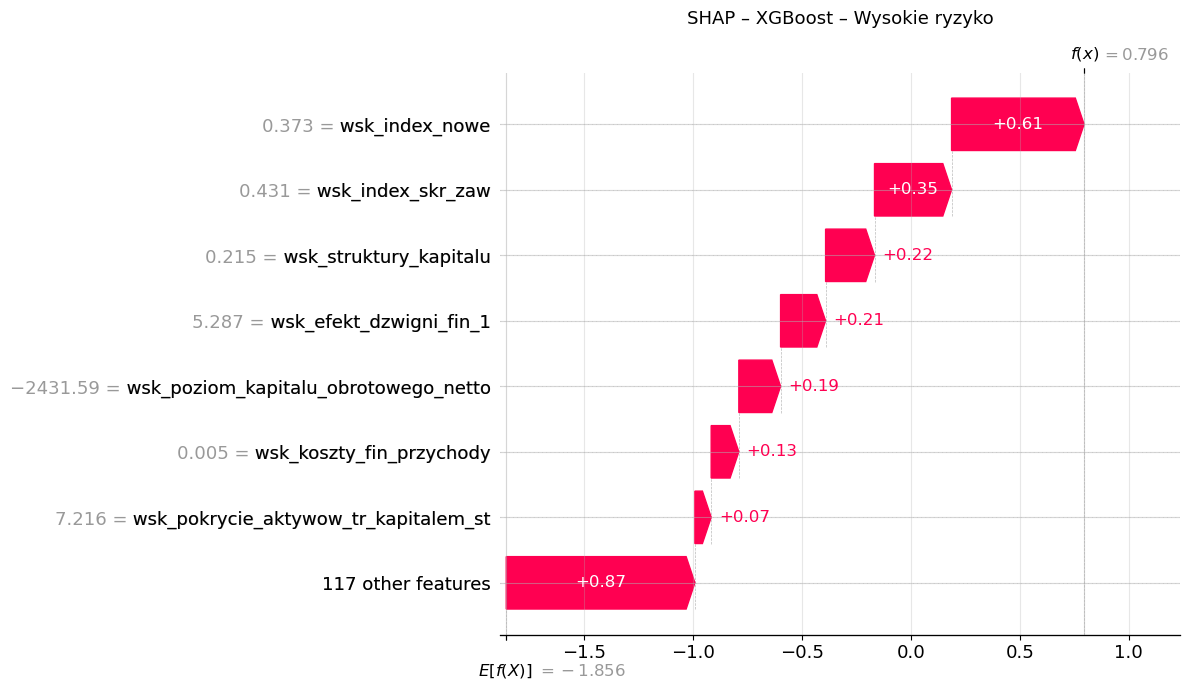


Najważniejsze czynniki – XGBoost:


,wartość,SHAP,mnożnik szans e^φ,kierunek
wsk_index_nowe,0.3726,0.6080,1.8400,podnosi ryzyko
wsk_index_skr_zaw,0.4309,0.3540,1.4200,podnosi ryzyko
wsk_struktury_kapitalu,0.2149,0.2240,1.2500,podnosi ryzyko
wsk_efekt_dzwigni_fin_1,5.2866,0.2070,1.2300,podnosi ryzyko
wsk_poziom_kapitalu_obrotowego_netto,-2431.5900,0.1920,1.2100,podnosi ryzyko
wsk_koszty_fin_przychody,0.0049,0.1270,1.1400,podnosi ryzyko



Najważniejsze czynniki – regresja logistyczna:


,wartość,SHAP (logit),mnożnik szans e^φ
wsk_index_skr_zaw,0.4309,0.3950,1.4800
wsk_index_nowe,0.3726,0.2770,1.3200
wsk_ROE_brutto,-0.5273,0.0790,1.0800
wsk_ebitda_aktywa_2,-0.0997,0.0610,1.0600
wsk_zadluzenia_krotkie,4.6532,0.0500,1.0500
wsk_zast_kapitalu_podstawowego,8.1553,-0.0170,0.9800



Niskie ryzyko | obserwacja: 2328 | PD_XGB: 0.63% | PD_LR: 7.36% | faktyczny default: 0


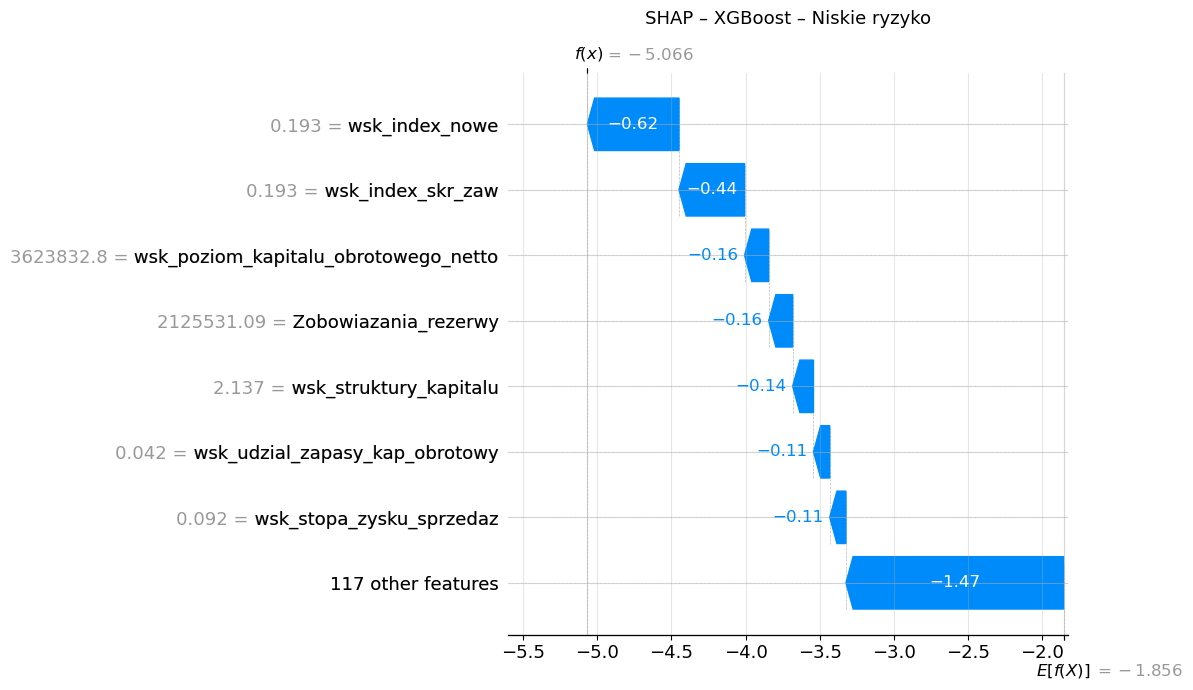


Najważniejsze czynniki – XGBoost:


,wartość,SHAP,mnożnik szans e^φ,kierunek
wsk_index_nowe,0.1930,-0.6180,0.5400,obniża ryzyko
wsk_index_skr_zaw,0.1930,-0.4420,0.6400,obniża ryzyko
wsk_poziom_kapitalu_obrotowego_netto,3623832.8000,-0.1630,0.8500,obniża ryzyko
Zobowiazania_rezerwy,2125531.0900,-0.1620,0.8500,obniża ryzyko
wsk_struktury_kapitalu,2.1370,-0.1400,0.8700,obniża ryzyko
wsk_udzial_zapasy_kap_obrotowy,0.0420,-0.1090,0.9000,obniża ryzyko



Najważniejsze czynniki – regresja logistyczna:


,wartość,SHAP (logit),mnożnik szans e^φ
wsk_index_nowe,0.1930,-0.2320,0.7900
wsk_index_skr_zaw,0.1930,-0.2200,0.8000
Zysk_netto,1009570.5600,-0.0700,0.9300
wsk_ebitda_aktywa_2,0.2645,-0.0570,0.9400
wsk_ROE_brutto,0.2692,-0.0510,0.9500
wsk_zadluzenia_krotkie,0.3004,-0.0320,0.9700



Graniczny (blisko progu) | obserwacja: 355 | PD_XGB: 10.66% | PD_LR: 17.91% | faktyczny default: 1


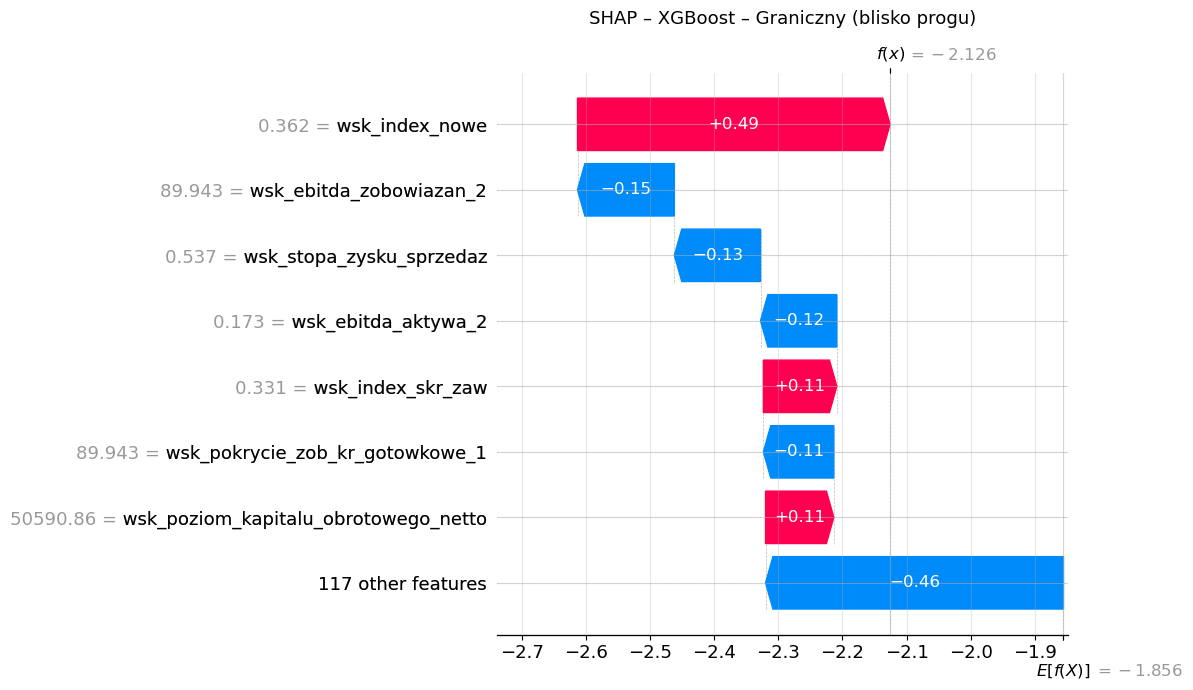


Najważniejsze czynniki – XGBoost:


,wartość,SHAP,mnożnik szans e^φ,kierunek
wsk_index_nowe,0.3615,0.4870,1.6300,podnosi ryzyko
wsk_ebitda_zobowiazan_2,89.9430,-0.1510,0.8600,obniża ryzyko
wsk_stopa_zysku_sprzedaz,0.5366,-0.1340,0.8700,obniża ryzyko
wsk_ebitda_aktywa_2,0.1726,-0.1190,0.8900,obniża ryzyko
wsk_index_skr_zaw,0.3312,0.1140,1.1200,podnosi ryzyko
wsk_pokrycie_zob_kr_gotowkowe_1,89.9430,-0.1100,0.9000,obniża ryzyko



Najważniejsze czynniki – regresja logistyczna:


,wartość,SHAP (logit),mnożnik szans e^φ
wsk_index_nowe,0.3615,0.2460,1.2800
wsk_index_skr_zaw,0.3312,0.1370,1.1500
wsk_zadluzenia_krotkie,0.0000,-0.0380,0.9600
wsk_ROE_brutto,0.1287,-0.0280,0.9700
wsk_ebitda_aktywa_2,0.1726,-0.0270,0.9700
wsk_zast_kapitalu_podstawowego,32.8082,-0.0140,0.9900



Rozbieżność LR vs XGB | obserwacja: 1089 | PD_XGB: 3.37% | PD_LR: 23.48% | faktyczny default: 0


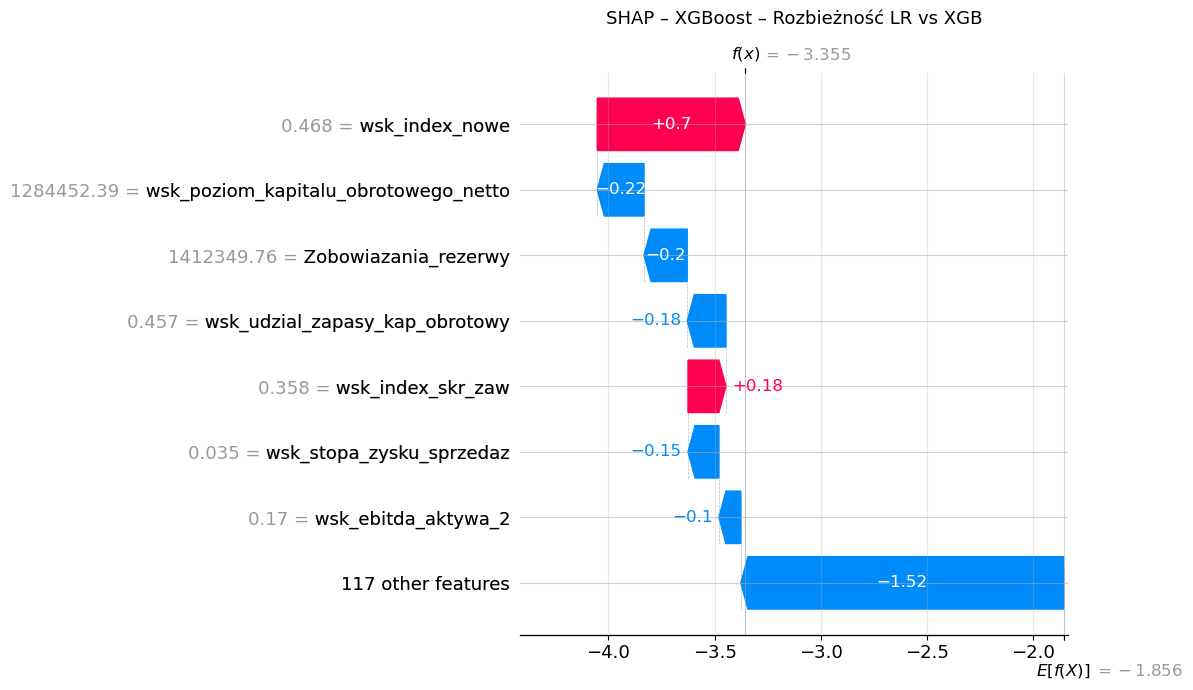


Najważniejsze czynniki – XGBoost:


,wartość,SHAP,mnożnik szans e^φ,kierunek
wsk_index_nowe,0.4682,0.6970,2.0100,podnosi ryzyko
wsk_poziom_kapitalu_obrotowego_netto,1284452.3900,-0.2200,0.8000,obniża ryzyko
Zobowiazania_rezerwy,1412349.7600,-0.2040,0.8200,obniża ryzyko
wsk_udzial_zapasy_kap_obrotowy,0.4567,-0.1820,0.8300,obniża ryzyko
wsk_index_skr_zaw,0.3580,0.1790,1.2000,podnosi ryzyko
wsk_stopa_zysku_sprzedaz,0.0351,-0.1450,0.8600,obniża ryzyko



Najważniejsze czynniki – regresja logistyczna:


,wartość,SHAP (logit),mnożnik szans e^φ
wsk_index_nowe,0.4682,0.5480,1.7300
wsk_index_skr_zaw,0.3580,0.2070,1.2300
wsk_ROE_brutto,0.1713,-0.0350,0.9700
wsk_ebitda_aktywa_2,0.1705,-0.0260,0.9700
wsk_zadluzenia_krotkie,0.7741,-0.0230,0.9800
wsk_zast_kapitalu_podstawowego,0.2777,-0.0180,0.9800


In [36]:
from scipy.stats import rankdata

# Próg klasyfikacji wyznaczony na podstawie krzywej ROC
fpr, tpr, thresholds = roc_curve(y_val, pv_xgb)
th_x = thresholds[np.argmax(tpr - fpr)]

# Pozycje obserwacji w rankingach ryzyka
rk_l = rankdata(pv_lr) / len(pv_lr)
rk_x = rankdata(pv_xgb) / len(pv_xgb)

# Wybór czterech interesujących przypadków
case_pos = {
    "Wysokie ryzyko": int(np.argmax(pv_xgb)),
    "Niskie ryzyko": int(np.argmin(pv_xgb)),
    "Graniczny (blisko progu)": int(np.argmin(np.abs(pv_xgb - th_x))),
    "Rozbieżność LR vs XGB": int(np.argmax(np.abs(rk_l - rk_x)))
}


# Czynniki wpływające na predykcję XGBoost
def powody_xgb(i, top=6):
    s = pd.Series(PHI_X[i], index=SRC_X)
    s = s.reindex(s.abs().sort_values(ascending=False).index)

    return pd.DataFrame({
        "wartość": X_val.iloc[i][s.index].to_numpy(),
        "SHAP": s.round(3).to_numpy(),
        "mnożnik szans e^φ": np.exp(s).round(2).to_numpy(),
        "kierunek": np.where(
            s > 0,
            "podnosi ryzyko",
            "obniża ryzyko"
        )
    }, index=s.index).head(top)


# Czynniki wpływające na predykcję regresji logistycznej
def powody_lr(i, top=6):
    s = PHI_L_val.iloc[i]
    s = s.reindex(s.abs().sort_values(ascending=False).index)

    return pd.DataFrame({
        "wartość": X_val.iloc[i][s.index].to_numpy(),
        "SHAP (logit)": s.round(3).to_numpy(),
        "mnożnik szans e^φ": np.exp(s).round(2).to_numpy()
    }, index=s.index).head(top)


# Analiza i wizualizacja każdego przypadku osobno
for name, i in case_pos.items():

    print("\n" + "=" * 90)
    print(
        f"{name} | obserwacja: {X_val.index[i]} | "
        f"PD_XGB: {pv_xgb[i]:.2%} | "
        f"PD_LR: {pv_lr[i]:.2%} | "
        f"faktyczny default: {int(y_val.iloc[i])}"
    )
    print("=" * 90)

    # Wykres SHAP dla XGBoost
    exp = shap.Explanation(
        values=PHI_X[i],
        base_values=BASE_X,
        data=dane_kol[i],
        feature_names=SRC_X
    )

    shap.plots.waterfall(
        exp,
        max_display=8,
        show=False
    )

    fig = plt.gcf()
    fig.set_size_inches(12, 7)
    plt.title(f"SHAP – XGBoost – {name}", fontsize=13, pad=15)
    plt.tight_layout()
    plt.show()
    plt.close(fig)

    # Tabela przyczyn dla XGBoost
    print("\nNajważniejsze czynniki – XGBoost:")
    display(powody_xgb(i))

    # Tabela przyczyn dla regresji logistycznej
    print("\nNajważniejsze czynniki – regresja logistyczna:")
    display(powody_lr(i))

### Komentarz do studiów przypadków

#### 1. Przypadek wysokiego ryzyka (PD_XGB: 68.90% | PD_LR: 27.84% | faktyczny default: 1)
* **Czynniki podnoszące ryzyko:** w głównej mierze podwyższone indeksy rotacji branży.
* **Czynniki obniżające ryzyko:** brak istotnych czynników ochronnych.
* **Zgodność modeli (XGBoost vs LR):** Oba modele są zgodne co do kierunku oceny oraz głównych czynników ryzyka, przy czym XGBoost silniej karze spółkę za przekroczenie nieliniowych progów zadłużenia i struktury kapitału (zmiennych wyzerowanych przez regularyzację L1 w LR).
* **Decyzja operacyjna:** **Odrzucenie wniosku**

---

#### 2. Przypadek niskiego ryzyka (PD_XGB: 0.63% | PD_LR: 7.36% | faktyczny default: 0)
* **Czynniki podnoszące ryzyko:** brak lub pojedyncze czynniki o marginalnym wpływie.
* **Czynniki obniżające ryzyko:** głównie niski poziom indeksów ryzyka otoczenia rynkowego.
* **Zgodność modeli (XGBoost vs LR):** Pełna zgodność – oba modele oceniają spółkę jako bardzo bezpieczną.
* **Decyzja operacyjna:** **Automatyczna akceptacja** – profil ryzyka pozwala na udzielenie finansowania w uproszczonej ścieżce decyzyjnej.

---

#### 3. Przypadek graniczny – blisko progu Youdena (PD_XGB: 10.66% | PD_LR: 17.91% | faktyczny default: 1)
* **Czynniki podnoszące ryzyko:** wysoka dynamika rynku i ryzyko otoczenia sektorowego – przede wszystkim wysoki wskaźnik nowych podmiotów oraz odsetek podmiotów skreślonych/zawieszonych. Łącznie te dwa czynniki podbijają log-szanse o ok. $+0,6$.
* **Czynniki obniżające ryzyko:** głównie wysoka rentowność sprzedaży, wysokie pokrycie zobowiązań przez EBITDA i zdrowa relacja EBITDA do aktywów.
* **Zgodność modeli (XGBoost vs LR):** Oba modele identyfikują identyczny konflikt ekonomiczny: niekorzystne otoczenie rynkowe kontra zdrowe wskaźniki wewnętrzne spółki. Różnica polega na sile wag: w XGBoost wewnętrzne bufory finansowe (wyzerowane przez karę L1 w LR) równoważą presję rynkową, sytuując spółkę na granicy decyzyjnej.
* **Decyzja operacyjna i propozycja strefy buforowej:** **Ręczna weryfikacja analityka**. Proponujemy wdrożenie strefy „do weryfikacji” wokół progu Youdena (np. ok. `11% – 17%` PD). Wnioski w tym paśmie powinny trafiać do pogłębionej oceny eksperckiej.

---

#### 4. Przypadek największej rozbieżności modeli (PD_XGB: 3.37% | PD_LR: 23.48% | faktyczny default: 0)
* **Czynniki podnoszące / obniżające ryzyko:** 
  * W **XGBoost** silną presję ryzyka generują indeksy otoczenia, jednak jest ona z nadwyżką neutralizowana przez silne bufory bilansowe i skalę działalności spółki.
  * W **Regresji Logistycznej** dominują niemal wyłącznie czynniki podwyższające ryzyko, podczas gdy czynniki ochronne mają mały wpływ.
* **Źródło rozbieżności modeli:** Rozjazd wynika bezpośrednio z selekcji zmiennych przez regularyzację L1 oraz nieliniowości drzew. Kara L1 w Regresji Logistycznej całkowicie wyzerowała kluczowe bufory ochronne tej spółki, a XGBoost uwzględnił te zmienne oraz ich nieliniowe progi, rozpoznając, że duża i płynna spółka jest odporna na turbulencje sektorowe.
* **Decyzja operacyjna:** **Ręczna weryfikacja**

#### Zasady komunikacji z klientem
* **Czynniki komunikowane klientowi:** wskaźniki płynności i kapitału obrotowego (`wsk_poziom_kapitalu_obrotowego_netto`, `wsk_udzial_zapasy_kap_obrotowy`), poziom zadłużenia i struktura finansowania (`wsk_struktury_kapitalu`, `wsk_koszty_fin_przychody`) oraz zdolność generowania gotówki na obsługę długu (`wsk_ebitda_zobowiazan_2`).
* **Czynniki pomijane w piśmie do klienta:** kod branży (`pkdKod`), forma prawna, staż działalności (`wsk_liczba_dni_istnienia`) oraz zagregowane indeksy demografii rynkowej (`wsk_index_nowe`, `wsk_index_skr_zaw`, `wsk_index_aktywne`), ponieważ przedsiębiorca nie ma na nie wpływu i nie może podjąć działań naprawczych w tym zakresie.

## 6.4 Kształt zależności: PDP, ICE, ALE i kontrola monotoniczności

Wszystkie wykresy w tej sekcji używają surowych wartości cech i log-szans, dzięki czemu LR i XGBoost są porównywalne. Siatki PDP pochodzą z kwantyli 2–98% cechy na `train`; jako tło do uśredniania wykorzystujemy `val`. Cechy wybieramy według średniego |SHAP| XGBoost, ograniczając wykresy jednowymiarowe do cech numerycznych.

Interpretacja ostrożna: cechy `wsk_index_*` mogą dominować ranking SHAP, ale ich wzory nie mają prostego znaczenia ekonomicznego. Podstawienie wartości surowej cechy powoduje, że pipeline ustawia jej wskaźnik braku danych na 0; dotyczy to m.in. `wsk_plynnosc_biez_1` (dużo braków), dlatego krzywe dla takich cech opisują scenariusz bez braku. PDP pokazuje średni efekt modelowy, nie efekt przyczynowy.


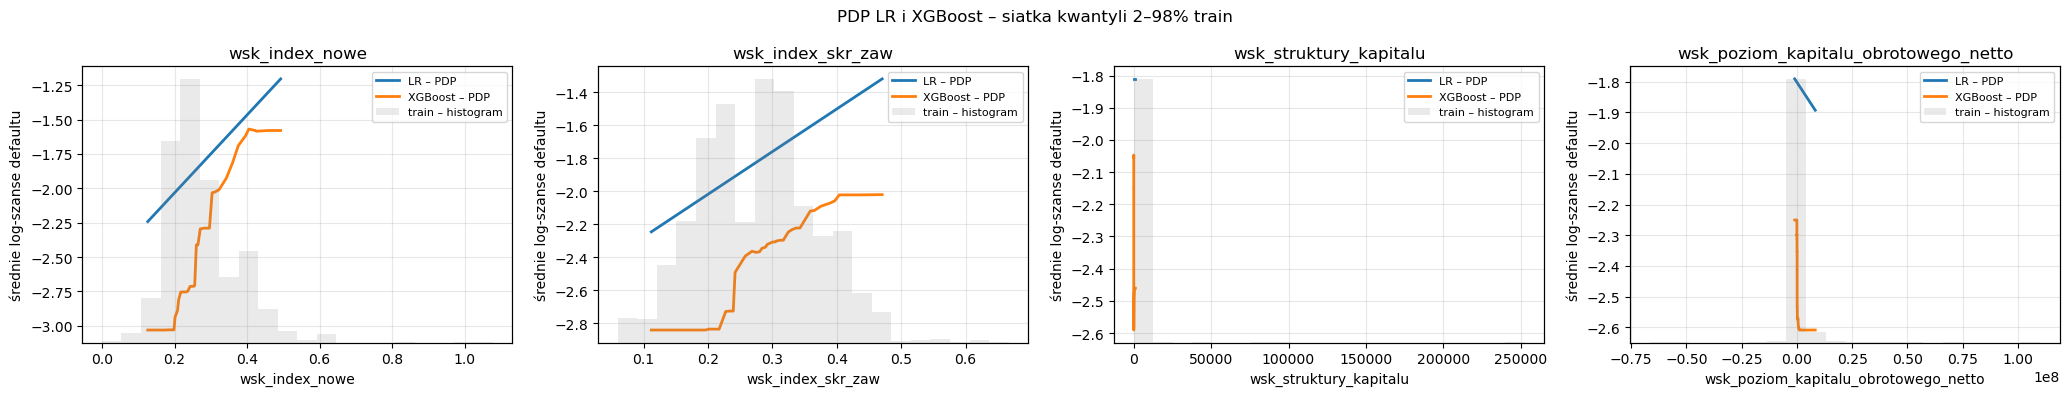

Top cechy wg SHAP: ['wsk_index_nowe', 'wsk_index_skr_zaw', 'wsk_struktury_kapitalu', 'wsk_poziom_kapitalu_obrotowego_netto']
Uwaga: dla wsk_index_* kształt jest widoczny, ale wskaźniki indeksowe nie mają tu prostej interpretacji ekonomicznej.


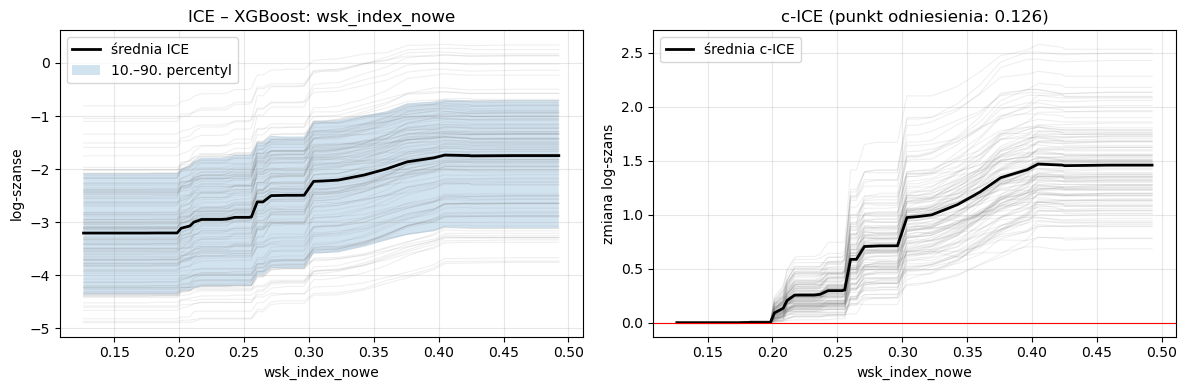

Rozrzut ICE (10.–90. percentyl) wzdłuż siatki:


,wartość cechy,ICE p10,ICE p90,rozstęp p90-p10
0,0.1263,-4.3588,-2.0864,2.2724
1,0.1520,-4.3588,-2.0864,2.2724
2,0.1645,-4.3588,-2.0864,2.2724
3,0.1738,-4.3588,-2.0864,2.2724
4,0.1832,-4.3588,-2.0805,2.2783
5,0.1886,-4.3588,-2.0805,2.2783
6,0.1960,-4.3588,-2.0805,2.2783
7,0.1984,-4.3588,-2.0805,2.2783
8,0.2015,-4.2878,-1.9979,2.2899
9,0.2082,-4.2728,-1.9331,2.3397


Rozrzut wkładu SHAP p90-p10: 1.4587


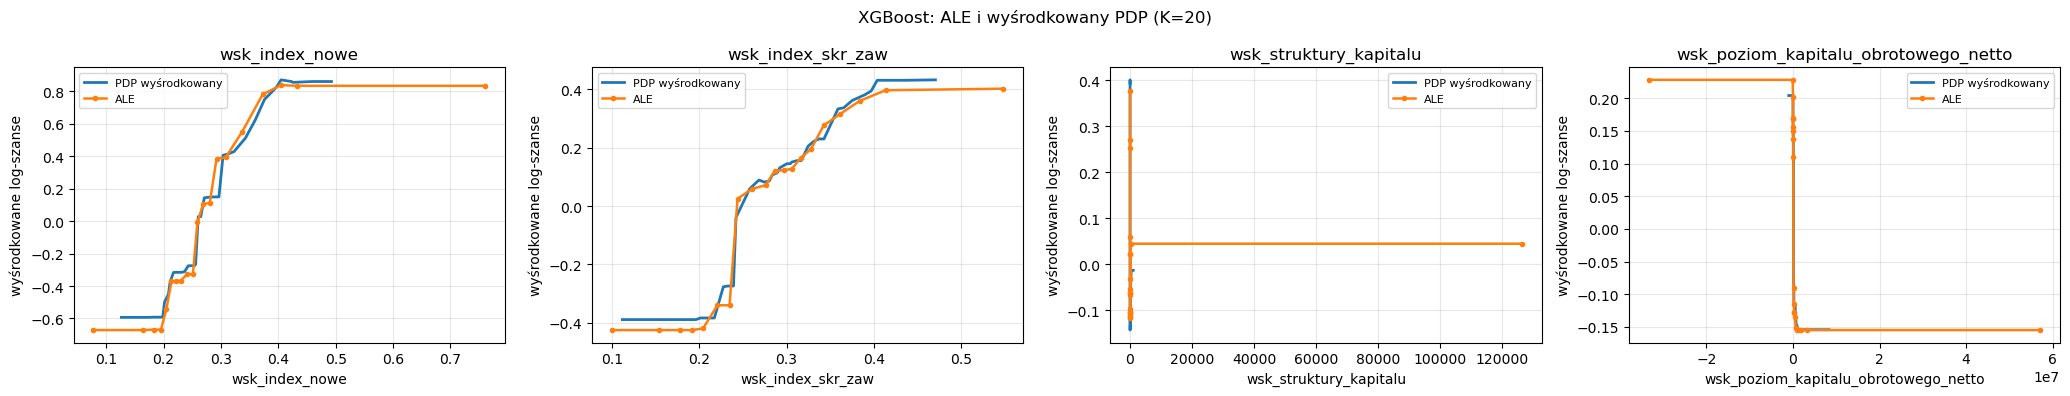

Porównanie PDP–ALE:


,max|PDP-ALE|,zakres,max|PDP-ALE| / zakres,min. liczebność przedziału
cecha,,,,
wsk_index_nowe,0.2362,1.5404,0.1533,14
wsk_index_skr_zaw,0.0658,0.8560,0.0769,18
wsk_struktury_kapitalu,0.1899,0.5350,0.3550,21
wsk_poziom_kapitalu_obrotowego_netto,0.0803,0.3830,0.2097,18


Korelacja Spearmana wybranych cech (val):


,wsk_index_nowe,wsk_index_skr_zaw,wsk_struktury_kapitalu,wsk_poziom_kapitalu_obrotowego_netto
wsk_index_nowe,1.0000,0.6500,-0.0300,-0.1400
wsk_index_skr_zaw,0.6500,1.0000,-0.0100,-0.1700
wsk_struktury_kapitalu,-0.0300,-0.0100,1.0000,0.0100
wsk_poziom_kapitalu_obrotowego_netto,-0.1400,-0.1700,0.0100,1.0000


Bootstrap ALE dla wsk_index_nowe (B=20); mniejsza zmienność i rozsądna liczebność przedziałów przemawiają za K=20:


,K,liczba przedziałów,min. liczebność (val),mediana SD ALE (bootstrap)
0,5,5,101,0.0222
1,20,20,14,0.0308
2,100,99,0,0.0418


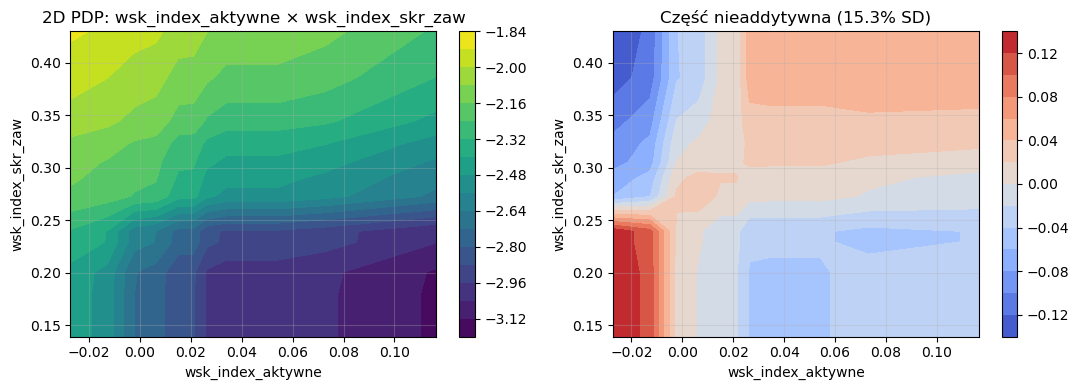

Para wsk_index_aktywne × wsk_index_skr_zaw: udział części nieaddytywnej = 0.153; pozycja w rankingu SHAP = 1


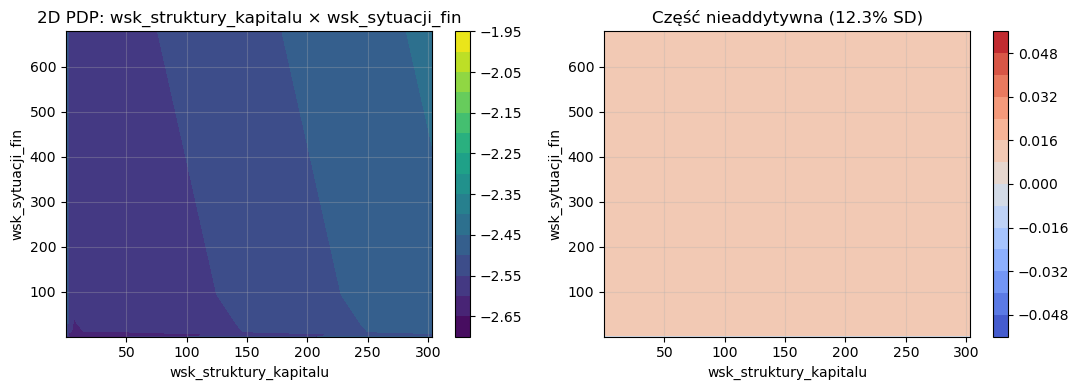

Para wsk_struktury_kapitalu × wsk_sytuacji_fin: udział części nieaddytywnej = 0.123; pozycja w rankingu SHAP = 12
Naruszenia monotoniczności PDP XGBoost (top cechy numeryczne wg SHAP z zadanym znakiem):


,cecha,oczekiwany znak,naruszenia,liczba kroków,udział naruszeń,zakres PDP,istotne (heurystyka)
7,wsk_pokrycie_aktywow_tr_kapitalem_st,-,14,29,0.4828,0.1997,True
2,wsk_liczba_dni_istnienia,-,12,29,0.4138,0.2129,True
13,wsk_rotacja_aktywow_2,-,7,22,0.3182,0.2684,True
14,wsk_ebitda_aktywa_3,-,8,26,0.3077,0.0918,False
18,wsk_pokrycie_aktywow_kap_stalym,-,8,29,0.2759,0.0718,False
11,wsk_rent_operacyjna,-,7,26,0.2692,0.2889,True
15,wsk_ebitda_zobowiazan_odsetki_3,-,6,26,0.2308,0.0945,False
8,wsk_zysk_operacyjny_zob_2,-,5,26,0.1923,0.1759,True
12,wsk_mnoznik_kap_wl,+,5,28,0.1786,0.1209,True
10,wsk_udzial_kap_wlasnego_aktywa_2,-,5,28,0.1786,0.1902,True


In [39]:
# Funkcje PDP/ALE w skali log-szans. Dane wejściowe pozostają surowe – pipeline wykonuje preprocessing.
def predict_logodds(pipe, X_raw):
    return logit(pipe.predict_proba(X_raw)[:, 1])

def _stack_grid(X_bg, feature, grid):
    """Jedna duża ramka: kopia tła dla każdej wartości siatki (jedno wywołanie pipeline'u zamiast wielu)."""
    parts = []
    for value in grid:
        xx = X_bg.copy(); xx[feature] = value; parts.append(xx)
    return pd.concat(parts, ignore_index=True)

def pdp_1d(pipe, X_bg, feature, grid):
    """PDP = średnia log-szans po podstawieniu kolejnych wartości cechy."""
    z = predict_logodds(pipe, _stack_grid(X_bg, feature, grid)).reshape(len(grid), len(X_bg))
    return z.mean(axis=1)

def ice_matrix(pipe, X_bg, feature, grid):
    """Wiersz = firma, kolumna = wartość cechy z siatki."""
    z = predict_logodds(pipe, _stack_grid(X_bg, feature, grid)).reshape(len(grid), len(X_bg))
    return z.T

# Parametry kosztu obliczeń (w trybie FAST mniejsze)
N_GRID_PDP = 20 if FAST else 40                   # punkty siatki PDP
N_MONO     = 10 if FAST else 20                   # ile cech w teście monotoniczności
K_LIST     = [5, 20] if FAST else [5, 20, 100]    # liczby przedziałów w bootstrapie ALE
pdp_xgb = {}                                       # cache krzywych PDP XGBoost (używane też w ALE i opisie kształtów)

# Top 4 numeryczne cechy według średniego |SHAP| (black-box).
top_shape = [f for f in shap_imp.index if f in NUM_COLS and f in X_train.columns][:4]
if len(top_shape) == 0:
    print("Brak numerycznych cech do PDP/ALE.")
else:
    pdp_grids = {}
    fig, axes = plt.subplots(1, len(top_shape), figsize=(5.2 * len(top_shape), 4), squeeze=False)
    for ax, feature in zip(axes[0], top_shape):
        train_values = X_train[feature].replace([np.inf, -np.inf], np.nan).dropna()
        grid = np.unique(train_values.quantile(np.linspace(.02, .98, N_GRID_PDP)).to_numpy())
        pdp_grids[feature] = grid
        ax.plot(grid, pdp_1d(best_lr, X_val, feature, grid), label="LR – PDP", lw=2)
        pdp_xgb[feature] = pdp_1d(best_xgb, X_val, feature, grid)
        ax.plot(grid, pdp_xgb[feature], label="XGBoost – PDP", lw=2)
        ax.set_xlabel(feature); ax.set_ylabel("średnie log-szanse defaultu")
        ax.set_title(feature)
        hist_ax = ax.twinx()
        hist_ax.hist(train_values, bins=20, density=True, alpha=.16, color="gray",
                     label="train – histogram")
        hist_ax.set_yticks([])
        lines, labels = ax.get_legend_handles_labels()
        hlines, hlabels = hist_ax.get_legend_handles_labels()
        ax.legend(lines + hlines, labels + hlabels, fontsize=8)
    plt.suptitle("PDP LR i XGBoost – siatka kwantyli 2–98% train")
    plt.tight_layout(); plt.show()
    print("Top cechy wg SHAP:", top_shape)
    print("Uwaga: dla wsk_index_* kształt jest widoczny, ale wskaźniki indeksowe nie mają tu prostej interpretacji ekonomicznej.")

# ICE i c-ICE dla cechy o największym rozrzucie SHAP (10.–90. percentyl wkładu).
ice_candidates = [f for f in top_shape if f in SRC_X]
if ice_candidates:
    shap_spread = {f: np.nanpercentile(PHI_X[:, SRC_X.index(f)], 90) -
                      np.nanpercentile(PHI_X[:, SRC_X.index(f)], 10)
                   for f in ice_candidates}
    ice_feature = max(shap_spread, key=shap_spread.get)
    grid = pdp_grids[ice_feature]
    # Umiarkowana liczba firm, żeby wykres pozostał czytelny i obliczenia szybkie.
    rng_ice = np.random.default_rng(SEED)
    take = rng_ice.choice(len(X_val), min(120, len(X_val)), replace=False)
    X_ice = X_val.iloc[take].copy()
    ICE = ice_matrix(best_xgb, X_ice, ice_feature, grid)
    # c-ICE: odejmujemy log-szanse przy bezpiecznym końcu siatki wg znaku oczekiwanego.
    sign = OCZEKIWANY_ZNAK.get(ice_feature, "?")
    safe_idx = -1 if sign == "-" else (0 if sign == "+" else 0)
    CICE = ICE - ICE[:, [safe_idx]]
    spread_ice = np.percentile(ICE, [10, 90], axis=0)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for curve in ICE:
        ax[0].plot(grid, curve, color="gray", alpha=.12, lw=.8)
    ax[0].plot(grid, ICE.mean(axis=0), color="black", lw=2, label="średnia ICE")
    ax[0].fill_between(grid, spread_ice[0], spread_ice[1], alpha=.2, label="10.–90. percentyl")
    ax[0].set_title(f"ICE – XGBoost: {ice_feature}"); ax[0].set_xlabel(ice_feature); ax[0].set_ylabel("log-szanse"); ax[0].legend()
    for curve in CICE:
        ax[1].plot(grid, curve, color="gray", alpha=.12, lw=.8)
    ax[1].plot(grid, CICE.mean(axis=0), color="black", lw=2, label="średnia c-ICE")
    ax[1].axhline(0, color="red", lw=.8)
    ax[1].set_title(f"c-ICE (punkt odniesienia: {grid[safe_idx]:.3g})")
    ax[1].set_xlabel(ice_feature); ax[1].set_ylabel("zmiana log-szans"); ax[1].legend()
    plt.tight_layout(); plt.show()
    print("Rozrzut ICE (10.–90. percentyl) wzdłuż siatki:")
    display(pd.DataFrame({"wartość cechy": grid, "ICE p10": spread_ice[0],
                          "ICE p90": spread_ice[1], "rozstęp p90-p10": spread_ice[1]-spread_ice[0]}).round(4))
    print("Rozrzut wkładu SHAP p90-p10:", round(shap_spread[ice_feature], 4))

# ALE: kwantylowe przedziały, lokalne różnice predykcji, kumulacja i centrowanie.
def ale_1d(pipe, X_bg, feature, edges):
    edges = np.unique(np.asarray(edges, float))
    K = len(edges) - 1
    local = np.zeros(K); counts = np.zeros(K, dtype=int)
    x = X_bg[feature].to_numpy(float)
    valid = np.isfinite(x)
    # Przedziały [edge_k, edge_{k+1}], ostatni prawostronnie domknięty.
    bins = np.clip(np.digitize(np.nan_to_num(x, nan=edges[0]), edges[1:-1], right=True), 0, K - 1)
    parts_lo, parts_hi, ks = [], [], []
    for k in range(K):
        mask = (bins == k) & valid
        counts[k] = int(mask.sum())
        if counts[k] == 0:
            continue
        lo, hi = edges[k], edges[k + 1]
        x_lo, x_hi = X_bg.loc[mask].copy(), X_bg.loc[mask].copy()
        x_lo[feature] = lo; x_hi[feature] = hi
        parts_lo.append(x_lo); parts_hi.append(x_hi); ks.append(k)
    if ks:                                          # jedna predykcja dla wszystkich przedziałów
        n_tot = sum(len(p) for p in parts_lo)
        pr = predict_logodds(pipe, pd.concat(parts_lo + parts_hi, ignore_index=True))
        diff = pr[n_tot:] - pr[:n_tot]
        offs = np.cumsum([0] + [len(p) for p in parts_lo])
        for t, k in enumerate(ks):
            local[k] = diff[offs[t]:offs[t + 1]].mean()
    ale = np.cumsum(local)
    # Centerowanie ważone liczebnością obserwacji w przedziałach.
    centers = (edges[:-1] + edges[1:]) / 2
    if counts.sum():
        ale = ale - np.average(ale, weights=np.maximum(counts, 1))
    return centers, ale, counts

ale_rows = []
if top_shape:
    n_bins_ale = 20
    fig, axes = plt.subplots(1, len(top_shape), figsize=(5.2 * len(top_shape), 4), squeeze=False)
    for ax, feature in zip(axes[0], top_shape):
        vals = X_train[feature].replace([np.inf, -np.inf], np.nan).dropna()
        edges = np.unique(vals.quantile(np.linspace(0, 1, n_bins_ale + 1)).to_numpy())
        centers, ale_vals, counts = ale_1d(best_xgb, X_val, feature, edges)
        grid = pdp_grids[feature]
        pdp_vals = pdp_xgb[feature]
        pdp_centered = pdp_vals - np.mean(pdp_vals)
        ax.plot(grid, pdp_centered, label="PDP wyśrodkowany", lw=2)
        ax.plot(centers, ale_vals, marker="o", ms=3, label="ALE", lw=1.8)
        ax.set_title(feature); ax.set_xlabel(feature); ax.set_ylabel("wyśrodkowane log-szanse")
        ax.legend(fontsize=8)
        # Porównanie na punktach ALE: interpolujemy wyśrodkowany PDP.
        pdp_at_ale = np.interp(centers, grid, pdp_centered)
        max_diff = float(np.max(np.abs(pdp_at_ale - ale_vals)))
        value_range = float(np.ptp(np.r_[pdp_at_ale, ale_vals]))
        ale_rows.append({"cecha": feature, "max|PDP-ALE|": max_diff,
                         "zakres": value_range,
                         "max|PDP-ALE| / zakres": max_diff / value_range if value_range > 1e-12 else np.nan,
                         "min. liczebność przedziału": int(counts.min())})
    plt.suptitle("XGBoost: ALE i wyśrodkowany PDP (K=20)")
    plt.tight_layout(); plt.show()
    print("Porównanie PDP–ALE:")
    display(pd.DataFrame(ale_rows).set_index("cecha").round(4))

# Korelacje Spearmana wybranych cech – pomagają ocenić, gdzie PDP może ekstrapolować.
corr_feats = [f for f in top_shape if f in X_val.columns]
if len(corr_feats) >= 2:
    print("Korelacja Spearmana wybranych cech (val):")
    display(X_val[corr_feats].corr(method="spearman").round(2))

# Krótki bootstrap: stabilność ALE dla K=5, 20, 100 (stałe granice z train).
# Miarą jest mediana odchylenia standardowego punktowych krzywych ALE między replikacjami.
def ale_bootstrap_stability(pipe, X_ref, X_bg, feature, K, B=20, seed=SEED):
    vals = X_ref[feature].replace([np.inf, -np.inf], np.nan).dropna()
    edges = np.unique(vals.quantile(np.linspace(0, 1, K + 1)).to_numpy())
    rng = np.random.default_rng(seed)
    curves = []
    for _ in range(B):
        ids = rng.integers(0, len(X_bg), len(X_bg))
        centers, curve, counts = ale_1d(pipe, X_bg.iloc[ids], feature, edges)
        curves.append(curve)
    curves = np.asarray(curves)
    return {"K": K, "liczba przedziałów": len(edges)-1,
            "min. liczebność (val)": int(ale_1d(pipe, X_bg, feature, edges)[2].min()),
            "mediana SD ALE (bootstrap)": float(np.nanmedian(np.std(curves, axis=0)))}

if ice_candidates:
    B_ALE = 10 if FAST else 20
    boot_k = pd.DataFrame([ale_bootstrap_stability(best_xgb, X_train, X_val, ice_feature, K, B=B_ALE)
                           for K in K_LIST])
    print(f"Bootstrap ALE dla {ice_feature} (B={B_ALE}); mniejsza zmienność i rozsądna liczebność przedziałów przemawiają za K=20:")
    display(boot_k.round(4))

# 2D PDP dla par z rankingu interakcji SHAP.
# Bierzemy najsilniejszą parę oraz pierwszą parę z cechami opisowymi (bez wsk_index_*).
pair_list = []
if len(pary_int):
    first_pair = tuple(pary_int.iloc[0][["cecha 1", "cecha 2"]])
    pair_list.append(first_pair)
    descriptive = pary_int[
        (~pary_int["cecha 1"].str.contains("index", case=False, na=False)) &
        (~pary_int["cecha 2"].str.contains("index", case=False, na=False))
    ]
    if len(descriptive):
        p2 = tuple(descriptive.iloc[0][["cecha 1", "cecha 2"]])
        if p2 not in pair_list:
            pair_list.append(p2)
pair_list = [p for p in pair_list if p[0] in X_train.columns and p[1] in X_train.columns
             and p[0] in NUM_COLS and p[1] in NUM_COLS][:2]

def pdp_2d(pipe, X_bg, f1, f2, g1, g2):
    # Uśredniamy po tej samej próbie tła dla każdej pary punktów siatki (jedna predykcja dla całej siatki).
    parts = []
    for v1 in g1:
        for v2 in g2:
            xx = X_bg.copy(); xx[f1] = v1; xx[f2] = v2; parts.append(xx)
    z = predict_logodds(pipe, pd.concat(parts, ignore_index=True))
    return z.reshape(len(g1), len(g2), len(X_bg)).mean(axis=2)

for f1, f2 in pair_list:
    v1 = X_train[f1].replace([np.inf, -np.inf], np.nan).dropna()
    v2 = X_train[f2].replace([np.inf, -np.inf], np.nan).dropna()
    g1 = np.unique(v1.quantile(np.linspace(.05, .95, 12)).to_numpy())
    g2 = np.unique(v2.quantile(np.linspace(.05, .95, 12)).to_numpy())
    Z = pdp_2d(best_xgb, X_val.sample(min(200, len(X_val)), random_state=SEED), f1, f2, g1, g2)
    additive = Z.mean() + (Z.mean(axis=1)[:, None] - Z.mean()) + (Z.mean(axis=0)[None, :] - Z.mean())
    nonadd = Z - additive
    share = float(np.std(nonadd) / np.std(Z)) if np.std(Z) > 1e-12 else np.nan
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    c0 = ax[0].contourf(g1, g2, Z.T, levels=15); fig.colorbar(c0, ax=ax[0])
    ax[0].set_title(f"2D PDP: {f1} × {f2}"); ax[0].set_xlabel(f1); ax[0].set_ylabel(f2)
    c1 = ax[1].contourf(g1, g2, nonadd.T, levels=15, cmap="coolwarm"); fig.colorbar(c1, ax=ax[1])
    ax[1].set_title(f"Część nieaddytywna ({share:.1%} SD)"); ax[1].set_xlabel(f1); ax[1].set_ylabel(f2)
    plt.tight_layout(); plt.show()
    print(f"Para {f1} × {f2}: udział części nieaddytywnej = {share:.3f}; pozycja w rankingu SHAP =",
          int(pary_int.index[(pary_int["cecha 1"] == f1) & (pary_int["cecha 2"] == f2)][0]) if ((pary_int["cecha 1"] == f1) & (pary_int["cecha 2"] == f2)).any() else "brak")

# Monotoniczność PDP XGBoost względem hipotez OCZEKIWANY_ZNAK.
# Znak +: krzywa powinna być niemalejąca; znak -: nierosnąca.
mono_rows = []
mono_features = []
mono_candidates = [f for f in shap_imp.index if f in NUM_COLS and f in OCZEKIWANY_ZNAK][:N_MONO]
for feature in mono_candidates:
    sign = OCZEKIWANY_ZNAK.get(feature, "?")
    if feature not in X_train.columns or sign not in ("+", "-"):
        continue
    vals = X_train[feature].replace([np.inf, -np.inf], np.nan).dropna()
    if vals.nunique() < 5:
        continue
    grid_m = np.unique(vals.quantile(np.linspace(.02, .98, 30)).to_numpy())
    if len(grid_m) < 3:
        continue
    curve = pdp_1d(best_xgb, X_val, feature, grid_m)
    dif = np.diff(curve)
    violations = int(np.sum(dif < -1e-8)) if sign == "+" else int(np.sum(dif > 1e-8))
    mono_rows.append({"cecha": feature, "oczekiwany znak": sign,
                      "naruszenia": violations, "liczba kroków": len(dif),
                      "udział naruszeń": violations / max(len(dif), 1),
                      "zakres PDP": float(np.ptp(curve))})
    mono_features.append(feature)
mono_tab = pd.DataFrame(mono_rows, columns=["cecha", "oczekiwany znak", "naruszenia",
                                               "liczba kroków", "udział naruszeń", "zakres PDP"])
if len(mono_tab):
    mono_tab = mono_tab.sort_values("udział naruszeń", ascending=False)
    mono_tab["istotne (heurystyka)"] = (mono_tab["udział naruszeń"] >= 0.10) & (mono_tab["zakres PDP"] >= 0.10)
print("Naruszenia monotoniczności PDP XGBoost (top cechy numeryczne wg SHAP z zadanym znakiem):")
display(mono_tab.head(25).round(4))
# Krótki opis kształtów do Model Card – kierunek i ewentualna nieliniowość PDP XGBoost.
shape_notes = []
for feature in top_shape[:3]:
    curve = pdp_xgb[feature]
    rho_shape = spearmanr(pdp_grids[feature], curve)[0]
    dcurve = np.diff(curve)
    changes = np.sum(np.sign(dcurve[1:]) != np.sign(dcurve[:-1]))
    direction = "rosnący" if rho_shape > .35 else ("malejący" if rho_shape < -.35 else "bez prostego trendu monotonicznego")
    form = "z widocznym załamaniem/nieliniowością" if changes >= 2 else "w przybliżeniu gładki"
    shape_notes.append(f"{feature}: {direction}, {form}")
INTERPRETABILITY_TEXT = (
    "PDP XGBoost dla najważniejszych cech: " + "; ".join(shape_notes) + ". "
    "ICE pokazuje zróżnicowanie wpływu między firmami, a ALE ogranicza wpływ korelacji cech względem PDP. "
    "Interpretacja wsk_index_* jest ograniczona ekonomicznie; przy cechach z brakami krzywa zakłada brak flagi NA."
)

## 7. LIME, wierność i stabilność wyjaśnień
Wyjaśnienia liczone na zbiorze walidacyjnym dla XGBoost. LIME działa w przestrzeni kolumn po przekształceniu, a jego wkłady sumujemy do cech źródłowych (tak jak SHAP).

In [ ]:
# LIME tabelaryczny (lime_tabular); parametry: ziarno, num_samples, kernel_width
def predict_fn_xgb(a): return xgb_clf.predict_proba(pd.DataFrame(a, columns=cols_x))
def make_lime(seed, kernel_width=None):
    return LimeTabularExplainer(Xt_tr_x.values, feature_names=cols_x, class_names=["ok", "default"], mode="classification",
                                discretize_continuous=False, sample_around_instance=True, kernel_width=kernel_width, random_state=seed)
def lime_run(expl, x, num_samples=LIME_N, predict_fn=None):          # predict_fn: domyślnie surowy XGBoost
    predict_fn = predict_fn_xgb if predict_fn is None else predict_fn
    e = expl.explain_instance(x, predict_fn, num_features=len(cols_x), num_samples=num_samples)
    w = np.zeros(len(cols_x))
    for i, v in e.local_exp[1]: w[i] = v
    contrib = w * (x - expl.scaler.mean_) / expl.scaler.scale_          # wkład względem średniej (porównywalny z SHAP)
    return w, contrib @ G_x, e                                          # wkłady zsumowane do cech źródłowych

case_idx = list(case_pos.values()); lime_expl = make_lime(SEED)
for name, i in case_pos.items():
    w, ctb, e = lime_run(lime_expl, Xt_va_x.iloc[i].values)
    top = pd.Series(ctb, index=SRC_X).sort_values(key=np.abs, ascending=False).head(6)
    print(f"[{name}] LIME: lokalne R²={e.score:.3f} | PD modelu={e.predict_proba[1]:.3f} | PD surogatu={e.local_pred[0]:.3f}"); print(top.round(4).to_string(), "\n")

[Wysokie ryzyko] LIME: lokalne R²=0.537 | PD modelu=0.689 | PD surogatu=0.215
wsk_index_nowe                          0.0178
wsk_index_skr_zaw                       0.0115
wsk_poziom_kapitalu_obrotowego_netto    0.0042
wsk_pokrycie_aktywow_tr_kapitalem_st   -0.0038
wsk_zast_kapitalu_podstawowego         -0.0038
wsk_udzial_kap_wlasnego_aktywa_2        0.0030 

[Niskie ryzyko] LIME: lokalne R²=0.597 | PD modelu=0.006 | PD surogatu=0.094
wsk_index_nowe                          -0.0122
wsk_index_skr_zaw                       -0.0104
wsk_index_aktywne                        0.0041
Naleznosci_dostaw_uslug_12m_powiazane    0.0039
Inne_zobowiazania_fin_dlugoterminowe     0.0033
formaWlasnosci_Symbol                    0.0032 

[Graniczny (blisko progu)] LIME: lokalne R²=0.628 | PD modelu=0.107 | PD surogatu=0.159
wsk_index_nowe                    0.0158
wsk_index_skr_zaw                 0.0087
wsk_liczba_dni_istnienia         -0.0059
wsk_struktura_kap_wlasnego_s_2    0.0042
wsk_zast_kapitalu_p

### 7.1 Wierność wyjaśnień
1. Lokalne R² surogatu LIME (ważone, w próbie sąsiedztwa) dla 15 obserwacji,
2. R² poza próbą – własny surogat liniowy (ridge, ważony jądrem odległości) dopasowany na 70% świeżego sąsiedztwa i oceniony na pozostałych 30%,
3. Addytywność SHAP (baza + Σφ = wyjście modelu).

In [43]:
def local_fidelity(predict_prob, x, X_ref, binary_mask, n=3000, width=0.5, seed=0):
    rng = np.random.default_rng(seed); sd = X_ref.std(0).values.copy(); sd[sd == 0] = 1; nb = ~binary_mask
    Z = np.tile(x, (n, 1)); Z[:, nb] += rng.normal(size=(n, nb.sum())) * sd[nb] * width        # cechy binarne (flagi/one-hot) stałe
    p = predict_prob(Z)[:, 1]; yl = logit(p)
    d = np.sqrt((((Z - x) / sd)[:, nb] ** 2).sum(1)); kw = 0.75 * np.sqrt(nb.sum()); w = np.exp(-d ** 2 / kw ** 2)
    Zs = (Z - x) / sd; tr = np.arange(n) < int(.7 * n); te = ~tr; out = {}
    for lab, tgt in [("logit", yl), ("prob", p)]:
        m = Ridge(alpha=1.0).fit(Zs[tr][:, nb], tgt[tr], sample_weight=w[tr]); out[f"R2_poza_próbą_{lab}"] = r2_score(tgt[te], m.predict(Zs[te][:, nb]), sample_weight=w[te])
    return out

bin_mask = np.array([(Xt_tr_x[c].nunique() <= 2) for c in cols_x]); rng_ = np.random.default_rng(SEED)
pick = list(case_idx) + list(rng_.choice(len(Xt_va_x), 11, replace=False)); rows = []
for i in pick:
    w, ctb, e = lime_run(lime_expl, Xt_va_x.iloc[i].values); f = local_fidelity(predict_fn_xgb, Xt_va_x.iloc[i].values, Xt_tr_x, bin_mask, seed=int(i))
    rows.append({"obs": X_val.index[i], "PD_XGB": pv_xgb[i], "LIME_R2_w_próbie": e.score, "LIME_|PD_surogat-PD_model|": abs(e.local_pred[0] - e.predict_proba[1]), **f})
fid = pd.DataFrame(rows).set_index("obs"); print(fid.round(3))
print("\nPodsumowanie wierności (mediana / min):"); print(pd.DataFrame({"mediana": fid.median(), "min": fid.min()}).round(3))
print(f"\nSHAP: maks. błąd addytywności = {shap_add_err:.1e}")

      PD_XGB  LIME_R2_w_próbie  LIME_|PD_surogat-PD_model|  R2_poza_próbą_logit  R2_poza_próbą_prob
obs                                                                                                
246   0.6890            0.5470                      0.4770               0.5680              0.5620
2328  0.0060            0.5930                      0.0880               0.5970              0.5630
355   0.1070            0.6390                      0.0530               0.5800              0.5640
1089  0.0340            0.5770                      0.1390               0.5500              0.5220
2371  0.1760            0.6220                      0.0060               0.5660              0.5460
304   0.1440            0.6270                      0.0280               0.5800              0.5500
409   0.0090            0.6310                      0.0840               0.5820              0.5530
350   0.4090            0.5330                      0.2040               0.5300              0.5240


**Interpretacja wierności:** Uzyskane R2 jest umiarkowane (mediana 0,62), a błąd punktowy surogatu sięga nawet kilkudziesięciu punktów procentowych – wyjaśnienie liniowe jest więc niepełne i bywa mylące, co było widać wcześniej na wykresach progowych. Typowe przypadki problematyczne: obserwacje przy progach podziału drzew, cechy binarne (np. flagi braków danych) perturbowane w LIME jako ciągłe oraz silnie skorelowane cechy. Pod tym względem dokładny TreeSHAP (marginalny błąd addytywności) jest znacznie bardziej wiarygodny.

### 7.2 Stabilność wyjaśnień
* **(a) LIME** – wiele uruchomień (różne seedy) dla tej samej obserwacji: średnia parami korelacja Spearmana i Jaccard top-5.
* **(b) Stabilność rankingu ważności SHAP przy próbkowaniu obserwacji** (bootstrap wyjaśnianego zbioru, ten sam model) → niestabilność **metody/próbki**.
* **(c) Stabilność rankingu przy ponownym uczeniu modelu** na foldach CV (SHAP dla XGB i LR) → niestabilność **modelu**.

In [46]:
def pairwise_stats(M, k=5):
    A = M.values; sp, jc = [], []
    for a, b in itertools.combinations(range(len(A)), 2):
        sp.append(spearmanr(A[a], A[b])[0]); ta, tb = set(np.argsort(-np.abs(A[a]))[:k]), set(np.argsort(-np.abs(A[b]))[:k]); jc.append(len(ta & tb) / len(ta | tb))
    return float(np.nanmean(sp)), float(np.nanmean(jc))

rows = []; lime_sd = {}
for name, i in case_pos.items():
    W = pd.DataFrame([lime_run(make_lime(1000 + s), Xt_va_x.iloc[i].values)[1] for s in range(N_LIME_SEEDS)], columns=SRC_X)
    sp_, jc_ = pairwise_stats(W, 5); top5 = W.abs().mean().sort_values(ascending=False).index[:5]
    rows.append({"obserwacja": name, "Spearman_śr": sp_, "Jaccard_top5_śr": jc_, "CV_wkładu_top5(std/|śr|)": float((W[top5].std() / W[top5].abs().mean()).mean())}); lime_sd[name] = W
print(f"(a) LIME – stabilność przy {N_LIME_SEEDS} seedach:"); print(pd.DataFrame(rows).set_index("obserwacja").round(3))
rows = []
for name, i in case_pos.items():
    s_ = pd.Series(PHI_X[i], index=SRC_X); l_ = lime_sd[name].mean(); ts, tl = set(s_.abs().nlargest(5).index), set(l_.abs().nlargest(5).index)
    rows.append({"obserwacja": name, "Spearman(|SHAP|,|LIME|)": spearmanr(s_.abs(), l_.abs())[0], "Jaccard_top5": len(ts & tl) / len(ts | tl)})
print("\nZgodność LIME vs SHAP (lokalnie):"); print(pd.DataFrame(rows).set_index("obserwacja").round(3))

(a) LIME – stabilność przy 20 seedach:
                          Spearman_śr  Jaccard_top5_śr  CV_wkładu_top5(std/|śr|)
obserwacja                                                                      
Wysokie ryzyko                 0.7970           0.6170                    0.0670
Niskie ryzyko                  0.6350           0.4370                    0.7620
Graniczny (blisko progu)       0.7350           0.5590                    0.5710
Rozbieżność LR vs XGB          0.7890           0.7650                    0.1090

Zgodność LIME vs SHAP (lokalnie):
                          Spearman(|SHAP|,|LIME|)  Jaccard_top5
obserwacja                                                     
Wysokie ryzyko                             0.7600        0.4290
Niskie ryzyko                              0.6410        0.4290
Graniczny (blisko progu)                   0.8540        0.2500
Rozbieżność LR vs XGB                      0.7400        0.2500


In [47]:
# (b) SHAP – bootstrap obserwacji wyjaśnianych (ten sam model)
rng_b = np.random.default_rng(SEED); B = 100 if not FAST else 30
imp_boot = pd.DataFrame([np.abs(PHI_X[rng_b.integers(0, len(PHI_X), len(PHI_X))]).mean(0) for _ in range(B)], columns=SRC_X)
sp_b, jc_b = pairwise_stats(imp_boot.iloc[:30], k=10)

# (c) Ponowne uczenie modeli na foldach CV
imp_x_f, imp_l_f = [], []
for a, b in cv.split(X_train, y_train, G_train):
    mx = clone(make_xgb().set_params(**xgb_search.best_params_)).fit(X_train.iloc[a], y_train.iloc[a])
    Xv_f = tdf(mx, X_val); Gf, srcf = grupy(list(Xv_f.columns)); s_f = shap.TreeExplainer(mx[-1])(Xv_f)
    imp_x_f.append(pd.Series(np.abs(s_f.values @ Gf).mean(0), index=srcf))
    ml = clone(make_lr().set_params(**chosen_params)).fit(X_train.iloc[a], y_train.iloc[a])
    imp_l_f.append(np.abs(shap_lr(ml, X_val, X_train.iloc[a])[0]).mean())
imp_x_f = pd.DataFrame(imp_x_f).fillna(0); imp_l_f = pd.DataFrame(imp_l_f).fillna(0)
sp_x, jc_x = pairwise_stats(imp_x_f, 10); sp_l, jc_l = pairwise_stats(imp_l_f, 10)
stab_tab = pd.DataFrame({"(b) SHAP-XGB, bootstrap obserwacji (metoda/próbka)": {"Spearman": sp_b, "Jaccard_top10": jc_b},
                         "(c) SHAP-XGB, refit na foldach (model)": {"Spearman": sp_x, "Jaccard_top10": jc_x},
                         "(c) SHAP-LR, refit na foldach (model)": {"Spearman": sp_l, "Jaccard_top10": jc_l}}).T
print(stab_tab.round(3))

                                                    Spearman  Jaccard_top10
(b) SHAP-XGB, bootstrap obserwacji (metoda/próbka)    0.9990         0.8700
(c) SHAP-XGB, refit na foldach (model)                0.6540         0.4450
(c) SHAP-LR, refit na foldach (model)                 0.6710         0.5030


**Komentarz do stabilności:** Zachodzi (b) ≫ (c) – bootstrap na zamrożonym XGB daje niemal pełną zgodność, a spadek po reficie na foldach (Spearman i Jaccard zbliżony do LR) wynika ze współliniowości wskaźników w danych, a nie z samej metody SHAP. Z kolei niski Jaccard LIME na 20 seedach to niestabilność metody (losowanie sąsiedztwa) – w produkcji należy preferować deterministyczny TreeSHAP. **Ograniczenia:** SHAP/LIME przy skorelowanych cechach rozdzielają wkład arbitralnie; wyjaśnienia opisują model, nie zależności przyczynowo-skutkowe; SHAP nie wykrywa przecieku.

### 7.4 Global surrogate: płytkie drzewo naśladujące XGBoost
Uczymy drzewo regresyjne na prognozach black-boxa (log-szanse, zbiór train) – nie na defaultach, więc drzewo opisuje **model**, a nie dane. Wierność (R² między log-szansami surogatu i XGBoost) oceniamy na valid. Surogat służy do komunikacji z odbiorcami nietechnicznymi i nie zastępuje modelu w decyzjach.

,liczba liści,wierność R² (train),wierność R² (val),Spearman z black-boxem (val),Gini surogatu (val)
głębokość,,,,,
2,4,0.4750,0.4640,0.6660,0.4830
3,8,0.5880,0.5870,0.7480,0.4600
4,15,0.6740,0.6840,0.8160,0.5030
5,24,0.7320,0.7080,0.8440,0.4950
6,33,0.7580,0.7250,0.8510,0.4880
8,48,0.7800,0.7290,0.8550,0.4840


Dla porównania Gini (val): XGB = 0.619, LR = 0.509


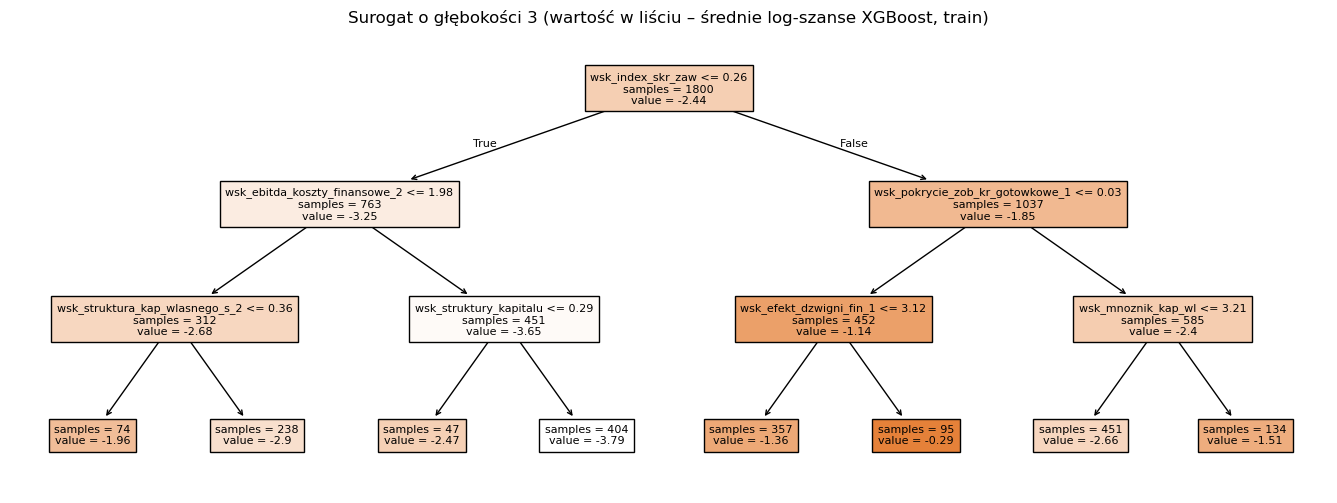

,reguła,udział firm (train),PD surowe XGB (liść)
0,wsk_index_skr_zaw ≤ 0.265 i wsk_ebitda_koszty_finansowe_2 > 1.98 i wsk_struktury_kapitalu > 0.293,0.2240,0.0220
1,wsk_index_skr_zaw ≤ 0.265 i wsk_ebitda_koszty_finansowe_2 ≤ 1.98 i wsk_struktura_kap_wlasnego_s_2 > 0.365,0.1320,0.0520
2,wsk_index_skr_zaw > 0.265 i wsk_pokrycie_zob_kr_gotowkowe_1 > 0.0324 i wsk_mnoznik_kap_wl ≤ 3.21,0.2510,0.0650
3,wsk_index_skr_zaw ≤ 0.265 i wsk_ebitda_koszty_finansowe_2 > 1.98 i wsk_struktury_kapitalu ≤ 0.293,0.0260,0.0780
4,wsk_index_skr_zaw ≤ 0.265 i wsk_ebitda_koszty_finansowe_2 ≤ 1.98 i wsk_struktura_kap_wlasnego_s_2 ≤ 0.365,0.0410,0.1240
5,wsk_index_skr_zaw > 0.265 i wsk_pokrycie_zob_kr_gotowkowe_1 > 0.0324 i wsk_mnoznik_kap_wl > 3.21,0.0740,0.1810
6,wsk_index_skr_zaw > 0.265 i wsk_pokrycie_zob_kr_gotowkowe_1 ≤ 0.0324 i wsk_efekt_dzwigni_fin_1 ≤ 3.12,0.1980,0.2040
7,wsk_index_skr_zaw > 0.265 i wsk_pokrycie_zob_kr_gotowkowe_1 ≤ 0.0324 i wsk_efekt_dzwigni_fin_1 > 3.12,0.0530,0.4280


In [ ]:
# global surrogate: DecisionTreeRegressor na log-szansach XGBoost (kolumny po przygotowaniu cech)
f_tr = xgb_clf.predict(Xt_tr_x, output_margin=True); f_va = margin          # log-szanse black-boxa: train (uczenie surogatu), valid (ocena)
def surogat(glebokosc, min_leaf=30):
    return DecisionTreeRegressor(max_depth=glebokosc, min_samples_leaf=min_leaf, random_state=SEED).fit(Xt_tr_x, f_tr)
SUR = {d_: surogat(d_) for d_ in [2, 3, 4, 5, 6, 8]}
wiersze = []
for d_, s_ in SUR.items():
    g_va = s_.predict(Xt_va_x)
    wiersze.append({"głębokość": d_, "liczba liści": s_.get_n_leaves(), "wierność R² (train)": r2_score(f_tr, s_.predict(Xt_tr_x)),
                    "wierność R² (val)": r2_score(f_va, g_va), "Spearman z black-boxem (val)": spearmanr(f_va, g_va)[0],
                    "Gini surogatu (val)": 2 * roc_auc_score(y_val, g_va) - 1})
TAB_SUR = pd.DataFrame(wiersze).set_index("głębokość"); display(TAB_SUR.round(3))
print(f"Dla porównania Gini (val): XGB = {2 * roc_auc_score(y_val, f_va) - 1:.3f}, LR = {2 * roc_auc_score(y_val, pv_lr) - 1:.3f}")

def reguly(drzewo, nazwy):
    # liście drzewa jako reguły „jeżeli ... to PD” (cechy po przygotowaniu są uzupełnione, więc nie ma gałęzi z brakami)
    t_, wyn = drzewo.tree_, []
    def idz(w_, war):
        if t_.children_left[w_] == -1:
            wyn.append({"reguła": " i ".join(war), "udział firm (train)": t_.n_node_samples[w_] / t_.n_node_samples[0], "PD surowe XGB (liść)": sigmoid(t_.value[w_][0][0])})
            return
        c_, prog_ = nazwy[t_.feature[w_]], t_.threshold[w_]
        idz(t_.children_left[w_], war + [f"{c_} ≤ {prog_:.3g}"]); idz(t_.children_right[w_], war + [f"{c_} > {prog_:.3g}"])
    idz(0, [])
    return pd.DataFrame(wyn).sort_values("PD surowe XGB (liść)").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(17, 6))
plot_tree(SUR[3], feature_names=list(Xt_tr_x.columns), filled=True, impurity=False, precision=2, fontsize=8, ax=ax)
ax.set_title("Surogat o głębokości 3 (wartość w liściu – średnie log-szanse XGBoost, train)"); plt.show()
with pd.option_context("display.max_colwidth", 120):
    display(reguly(SUR[3], list(Xt_tr_x.columns)).round(3))

**Komentarz do surogatu:** W badanym zakresie $R^2$ na zbiorze walidacyjnym osiąga maksymalnie $0{,}729$ (Spearman $0{,}855$) – progi $0{,}8$ oraz $0{,}9$ wymagają jeszcze głębszych drzew, które tracą czytelność. Do prezentacji biznesowej najlepiej sprawdza się głębokość 3 (8 liści, $R^2 = 0{,}587$) – jej reguły mają pełny sens ekonomiczny (sektor, pokrycie odsetek z EBITDA, płynność gotówkowa, dźwignia), wyraźnie separując segmenty ryzyka od $2{,}2\%$ do $42{,}8\%$ PD. Wnioski z drzewa dotyczą black-boxa tylko w takim stopniu, w jakim go odtwarza – podajemy $R^2$ razem z regułami. Surogat jest uczony na prognozach train, więc $R^2$ na valid jest uczciwą miarą wierności.

## 8. Kalibracja probabilistyczna
 **(1)** diagnostyka przed kalibracją na valid; **(2) kształt** – Platt / izotoniczna / beta, dopasowanie na valid, wybór metody **5-krotną walidacją krzyżową wewnątrz valid** (log-loss; kalibrator nie jest oceniany na danych, na których był dopasowany); **(3) poziom** – przesunięcie log-szans δ tak, by średnie PD na valid = 4%; **(4)** ocena po kalibracji na teście. Zbiór testowy nie bierze udziału w żadnej decyzji.

### 8.1 Diagnostyka przed kalibracją (valid)

DIAGNOSTYKA PRE-CAL (valid):
     Mean_PD     DR  Brier  LogLoss    ECE    ACE    CITL  Slope  Murphy_rzetelność   HL_p    AUC
LR    0.1546 0.1350 0.1050   0.3537 0.0308 0.0329 -0.1677 1.5562             0.0018 0.2670 0.7546
XGB   0.1278 0.1350 0.0983   0.3195 0.0285 0.0277  0.0755 1.0270             0.0011 0.5905 0.8096

Częstość defaultów: train=13.50%, val=13.50%; założenie biznesowe PD = 4%
Uwaga: p-wartość HL zależy od liczby obserwacji – czytaj ją razem z miarami wielkości błędu (ECE/ACE/CITL/nachylenie).


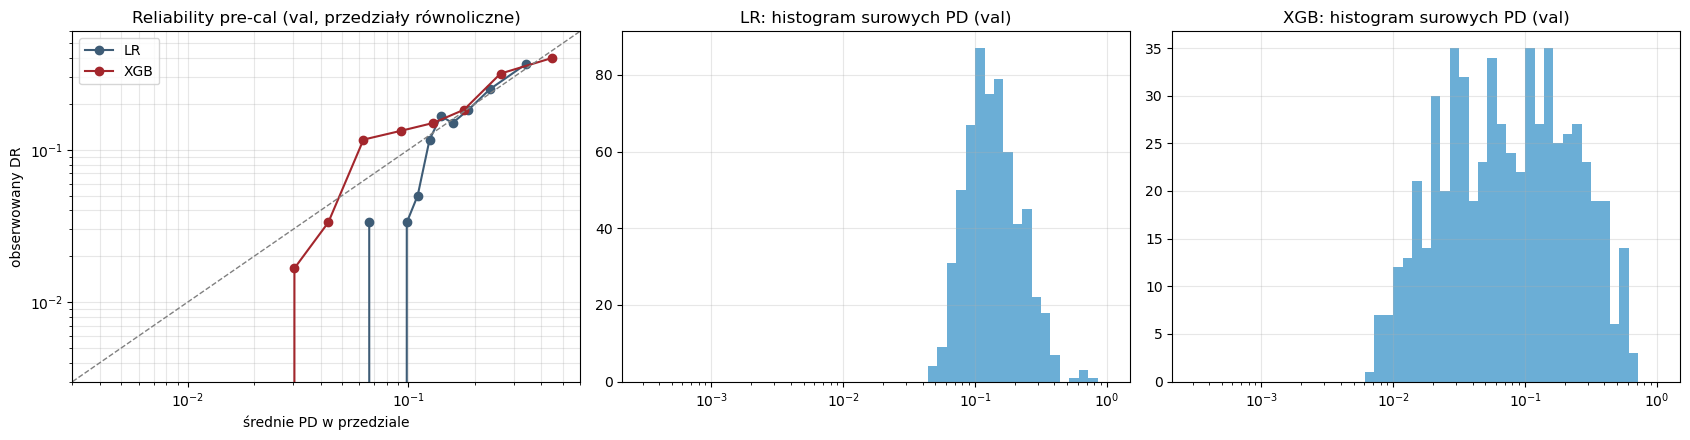

In [53]:
def reliability(ax, y, p, label, n_bins=10, **kw):
    obs, pred = calibration_curve(y, p, n_bins=n_bins, strategy="quantile"); ax.plot(pred, obs, "o-", label=label, **kw)
def os_log(ax, lo=3e-3, hi=0.6):
    ax.plot([lo, hi], [lo, hi], "--", color="gray", lw=1); ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_xlabel("średnie PD w przedziale"); ax.set_ylabel("obserwowany DR"); ax.grid(alpha=0.3, which="both")

MODELS = {"LR": {"est": best_lr, "val": pv_lr}, "XGB": {"est": best_xgb, "val": pv_xgb}}
pre = {}
for k, d in MODELS.items():
    m = full_metrics(y_val, d["val"]); rel, res_, unc = murphy(y_val, d["val"]); hl, php = hosmer_lemeshow(y_val, d["val"])
    pre[k] = {**m, "Murphy_rzetelność": rel, "Murphy_rozdzielczość": res_, "HL_p": php}
print("DIAGNOSTYKA PRE-CAL (valid):"); print(pd.DataFrame(pre).T[["Mean_PD", "DR", "Brier", "LogLoss", "ECE", "ACE", "CITL", "Slope", "Murphy_rzetelność", "HL_p", "AUC"]].round(4))
print(f"\nCzęstość defaultów: train={y_train.mean():.2%}, val={y_val.mean():.2%}; założenie biznesowe PD = {TARGET_PD:.0%}")
print("Uwaga: p-wartość HL zależy od liczby obserwacji – czytaj ją razem z miarami wielkości błędu (ECE/ACE/CITL/nachylenie).")
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for k, d in MODELS.items():
    reliability(ax[0], y_val, d["val"], k, color={"LR": "#3E5C76", "XGB": "#A3262C"}[k]); ax[1 if k == "LR" else 2].hist(d["val"], bins=np.logspace(-3.5, 0, 50), color="#6baed6"); ax[1 if k == "LR" else 2].set_xscale("log"); ax[1 if k == "LR" else 2].set_title(f"{k}: histogram surowych PD (val)")
os_log(ax[0]); ax[0].set_title("Reliability pre-cal (val, przedziały równoliczne)"); ax[0].legend(); plt.tight_layout(); plt.show()

### 8.2 Kształt: wybór metody walidacją krzyżową na valid
Metody: **Platt** (sigmoid na logicie PD), **izotoniczna** (schodki, wymaga wielu defaultów), **beta** ($\text{logit}(q)=a\ln p-b\ln(1-p)+c$) oraz brak kalibracji. Przy kilkudziesięciu defaultach w valid izotoniczna bywa przeuczona – preferujemy wtedy Platt/beta.


LR: metody kalibracji kształtu – ocena OUT-OF-FOLD na valid
                Mean_PD  Brier  LogLoss    ECE    ACE    CITL  Slope    AUC
bez kalibracji   0.1546 0.1050   0.3537 0.0308 0.0329 -0.1677 1.5562 0.7546
Platt            0.1346 0.1046   0.3477 0.0185 0.0277  0.0038 0.9807 0.7533
izotoniczna      0.1350 0.1078   0.4620 0.0235 0.0288  0.0003 0.1700 0.7294
beta             0.1354 0.1055   0.3504 0.0152 0.0236 -0.0039 0.9119 0.7509
LR: wybrana metoda = Platt (najniższy log-loss w CV na valid; przy remisie preferuj prostszą)

XGB: metody kalibracji kształtu – ocena OUT-OF-FOLD na valid
                Mean_PD  Brier  LogLoss    ECE    ACE   CITL  Slope    AUC
bez kalibracji   0.1278 0.0983   0.3195 0.0285 0.0277 0.0755 1.0270 0.8096
Platt            0.1349 0.0989   0.3211 0.0107 0.0279 0.0012 0.9777 0.8066
izotoniczna      0.1346 0.1004   0.3563 0.0202 0.0337 0.0039 0.3813 0.7909
beta             0.1345 0.0992   0.3212 0.0127 0.0248 0.0053 0.9726 0.8052
XGB: wybrana metoda = bez ka

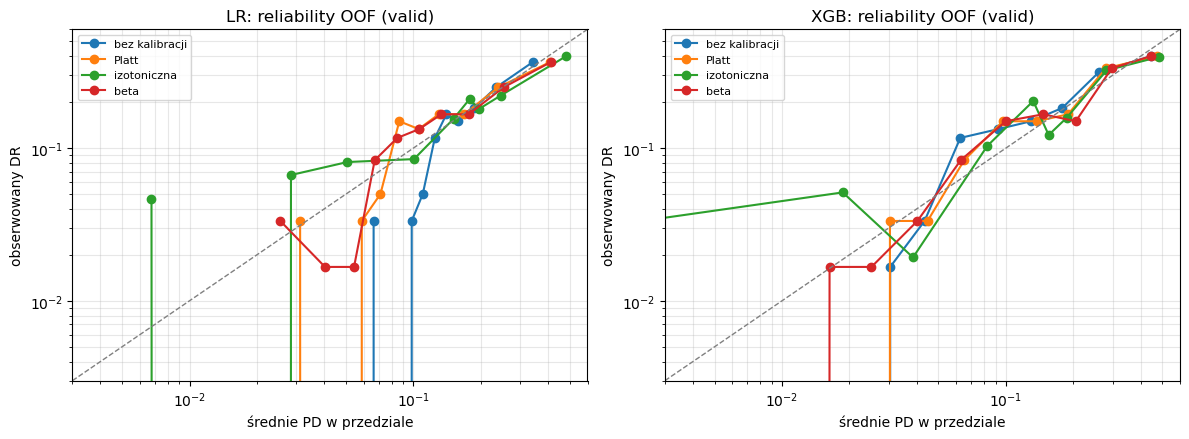

In [55]:
def _beta_cechy(p):
    p = np.clip(p, EPS, 1 - EPS); return np.column_stack([np.log(p), -np.log(1 - p)])
FIT = {"bez kalibracji": lambda y, p: None,
       "Platt": lambda y, p: LogisticRegression(C=1e6, max_iter=1000).fit(_z(p).reshape(-1, 1), y),
       "izotoniczna": lambda y, p: IsotonicRegression(out_of_bounds="clip", y_min=EPS, y_max=1 - EPS).fit(p, y),
       "beta": lambda y, p: LogisticRegression(C=1e6, max_iter=1000).fit(_beta_cechy(p), y)}
def zastosuj(metoda, kal, p):
    if metoda == "bez kalibracji": return np.asarray(p)
    if metoda == "Platt": return kal.predict_proba(_z(p).reshape(-1, 1))[:, 1]
    if metoda == "beta": return kal.predict_proba(_beta_cechy(p))[:, 1]
    return kal.predict(p)
def cv_kal_pred(metoda, y, p, k=5):          # predykcje kalibratora out-of-fold WEWNĄTRZ valid
    y = np.asarray(y); out = np.zeros(len(p)); skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=SEED)
    for a, b in skf.split(p.reshape(-1, 1), y): out[b] = zastosuj(metoda, FIT[metoda](y[a], p[a]), p[b])
    return out

for k, d in MODELS.items():
    cvp = {m: cv_kal_pred(m, y_val, d["val"]) for m in FIT}
    tabk = pd.DataFrame({m: full_metrics(y_val, p) for m, p in cvp.items()}).T[["Mean_PD", "Brier", "LogLoss", "ECE", "ACE", "CITL", "Slope", "AUC"]]
    print(f"\n{k}: metody kalibracji kształtu – ocena OUT-OF-FOLD na valid"); print(tabk.round(4))
    d["met"] = tabk["LogLoss"].round(4).idxmin(); d["cvp"] = cvp
    print(f"{k}: wybrana metoda = {d['met']} (najniższy log-loss w CV na valid; przy remisie preferuj prostszą)")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for j, (k, d) in enumerate(MODELS.items()):
    for m, p in d["cvp"].items(): reliability(ax[j], y_val, p, m)
    os_log(ax[j]); ax[j].set_title(f"{k}: reliability OOF (valid)"); ax[j].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 8.3 Poziom: przesunięcie do średniego PD = 4%
$\text{logit}(q)=\text{logit}(p)+\delta$, δ wyznaczone na valid, to samo δ stosujemy na teście. 4% to zewnętrzna kotwica biznesowa, a nie wynik estymacji – dopasowanie do niej nie jest poprawą kalibracji statystycznej. Zakłada się, że kształt zależności jest stabilny, a różni się tylko poziom bazowy.

LR: kształt = Platt, δ = -1.473 (prior-shift: -1.321) | średnie PD na valid: surowe 15.46% -> kształt 13.50% -> 4%: 4.00%
XGB: kształt = bez kalibracji, δ = -1.421 (prior-shift: -1.321) | średnie PD na valid: surowe 12.78% -> kształt 12.78% -> 4%: 4.00%


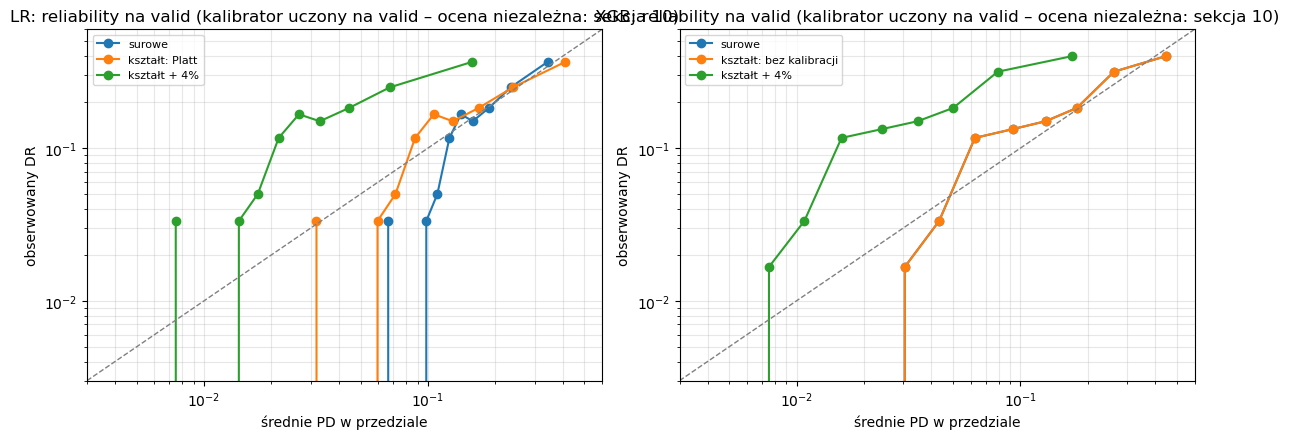

In [57]:
def delta_do_sredniej(p, cel, lo=-15.0, hi=15.0, iters=100):
    z = _z(p)
    for _ in range(iters):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if sigmoid(z + mid).mean() < cel else (lo, mid)
    return (lo + hi) / 2

for k, d in MODELS.items():
    d["KAL"] = FIT[d["met"]](y_val, d["val"])                                   # kalibrator dopasowany na CAŁYM valid
    d["to_pd_stat"] = (lambda p, d=d: zastosuj(d["met"], d["KAL"], p))
    d["delta"] = delta_do_sredniej(d["to_pd_stat"](d["val"]), TARGET_PD)
    d["to_pd"] = (lambda p, d=d: sigmoid(_z(d["to_pd_stat"](p)) + d["delta"]))    # surowe PD -> kształt -> 4%
    d["delta_prior"] = float(logit(TARGET_PD) - logit(y_train.mean()))
    print(f"{k}: kształt = {d['met']}, δ = {d['delta']:+.3f} (prior-shift: {d['delta_prior']:+.3f}) | średnie PD na valid: surowe {d['val'].mean():.2%} -> kształt {d['to_pd_stat'](d['val']).mean():.2%} -> 4%: {d['to_pd'](d['val']).mean():.2%}")
DELTA, METODA, MODEL_FINAL_NAME = MODELS["XGB"]["delta"], MODELS["XGB"]["met"], "XGB"
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for j, (k, d) in enumerate(MODELS.items()):
    for p, lab in [(d["val"], "surowe"), (d["to_pd_stat"](d["val"]), f"kształt: {d['met']}"), (d["to_pd"](d["val"]), "kształt + 4%")]: reliability(ax[j], y_val, p, lab)
    os_log(ax[j]); ax[j].set_title(f"{k}: reliability na valid (kalibrator uczony na valid – ocena niezależna: sekcja 10)"); ax[j].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 8.4 Co kalibracja robi z wyjaśnieniem SHAP
* **Przesunięcie δ:** wartości SHAP bez zmian, wartość bazowa przesuwa się o δ.
* **Platt:** $\text{logit}(q)=a\,\text{logit}(p)+b$ – wszystkie φ mnożone przez $a$, ranking bez zmian.
* **Izotoniczna / beta:** funkcja nieliniowa w log-szansach – wartości SHAP modelu surowego przestają wyjaśniać model końcowy; trzeba wyjaśniać cały łańcuch metodą niezależną od modelu.

In [59]:
d = MODELS["XGB"]; z_raw = margin
if d["met"] in ("bez kalibracji", "Platt"):
    a_, b_ = (1.0, 0.0) if d["met"] == "bez kalibracji" else (d["KAL"].coef_[0, 0], d["KAL"].intercept_[0])
    z_fin = _z(d["to_pd"](pv_xgb)); wzor = a_ * z_raw + b_ + d["delta"]
    print(f"Model końcowy XGB: kształt = {d['met']}, a = {a_:.3f}, δ = {d['delta']:+.3f} -> φ_końcowe = {a_:.3f}·φ; wartość bazowa końcowa = {a_ * BASE_X + b_ + d['delta']:+.3f}")
    print(f"Kontrola: maks. |logit PD końcowego − (a·f + b + δ)| = {np.max(np.abs(z_fin - wzor)):.1e}  (wyjaśnienia surowego modelu po przeskalowaniu opisują model końcowy)")
else:
    print(f"Kalibracja {d['met']} jest nieliniowa w log-szansach: wartości SHAP modelu surowego NIE opisują modelu końcowego – wyjaśniaj cały łańcuch (np. SHAP na funkcji pd_koncowe).")

Model końcowy XGB: kształt = bez kalibracji, a = 1.000, δ = -1.421 -> φ_końcowe = 1.000·φ; wartość bazowa końcowa = -3.276
Kontrola: maks. |logit PD końcowego − (a·f + b + δ)| = 2.4e-07  (wyjaśnienia surowego modelu po przeskalowaniu opisują model końcowy)


**Komentarz:** Średnie PD po kalibracji kształtu przewyższa docelowy poziom o ok. $9$–$9{,}5\text{ p.p.}$ Przesunięcie poziomu bazowego (interceptu) do celu $4\%$ na walidacji celowo pogarsza Brier, LogLoss i CITL względem próby rozwojowej, nie zmieniając przy tym AUC ani KS (transformacja monotoniczna). Metoda zakłada stały kształt zależności przy zmianie samego poziomu ryzyka, a średnie PD na zbiorze testowym nie musi wynosić dokładnie $4\%$ przez wariancję próbkowania.

## 9. Progi decyzji, skala ratingowa, backtest i analiza kontrfaktyczna
Wszystkie decyzje (próg, wybór obserwacji do kontrfaktyku) opierają się na valid.

### 9.1 Funkcja zysku i próg decyzyjny
Przyjęty dobry klient daje zysk `MARGIN·EAD`, przyjęty zły – stratę `LGD·EAD`, odrzucenie = 0. Opłaca się przyjąć klienta, gdy $PD<p^*=\frac{MARGIN}{MARGIN+LGD}$ (przy MARGIN = 10%, LGD = 45%: ≈ 18,2%). Oczekiwana strata przyjętych: $EL=\sum PD\cdot LGD\cdot EAD$. Próg empiryczny szukamy na valid. Próg teoretyczny wymaga skalibrowanego PD – dlatego kalibracja jest przed progiem; przy PD zakotwiczonym na 4% porównujemy też wariant „PD przed δ”.

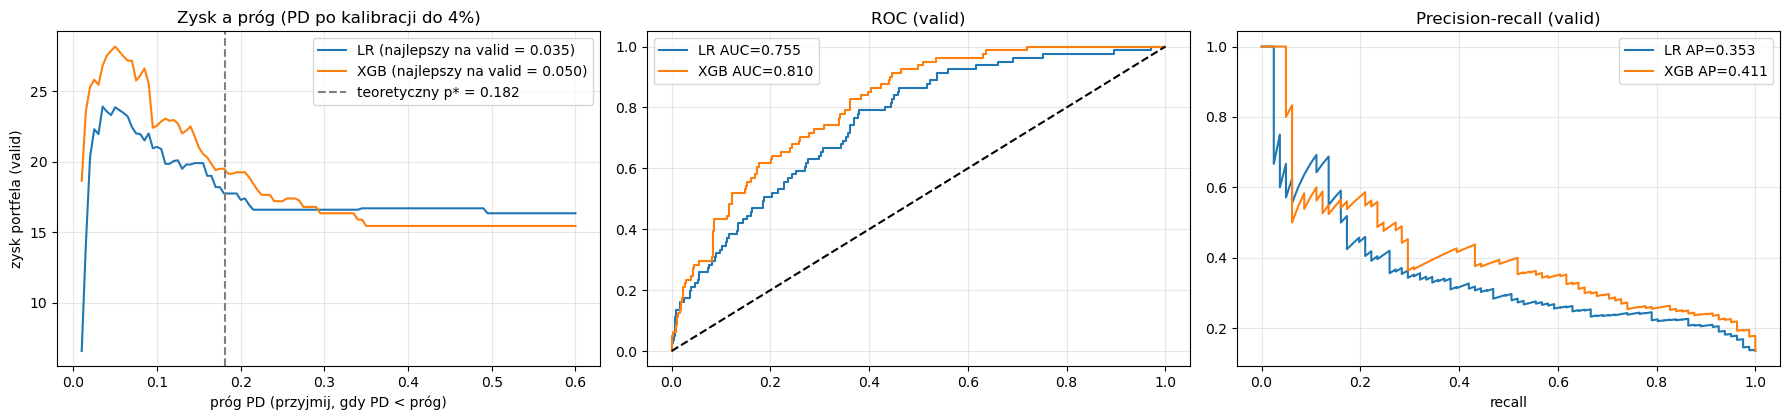

p* = 0.182 | progi z valid: LR: 0.035 (PD przed δ: 0.190), XGB: 0.050 (PD przed δ: 0.185)
Uwaga: gdy DR w próbie ≫ 4%, PD po δ jest zaniżone względem DR, więc próg empiryczny z valid wychodzi wyraźnie niższy od p* – „kompensuje” zaniżone PD. Dla PD przed δ (kolumna w nawiasie) próg jest zwykle bliższy p*. Opisz to w raporcie jako konsekwencję kotwicy 4%.

Wrażliwość progu na założenia kosztowe:
   LGD  MARGIN     p*  próg valid LR  próg valid XGB
0.3500  0.0500 0.1250         0.0250          0.0200
0.3500  0.1000 0.2220         0.0650          0.0700
0.3500  0.1500 0.3000         0.1450          0.0850
0.4500  0.0500 0.1000         0.0200          0.0150
0.4500  0.1000 0.1820         0.0350          0.0500
0.4500  0.1500 0.2500         0.0900          0.0850
0.6000  0.0500 0.0770         0.0200          0.0150
0.6000  0.1000 0.1430         0.0250          0.0200
0.6000  0.1500 0.2000         0.0500          0.0500


In [62]:
p_star = MARGIN / (MARGIN + LGD)
def ekonomia(y, p, e, prog, margin=None, lgd=None):
    margin = MARGIN if margin is None else margin; lgd = LGD if lgd is None else lgd; przyj = p < prog
    return {"próg": prog, "stopa akceptacji": przyj.mean(), "DR wśród przyjętych": y[przyj].mean() if przyj.any() else np.nan,
            "EL przyjętych (oczekiwana)": float(np.sum(p[przyj] * lgd * e[przyj])), "strata zrealizowana": float(np.sum(lgd * e[przyj & (y == 1)])),
            "zysk": float(np.sum(margin * e[przyj & (y == 0)]) - np.sum(lgd * e[przyj & (y == 1)]))}

progi = np.linspace(0.01, 0.6, 119); y_va_a = np.asarray(y_val)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.3))
for k, d in MODELS.items():
    p4, ps = d["to_pd"](d["val"]), d["to_pd_stat"](d["val"])
    z4 = np.array([ekonomia(y_va_a, p4, ead["valid"], t)["zysk"] for t in progi]); zs = np.array([ekonomia(y_va_a, ps, ead["valid"], t)["zysk"] for t in progi])
    d["prog_val"], d["prog_val_ps"] = float(progi[z4.argmax()]), float(progi[zs.argmax()])
    ax[0].plot(progi, z4, label=f"{k} (najlepszy na valid = {d['prog_val']:.3f})"); fpr, tpr, _ = roc_curve(y_va_a, d["val"]); ax[1].plot(fpr, tpr, label=f"{k} AUC={roc_auc_score(y_va_a, d['val']):.3f}")
    pr, rc, _ = precision_recall_curve(y_va_a, d["val"]); ax[2].plot(rc, pr, label=f"{k} AP={average_precision_score(y_va_a, d['val']):.3f}")
ax[0].axvline(p_star, ls="--", color="gray", label=f"teoretyczny p* = {p_star:.3f}"); ax[0].set_xlabel("próg PD (przyjmij, gdy PD < próg)"); ax[0].set_ylabel("zysk portfela (valid)"); ax[0].set_title("Zysk a próg (PD po kalibracji do 4%)"); ax[0].legend()
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set_title("ROC (valid)"); ax[1].legend(); ax[2].set_title("Precision-recall (valid)"); ax[2].set_xlabel("recall"); ax[2].legend()
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"p* = {p_star:.3f} | progi z valid: " + ", ".join(f"{k}: {d['prog_val']:.3f} (PD przed δ: {d['prog_val_ps']:.3f})" for k, d in MODELS.items()))
print("Uwaga: gdy DR w próbie ≫ 4%, PD po δ jest zaniżone względem DR, więc próg empiryczny z valid wychodzi wyraźnie niższy od p* – „kompensuje” zaniżone PD. Dla PD przed δ (kolumna w nawiasie) próg jest zwykle bliższy p*. Opisz to w raporcie jako konsekwencję kotwicy 4%.")
sens = []
for L in [0.35, 0.45, 0.6]:
    for M in [0.05, 0.10, 0.15]:
        row = {"LGD": L, "MARGIN": M, "p*": M / (M + L)}
        for k, d in MODELS.items():
            p4 = d["to_pd"](d["val"]); row[f"próg valid {k}"] = progi[int(np.argmax([ekonomia(y_va_a, p4, ead["valid"], t, M, L)["zysk"] for t in progi]))]
        sens.append(row)
print("\nWrażliwość progu na założenia kosztowe:"); print(pd.DataFrame(sens).round(3).to_string(index=False))

### 9.2 Skala główna – 7 klas, granice stałe
Skala: AAA <1%, AA <2%, A <5%, BBB <8%, BB <12%, B <20%, CCC ≥20%; granice rosnące, stałe i wspólne dla obu modeli. Klasa D jest zarezerwowana dla ekspozycji w defaulcie – w dniu oceny nie przypisujemy jej nikomu (w backteście to zaobserwowane defaulty). Sprawdzamy koncentrację (HHI) i monotoniczność DR między klasami – bez scalania klas.

In [64]:
RATING_BINS = [0.00, 0.01, 0.02, 0.05, 0.08, 0.12, 0.20, 1.0 + 1e-9]; RATING_LABELS = ["AAA", "AA", "A", "BBB", "BB", "B", "CCC"]
def rating(p): return pd.Categorical(pd.cut(np.asarray(p), bins=RATING_BINS, labels=RATING_LABELS, right=False), categories=RATING_LABELS, ordered=True)
for d in MODELS.values(): d["edges"], d["labels"] = RATING_BINS, RATING_LABELS
display(pd.DataFrame({"klasa": RATING_LABELS, "przedział PD": [f"{100 * RATING_BINS[k]:.0f}% - {100 * RATING_BINS[k + 1]:.0f}%" if k < 6 else "≥ 20%" for k in range(7)]}).set_index("klasa"))
for k, d in MODELS.items():
    ud = pd.Series(rating(d["to_pd"](d["val"]))).value_counts(normalize=True).reindex(RATING_LABELS).fillna(0)
    print(f"{k} (valid): największy udział klasy {ud.max():.1%} ({ud.idxmax()}), HHI = {(ud ** 2).sum():.3f} (równy rozkład: {1 / 7:.3f})")

,przedział PD
klasa,
AAA,0% - 1%
AA,1% - 2%
A,2% - 5%
BBB,5% - 8%
BB,8% - 12%
B,12% - 20%
CCC,≥ 20%


LR (valid): największy udział klasy 37.0% (A), HHI = 0.254 (równy rozkład: 0.143)
XGB (valid): największy udział klasy 33.8% (AAA), HHI = 0.221 (równy rozkład: 0.143)


### 9.3 Backtest per klasa: test dwumianowy, test Jeffreysa i „światła”
Dla klasy z *n* klientami, *d* defaultami i średnim PD: test dwumianowy (jednostronny) p = P(X ≥ d), X ~ Bin(n, PD); test Jeffreysa p = F_Beta(PD; d+½, n−d+½). Mała p-wartość = PD klasy prawdopodobnie zaniżone. Światła: zielone p ≥ 0,05, żółte 0,01 ≤ p < 0,05, czerwone p < 0,01. Porównanie świateł przed δ i po δ rozdziela przyczyny: czerwone tylko po δ ⇒ efekt kotwicy 4% (gdy DR w próbie ≫ 4%); czerwone także przed δ ⇒ problem kształtu kalibracji. Testy zakładają niezależność defaultów (przy wspólnym cyklu są zbyt surowe).

In [66]:
def swiatlo(p): return "zielone" if p >= 0.05 else ("żółte" if p >= 0.01 else "czerwone")
def backtest(y, p, r, p_kszt=None):
    y = np.asarray(y); rows = []
    for lab in RATING_LABELS:
        m = np.asarray(r == lab)
        if not m.any(): continue
        n_k, d_k, pd_k = int(m.sum()), int(y[m].sum()), float(p[m].mean()); pj = float(beta_dist.cdf(pd_k, d_k + 0.5, n_k - d_k + 0.5))
        w = {"klasa": lab, "n": n_k, "defaulty": d_k, "oczekiwane": n_k * pd_k, "średnie PD": pd_k, "DR": d_k / n_k,
             "p dwumianowy": binomtest(d_k, n_k, pd_k, alternative="greater").pvalue, "p Jeffreysa": pj, "światło": swiatlo(pj)}
        if p_kszt is not None:
            pk = float(p_kszt[m].mean()); w.update({"PD przed δ": pk, "światło przed δ": swiatlo(float(beta_dist.cdf(pk, d_k + 0.5, n_k - d_k + 0.5)))})
        rows.append(w)
    return pd.DataFrame(rows).set_index("klasa")
# sprawdzenie na przykładzie z wykładu 3 (BBB: n=400, PD=6,5%, 38 defaultów)
print(f"Kontrola przykładu: p dwumianowy = {binomtest(38, 400, 0.065, alternative='greater').pvalue:.3f}, p Jeffreysa = {beta_dist.cdf(0.065, 38.5, 362.5):.3f}")
bt_va = backtest(y_va_a, MODELS["XGB"]["to_pd"](MODELS["XGB"]["val"]), rating(MODELS["XGB"]["to_pd"](MODELS["XGB"]["val"])), MODELS["XGB"]["to_pd_stat"](MODELS["XGB"]["val"]))
print("Backtest XGB na valid (kalibracja dopasowana na valid – ocena niezależna na teście w sekcji 10):"); display(bt_va.round(4))

Kontrola przykładu: p dwumianowy = 0.013, p Jeffreysa = 0.010
Backtest XGB na valid (kalibracja dopasowana na valid – ocena niezależna na teście w sekcji 10):


,n,defaulty,oczekiwane,średnie PD,DR,p dwumianowy,p Jeffreysa,światło,PD przed δ,światło przed δ
klasa,,,,,,,,,,
AAA,203,3,1.1493,0.0057,0.0148,0.1092,0.0580,zielone,0.0230,zielone
AA,105,7,1.5478,0.0147,0.0667,0.0010,0.0004,czerwone,0.0583,zielone
A,144,21,4.8088,0.0334,0.1458,0.0000,0.0000,czerwone,0.1245,zielone
BBB,62,15,3.9606,0.0639,0.2419,0.0000,0.0000,czerwone,0.2198,zielone
BB,40,13,3.9336,0.0983,0.3250,0.0001,0.0000,czerwone,0.3103,zielone
B,29,12,4.2453,0.1464,0.4138,0.0004,0.0002,czerwone,0.4138,zielone
CCC,17,10,4.3545,0.2561,0.5882,0.0038,0.0018,czerwone,0.5843,zielone


### 9.4 Analiza kontrfaktyczna – jedna obserwacja
Pytanie: jakie najmniejsze, realistyczne zmiany wskaźników poprawią rating o jedną klasę? Obserwacja z walidacji ze środkowej/gorszej klasy. Realizm: co najwyżej 2 cechy, wartości w zakresie 5–95 centyla z train, kandydaci to cechy surowe o dodatnim wkładzie SHAP, pomijamy cechy silnie skorelowane (|ρ|>0,7) z już wybraną, koszt = suma względnych zmian |Δ|/(q95−q05). Wskaźniki powiązane rachunkowo nie są przeliczane.

In [68]:
def run_cf(mk, i_pos, feats_pool, n1=41, n2=15):
    d = MODELS[mk]; pred = lambda df: d["to_pd"](d["est"].predict_proba(df)[:, 1])
    row = X_val.iloc[[i_pos]].reset_index(drop=True).copy(); p0 = float(pred(row)[0]); k0 = int(pd.cut([p0], bins=RATING_BINS, labels=False, right=False)[0])
    if k0 == 0: return None
    target = RATING_BINS[k0] - 1e-9
    Xr = X_train[feats_pool].replace([np.inf, -np.inf], np.nan); rng_ = {f: tuple(Xr[f].quantile([.05, .95])) for f in feats_pool}
    for f in feats_pool: row[f] = row[f].astype(float)
    x0 = {f: float(row.at[0, f]) for f in feats_pool}; sols = []
    for f in feats_pool:
        lo, hi = rng_[f]; g = np.linspace(lo, hi, n1); df_ = pd.concat([row] * n1, ignore_index=True); df_[f] = g; p = pred(df_)
        cost = np.abs(g - x0[f]) / (hi - lo); ok = p <= target
        if ok.any(): j = int(np.argmin(np.where(ok, cost, np.inf))); sols.append(((f,), (g[j],), float(cost[j]), float(p[j])))
    for f1, f2 in itertools.combinations(feats_pool[:5], 2):
        (l1, h1), (l2, h2) = rng_[f1], rng_[f2]; G1, G2 = np.meshgrid(np.linspace(l1, h1, n2), np.linspace(l2, h2, n2)); m = G1.size
        df_ = pd.concat([row] * m, ignore_index=True); df_[f1] = G1.ravel(); df_[f2] = G2.ravel(); p = pred(df_)
        cost = np.abs(G1.ravel() - x0[f1]) / (h1 - l1) + np.abs(G2.ravel() - x0[f2]) / (h2 - l2); ok = p <= target
        if ok.any(): j = int(np.argmin(np.where(ok, cost, np.inf))); sols.append(((f1, f2), (G1.ravel()[j], G2.ravel()[j]), float(cost[j]), float(p[j])))
    sols.sort(key=lambda s: s[2])
    return {"p0": p0, "rating0": RATING_LABELS[k0], "target_rating": RATING_LABELS[k0 - 1], "target_pd": target, "x0": x0, "sols": sols}

dX = MODELS["XGB"]; pvf = dX["to_pd"](dX["val"]); cls_v = pd.cut(pvf, bins=RATING_BINS, labels=False, right=False)
k_try = [k for k in [len(RATING_LABELS) - 3, len(RATING_LABELS) - 2, 3, 2, 1] if 1 <= k < len(RATING_LABELS) and (cls_v == k).sum() > 0][0]
cand_i = np.where(cls_v == k_try)[0]; i_cf = int(cand_i[np.argmin(np.abs(pvf[cand_i] - np.median(pvf[cand_i])))])
s_i = pd.Series(PHI_X[i_cf], index=SRC_X).sort_values(ascending=False); raw_ok = [f for f in s_i[s_i > 0].index if f in NUM_COLS]
Xs = X_train[NUM_COLS].replace([np.inf, -np.inf], np.nan); pool = []
for f in raw_ok:
    if all(abs(Xs[[f, g]].corr(method="spearman").iloc[0, 1]) <= 0.7 for g in pool): pool.append(f)
    if len(pool) == 6: break
print(f"Obserwacja kontrfaktyczna: val[{X_val.index[i_cf]}], kandydaci do zmiany: {pool}")
cf = run_cf("XGB", i_cf, pool) if pool else None
if cf is None or not cf["sols"]:
    print("Brak rozwiązania w dozwolonych granicach – wybierz inną obserwację albo poszerz zakres.")
else:
    print(f"XGB: PD={cf['p0']:.2%} (rating {cf['rating0']}) -> cel: PD ≤ {cf['target_pd']:.2%} (rating {cf['target_rating']})")
    out = [{"zmiana": " + ".join(f"{f}: {cf['x0'][f]:.3g} → {v:.3g}" for f, v in zip(fs, vs)), "percentyl nowej wartości (train)": " / ".join(f"{(Xs[f].dropna() <= v).mean():.0%}" for f, v in zip(fs, vs)), "koszt (względny)": c, "nowe PD": p1} for fs, vs, c, p1 in cf["sols"][:6]]
    print(pd.DataFrame(out).to_string(index=False)); best = cf["sols"][0]
    ctb = lime_run(make_lime(SEED), Xt_va_x.iloc[i_cf].values)[1]
    cmp_tab = pd.DataFrame({"SHAP": s_i, "LIME": pd.Series(ctb, index=SRC_X)}).loc[list(pool)]; cmp_tab["zmieniana w kontrfaktyku"] = [f in best[0] for f in cmp_tab.index]
    print("\nPorównanie z wyjaśnieniami tej obserwacji (SHAP w log-szansach, LIME w jednostkach PD – porównujemy znaki i rangi):"); print(cmp_tab.round(4))
    cf_lr = run_cf("LR", i_cf, pool)
    print("\nLR: " + (f"PD={cf_lr['p0']:.2%} ({cf_lr['rating0']}) -> {cf_lr['target_rating']}; minimalna zmiana: " + " + ".join(f"{f}: {cf_lr['x0'][f]:.3g} → {v:.3g}" for f, v in zip(cf_lr['sols'][0][0], cf_lr['sols'][0][1])) if cf_lr and cf_lr["sols"] else "brak rozwiązania w dozwolonych granicach."))

Obserwacja kontrfaktyczna: val[2412], kandydaci do zmiany: ['wsk_index_nowe', 'wsk_poziom_kapitalu_obrotowego_netto', 'wsk_stopa_zysku_sprzedaz', 'wsk_rent_kaptial_podstawowy', 'wsk_liczba_dni_istnienia', 'Zobowiazania_rezerwy']
XGB: PD=9.68% (rating BB) -> cel: PD ≤ 8.00% (rating BBB)
                                                                                                   zmiana percentyl nowej wartości (train)  koszt (względny)  nowe PD
                                                            wsk_liczba_dni_istnienia: 1.95e+03 → 1.77e+03                              24%            0.0210   0.0658
wsk_poziom_kapitalu_obrotowego_netto: 2.26e+03 → 1.53e+05 + wsk_liczba_dni_istnienia: 1.95e+03 → 1.95e+03                        51% / 30%            0.0358   0.0707
                                                wsk_poziom_kapitalu_obrotowego_netto: 2.26e+03 → 1.68e+05                              52%            0.0389   0.0700
      wsk_poziom_kapitalu_obrotowego_netto: 2.26e

**Ograniczenia kontrfaktyku:** Wynik opisuje model, nie przyczynowość – zmiana wskaźnika nie gwarantuje spadku realnego ryzyka i nie uwzględnia wykonalności biznesowej. Zmieniamy wskaźniki pojedynczo, mimo że w bilansie są one powiązane rachunkowo, a wielkość kroku zależy od bliskości arbitralnej granicy klasy ratingowej. Zgodnie z oczekiwaniami modyfikowane cechy pokrywają się z najsilniejszymi predyktorami z SHAP/LIME i wagami LR (płynność, EBITDA, dźwignia), choć w XGBoost decydują też lokalne progi podziału drzew.

## 10. Ocena końcowa na zbiorze testowym
**Zbiór testowy używany jest tutaj po raz pierwszy.** Modele, kalibratory, δ do 4%, progi, granice ratingów i parametry kontrfaktyku są już zamrożone – poniżej wyłącznie ich ocena.

Test: n=600, defaulty=81, DR=13.50% | założenie PD=4%

METRYKI NA TEŚCIE (pre-cal / post-cal kształt / post-cal 4%):
                    AUC   Gini     KS  PR_AUC  LogLoss  Brier  Mean_PD     DR    ECE    ACE    CITL  Slope
LR | surowe      0.7200 0.4400 0.3537  0.3224   0.3624 0.1076   0.1508 0.1350 0.0260 0.0430 -0.1345 1.5162
LR | kształt     0.7200 0.4400 0.3537  0.3224   0.3573 0.1069   0.1286 0.1350 0.0182 0.0395  0.0621 0.9739
LR | kształt+4%  0.7200 0.4400 0.3537  0.3224   0.4471 0.1200   0.0363 0.1350 0.0987 0.1003  1.5356 0.9738
XGB | surowe     0.7705 0.5411 0.4220  0.3668   0.3393 0.1033   0.1307 0.1350 0.0260 0.0286  0.0443 0.8818
XGB | kształt    0.7705 0.5411 0.4220  0.3668   0.3393 0.1033   0.1307 0.1350 0.0260 0.0286  0.0443 0.8818
XGB | kształt+4% 0.7705 0.5411 0.4220  0.3668   0.4194 0.1163   0.0407 0.1350 0.0943 0.0949  1.4651 0.8816


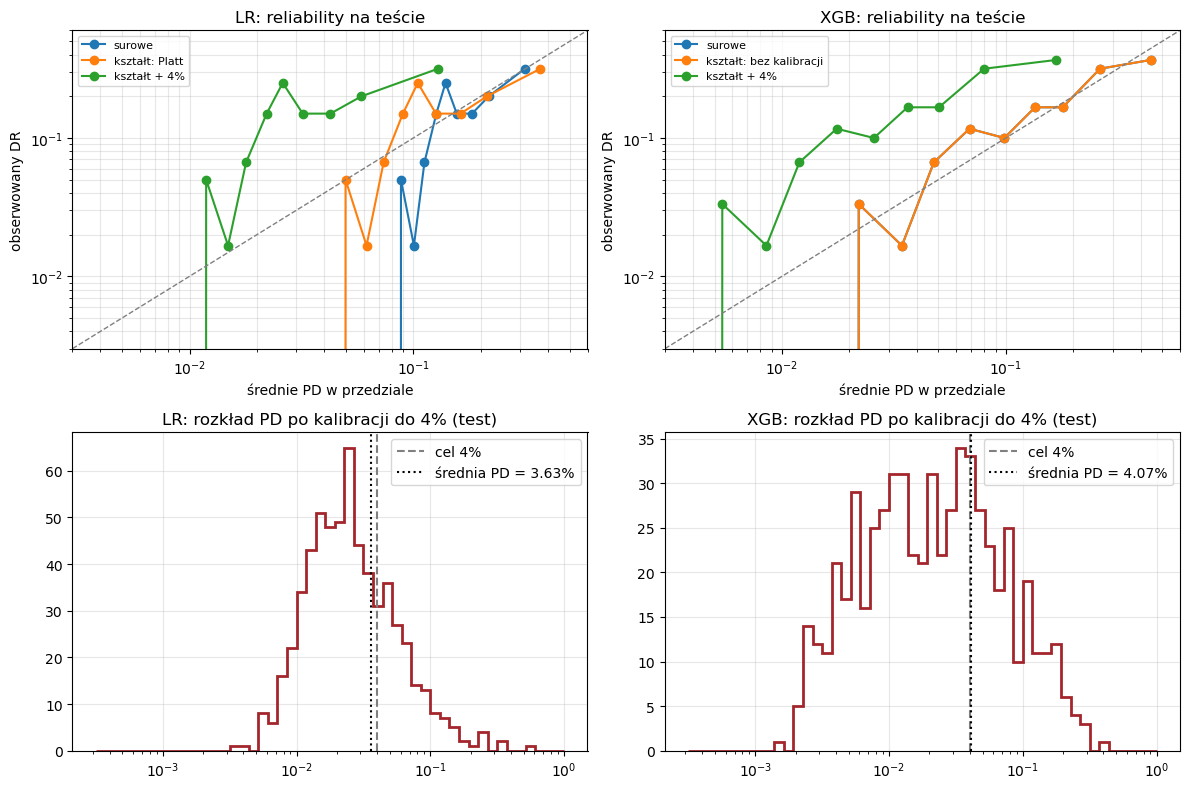

In [71]:
for k, d in MODELS.items():
    d["test_raw"] = d["est"].predict_proba(X_test)[:, 1]; d["test_stat"] = d["to_pd_stat"](d["test_raw"]); d["test_4"] = d["to_pd"](d["test_raw"])
yt = np.asarray(y_test)
print(f"Test: n={len(yt)}, defaulty={int(yt.sum())}, DR={yt.mean():.2%} | założenie PD={TARGET_PD:.0%}")
rows = {f"{k} | {nm}": full_metrics(yt, p) for k, d in MODELS.items() for nm, p in {"surowe": d["test_raw"], "kształt": d["test_stat"], "kształt+4%": d["test_4"]}.items()}
final_tab = pd.DataFrame(rows).T[["AUC", "Gini", "KS", "PR_AUC", "LogLoss", "Brier", "Mean_PD", "DR", "ECE", "ACE", "CITL", "Slope"]]
print("\nMETRYKI NA TEŚCIE (pre-cal / post-cal kształt / post-cal 4%):"); print(final_tab.round(4)); final_tab.to_csv(ART / "metryki_test.csv")
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for j, (k, d) in enumerate(MODELS.items()):
    for p, lab in [(d["test_raw"], "surowe"), (d["test_stat"], f"kształt: {d['met']}"), (d["test_4"], "kształt + 4%")]: reliability(ax[0, j], yt, p, lab)
    os_log(ax[0, j]); ax[0, j].set_title(f"{k}: reliability na teście"); ax[0, j].legend(fontsize=8)
    ax[1, j].hist(d["test_4"], bins=np.logspace(-3.5, 0, 50), histtype="step", lw=2, color="#A3262C"); ax[1, j].set_xscale("log"); ax[1, j].axvline(TARGET_PD, ls="--", color="gray", label="cel 4%"); ax[1, j].axvline(d["test_4"].mean(), color="k", ls=":", label=f"średnia PD = {d['test_4'].mean():.2%}")
    ax[1, j].set_title(f"{k}: rozkład PD po kalibracji do 4% (test)"); ax[1, j].legend()
plt.tight_layout(); plt.show()

,AUC 95% CI,PR-AUC 95% CI,KS 95% CI
LR (test),[0.669; 0.775],[0.244; 0.439],[0.299; 0.453]
XGB (test),[0.724; 0.820],[0.276; 0.478],[0.354; 0.540]


Różnica Gini (XGB − LR) = +0.1011, 95% CI (sparowany bootstrap) [+0.0212; +0.1762] -> istotna na korzyść XGB


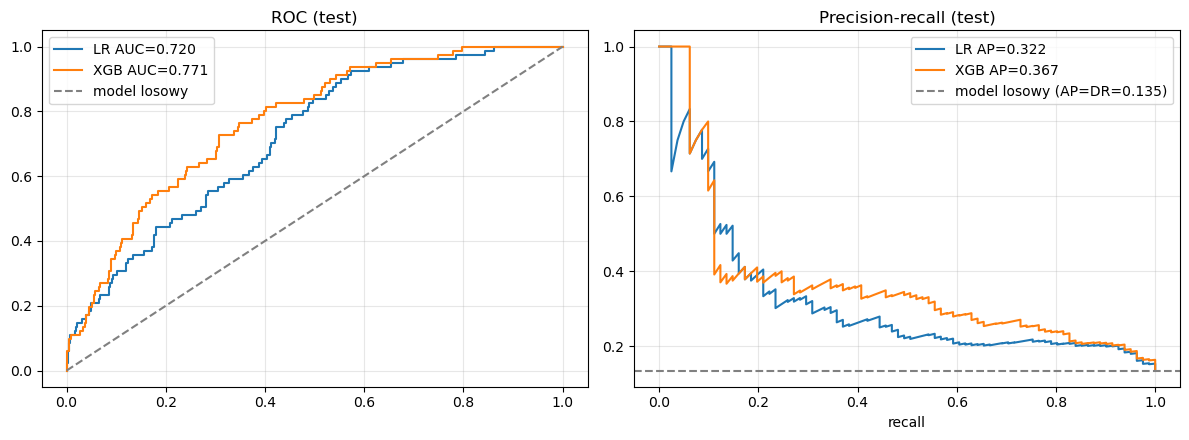


Metryki w CV (train), średnia ± odch. std.:
             LR              XGB         
        średnia odch.std średnia odch.std
AUC      0.7507   0.0265  0.7739   0.0200
PR_AUC   0.3545   0.0361  0.3597   0.0326
KS       0.4293   0.0618  0.4520   0.0532
LogLoss  0.3576   0.0096  0.3393   0.0092
Brier    0.1056   0.0033  0.1035   0.0027

Złożoność modeli:
                                                 LR                             XGB
cechy po przygotowaniu                          148                             153
niezerowe β                                      11   104 kolumn użytych w drzewach
regularyzacja                            l1, C=0.03  depth=4, n_trees=287, lr=0.036
ograniczenia monotoniczne  brak (liniowy w logicie)                            brak


In [72]:
# Przedziały ufności (bootstrap) i różnica modeli; krzywe ROC/PR na teście; stabilność w CV
def bootstrap_ci(y, p, B=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed); w = {"AUC": [], "PR-AUC": [], "KS": []}
    for _ in range(B):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() == y[i].max(): continue
        w["AUC"].append(roc_auc_score(y[i], p[i])); w["PR-AUC"].append(average_precision_score(y[i], p[i])); w["KS"].append(ks_stat(y[i], p[i]))
    return {f"{k} 95% CI": f"[{np.percentile(v, 2.5):.3f}; {np.percentile(v, 97.5):.3f}]" for k, v in w.items()}
display(pd.DataFrame({f"{k} (test)": bootstrap_ci(yt, d["test_raw"]) for k, d in MODELS.items()}).T)
rng_t = np.random.default_rng(SEED); dg = []
for _ in range(N_BOOT):
    i = rng_t.integers(0, len(yt), len(yt))
    if yt[i].min() == yt[i].max(): continue
    dg.append(2 * (roc_auc_score(yt[i], MODELS["XGB"]["test_raw"][i]) - roc_auc_score(yt[i], MODELS["LR"]["test_raw"][i])))
d_gini = 2 * (roc_auc_score(yt, MODELS["XGB"]["test_raw"]) - roc_auc_score(yt, MODELS["LR"]["test_raw"])); lo_g, hi_g = np.percentile(dg, [2.5, 97.5])
print(f"Różnica Gini (XGB − LR) = {d_gini:+.4f}, 95% CI (sparowany bootstrap) [{lo_g:+.4f}; {hi_g:+.4f}] -> " + ("istotna na korzyść XGB" if lo_g > 0 else "istotna na korzyść LR" if hi_g < 0 else "brak istotnej różnicy"))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for k, d in MODELS.items():
    fpr, tpr, _ = roc_curve(yt, d["test_raw"]); ax[0].plot(fpr, tpr, label=f"{k} AUC={roc_auc_score(yt, d['test_raw']):.3f}")
    pr, rc, _ = precision_recall_curve(yt, d["test_raw"]); ax[1].plot(rc, pr, label=f"{k} AP={average_precision_score(yt, d['test_raw']):.3f}")
ax[0].plot([0, 1], [0, 1], "--", color="gray", label="model losowy"); ax[1].axhline(yt.mean(), ls="--", color="gray", label=f"model losowy (AP=DR={yt.mean():.3f})")
ax[0].set_title("ROC (test)"); ax[1].set_title("Precision-recall (test)"); ax[1].set_xlabel("recall")
for a in ax: a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("\nMetryki w CV (train), średnia ± odch. std.:"); print(pd.concat({"LR": cv_summary(cv_lr)[["średnia", "odch.std"]], "XGB": cv_summary(cv_xgb)[["średnia", "odch.std"]]}, axis=1).round(4))
bst = xgb_clf.get_booster(); used = len(bst.get_score(importance_type="gain"))
print("\nZłożoność modeli:"); print(pd.DataFrame({"LR": {"cechy po przygotowaniu": len(coef), "niezerowe β": int((coef.abs() > 1e-8).sum()), "regularyzacja": f"{chosen_params['clf__penalty']}, C={chosen_params['clf__C']}", "ograniczenia monotoniczne": "brak (liniowy w logicie)"},
    "XGB": {"cechy po przygotowaniu": len(cols_x), "niezerowe β": f"{used} kolumn użytych w drzewach", "regularyzacja": f"depth={xgb_clf.max_depth}, n_trees={xgb_clf.n_estimators}, lr={xgb_clf.learning_rate:.3f}", "ograniczenia monotoniczne": "brak"}}).to_string())


=== LR: rating na teście | największy udział klasy 42.3% (A), HHI = 0.293 ===


,n,defaulty,oczekiwane,średnie PD,DR,p dwumianowy,p Jeffreysa,światło,PD przed δ,światło przed δ
klasa,,,,,,,,,,
AAA,54,0,0.4262,0.0079,0.0000,1.0000,0.6462,zielone,0.0335,zielone
AA,182,8,2.6586,0.0146,0.0440,0.0057,0.0030,czerwone,0.0607,zielone
A,254,44,7.9456,0.0313,0.1732,0.0000,0.0000,czerwone,0.1227,czerwone
BBB,61,12,3.8427,0.0630,0.1967,0.0004,0.0002,czerwone,0.2263,zielone
BB,28,6,2.6666,0.0952,0.2143,0.0450,0.0256,żółte,0.3141,zielone
B,14,6,2.0389,0.1456,0.4286,0.0100,0.0044,czerwone,0.4243,zielone
CCC,7,5,2.2158,0.3165,0.7143,0.0363,0.0148,żółte,0.6556,zielone


D (zaobserwowany default, ex post): 81 podmiotów (13.5%) | DR rośnie monotonicznie z klasą: True
Światła po δ: {'czerwone': 4, 'żółte': 2, 'zielone': 1} | przed δ: {'zielone': 6, 'czerwone': 1}

=== XGB: rating na teście | największy udział klasy 29.7% (AAA), HHI = 0.215 ===


,n,defaulty,oczekiwane,średnie PD,DR,p dwumianowy,p Jeffreysa,światło,PD przed δ,światło przed δ
klasa,,,,,,,,,,
AAA,178,3,1.0034,0.0056,0.0169,0.0804,0.0401,żółte,0.0229,zielone
AA,109,11,1.5207,0.0140,0.1009,0.0000,0.0000,czerwone,0.0553,żółte
A,165,22,5.4647,0.0331,0.1333,0.0000,0.0000,czerwone,0.1235,zielone
BBB,62,15,3.9571,0.0638,0.2419,0.0000,0.0000,czerwone,0.2195,zielone
BB,39,12,3.8586,0.0989,0.3077,0.0003,0.0001,czerwone,0.3117,zielone
B,33,9,5.0572,0.1532,0.2727,0.0556,0.0358,żółte,0.4265,zielone
CCC,14,9,3.5603,0.2543,0.6429,0.0025,0.0010,czerwone,0.5792,zielone


D (zaobserwowany default, ex post): 81 podmiotów (13.5%) | DR rośnie monotonicznie z klasą: False
Światła po δ: {'czerwone': 5, 'żółte': 2} | przed δ: {'zielone': 6, 'żółte': 1}

Tabela przejść rating LR -> rating XGB (test):
rating XGB  AAA  AA    A  BBB  BB   B  CCC
rating LR                                 
AAA          40  12    2    0   0   0    0
AA          105  48   22    6   1   0    0
A            29  45  112   37  17  14    0
BBB           3   3   23    8   8  11    5
BB            1   1    6    6  10   2    2
B             0   0    0    4   3   4    3
CCC           0   0    0    1   0   2    4


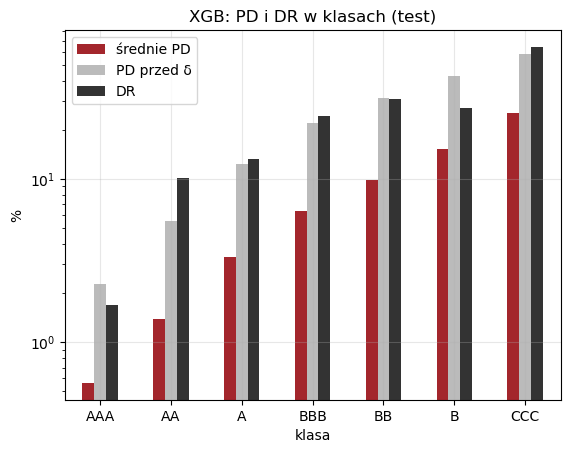

In [73]:
# Ratingi na teście: rozkład, backtest ze światłami (przed/po δ), klasa D = zaobserwowane defaulty, porównanie LR vs XGB
BT = {}
for k, d in MODELS.items():
    R = rating(d["test_4"]); ud = pd.Series(R).value_counts(normalize=True).reindex(RATING_LABELS).fillna(0)
    print(f"\n=== {k}: rating na teście | największy udział klasy {ud.max():.1%} ({ud.idxmax()}), HHI = {(ud ** 2).sum():.3f} ===")
    BT[k] = backtest(yt, d["test_4"], R, d["test_stat"]); display(BT[k].round(4))
    print(f"D (zaobserwowany default, ex post): {int(yt.sum())} podmiotów ({yt.mean():.1%}) | DR rośnie monotonicznie z klasą: {bool(np.all(np.diff(BT[k]['DR'].to_numpy()) >= 0))}")
    print("Światła po δ:", BT[k]["światło"].value_counts().to_dict(), "| przed δ:", BT[k]["światło przed δ"].value_counts().to_dict())
    BT[k].to_csv(ART / f"backtest_{k}_test.csv")
xl = pd.crosstab(rating(MODELS["LR"]["test_4"]), rating(MODELS["XGB"]["test_4"]), rownames=["rating LR"], colnames=["rating XGB"]); print("\nTabela przejść rating LR -> rating XGB (test):"); print(xl)
ax = (100 * BT["XGB"][["średnie PD", "PD przed δ", "DR"]]).plot.bar(rot=0, color=["#A3262C", "#BBBBBB", "#333333"]); ax.set_yscale("log"); ax.set_ylabel("%"); ax.set_title("XGB: PD i DR w klasach (test)"); plt.show()

In [74]:
# Decyzje na teście przy progach zamrożonych na valid; porównanie LR vs XGB; tabela decyzyjna progów
rows = []; dec = {}
for k, d in MODELS.items():
    for nm, p, prog in [("próg p*", d["test_4"], p_star), ("próg z valid", d["test_4"], d["prog_val"]), ("przyjmij wszystkich", d["test_4"], 1.01), ("PD przed δ, próg z valid", d["test_stat"], d["prog_val_ps"])]:
        rows.append({"model": k, "wariant": nm, **ekonomia(yt, p, ead["test"], prog)})
    dec[k] = ~(d["test_4"] < d["prog_val"])
tab_prog = pd.DataFrame(rows).set_index(["model", "wariant"]); display(tab_prog.round(4)); tab_prog.to_csv(ART / "decyzje_test.csv")
for k, d in MODELS.items():
    rej = dec[k]; tn, fp, fn, tp = confusion_matrix(yt, rej.astype(int), labels=[0, 1]).ravel()
    print(f"{k}: odrzucenia (próg z valid): TP={tp}, FP={fp}, FN={fn}, TN={tn}")
print(f"Zgodność decyzji LR vs XGB: {(dec['LR'] == dec['XGB']).mean():.1%} (różne decyzje: {(dec['LR'] != dec['XGB']).sum()} wniosków)")
tt = []
for thr in [0.02, 0.04, 0.06, 0.08, 0.12, 0.20]:
    row = {"próg PD": thr}
    for k, d in MODELS.items(): e_ = ekonomia(yt, d["test_4"], ead["test"], thr); row.update({f"{k}: akceptacja": e_["stopa akceptacji"], f"{k}: DR akcept.": e_["DR wśród przyjętych"], f"{k}: zysk": e_["zysk"]})
    tt.append(row)
print("\nTabela decyzyjna – wpływ progu (test, tylko raportowanie):"); print(pd.DataFrame(tt).round(4).to_string(index=False))

próg  stopa akceptacji  DR wśród przyjętych  EL przyjętych (oczekiwana)  strata zrealizowana    zysk
model wariant                                                                                                                        
LR    próg p*                  0.1818            0.9867               0.1267                      8.7206              33.7500 17.9500
      próg z valid             0.0350            0.6900               0.0966                      3.4963              18.0000 19.4000
      przyjmij wszystkich      1.0100            1.0000               0.1350                      9.8075              36.4500 15.4500
      PD przed δ, próg z valid 0.1900            0.8183               0.1059                     19.8946              23.4000 20.5000
XGB   próg p*                  0.1818            0.9700               0.1237                      9.0548              32.4000 18.6000
      próg z valid             0.0500            0.7533               0.0796                      3.5950              16.2000 25.4000
      przyjmij wszystkich      1.0100            1.0000               0.1350                     10.9899              36.4500 15.4500
      PD przed δ, próg z valid 0.1850            0.7633               0.0786                     14.2044              16.2000 26.0000

LR: odrzucenia (próg z valid): TP=41, FP=145, FN=40, TN=374
XGB: odrzucenia (próg z valid): TP=45, FP=103, FN=36, TN=416
Zgodność decyzji LR vs XGB: 81.7% (różne decyzje: 110 wniosków)

Tabela decyzyjna – wpływ progu (test, tylko raportowanie):
 próg PD  LR: akceptacja  LR: DR akcept.  LR: zysk  XGB: akceptacja  XGB: DR akcept.  XGB: zysk
  0.0200          0.3933          0.0339   19.2000           0.4783           0.0488    21.0000
  0.0400          0.7250          0.0966   20.4000           0.6833           0.0707    25.0500
  0.0600          0.8600          0.1085   20.8000           0.7983           0.0835    25.9000
  0.0800          0.9183          0.1162   19.9000           0.8567           0.0992    23.3500
  0.1200          0.9650          0.1209   19.4000           0.9217           0.1139    20.6500
  0.2000          0.9883          0.1282   17.5000           0.9767           0.1229    19.0000


In [75]:
# Audyt podgrup (test): AUC, Brier, średnie PD(4%), DR i DR/PD; małe podgrupy oznaczone
def audit(gs, name, min_n=60, min_def=8):
    rows = []
    for g in gs.dropna().unique():
        m = (gs == g).values; n_, nd = int(m.sum()), int(yt[m].sum()); r = {"podział": name, "grupa": g, "n": n_, "defaulty": nd, "DR": yt[m].mean() if n_ else np.nan}; ok = n_ >= min_n and nd >= min_def and nd < n_
        for k, d in MODELS.items():
            r[f"AUC {k}"] = roc_auc_score(yt[m], d["test_raw"][m]) if ok else np.nan; r[f"Brier {k}"] = brier_score_loss(yt[m], d["test_4"][m]) if n_ else np.nan; r[f"śr.PD {k}"] = d["test_4"][m].mean() if n_ else np.nan
        r["DR/PD XGB"] = r["DR"] / r["śr.PD XGB"] if n_ else np.nan; r["uwaga"] = "" if ok else "mała liczebność – niewiarygodne"; rows.append(r)
    return pd.DataFrame(rows)
parts = [audit(X_test[c].reset_index(drop=True), c) for c in CAT_COLS if X_test[c].nunique() <= 15]
for c in [f for f in NUM_COLS if re.search(r"(wiek|dni_istn|aktywa|przychod)", f.lower())][:2]:
    q = X_train[c].replace([np.inf, -np.inf], np.nan).quantile([1 / 3, 2 / 3]).values
    parts.append(audit(pd.cut(X_test[c].reset_index(drop=True), [-np.inf, q[0], q[1], np.inf], labels=["niski", "średni", "wysoki"]).astype(object), f"{c} (terciele z train)"))
audit_tab = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame(); print(audit_tab.round(3).to_string(index=False)); audit_tab.to_csv(ART / "audyt_podgrup_test.csv", index=False)

                                    podział  grupa   n  defaulty     DR  AUC LR  Brier LR  śr.PD LR  AUC XGB  Brier XGB  śr.PD XGB  DR/PD XGB                           uwaga
               szczegolnaFormaPrawna_Symbol    117 600        81 0.1350  0.7200    0.1200    0.0360   0.7710     0.1160     0.0410     3.3170                                
                      formaWlasnosci_Symbol    215  55         8 0.1450     NaN    0.1370    0.0390      NaN     0.1320     0.0490     2.9720 mała liczebność – niewiarygodne
                      formaWlasnosci_Symbol    226  19         1 0.0530     NaN    0.0520    0.0300      NaN     0.0500     0.0240     2.2270 mała liczebność – niewiarygodne
                      formaWlasnosci_Symbol    225   8         0 0.0000     NaN    0.0010    0.0290      NaN     0.0030     0.0360     0.0000 mała liczebność – niewiarygodne
                      formaWlasnosci_Symbol    216  54         9 0.1670     NaN    0.1410    0.0400      NaN     0.1460     0.0360

## 11. Monitoring: stabilność populacji – PSI wyniku i CSI cech
$PSI=\sum_i(a_i-e_i)\ln(a_i/e_i)$; $e_i$ – udziały na danych referencyjnych (train), $a_i$ – na danych bieżących (valid/test); dla cechy – CSI. Orientacyjnie: <0,10 stabilnie, 0,10–0,25 obserwuj, >0,25 istotna zmiana. PSI nie wykryje zmiany zależności cecha–default – dlatego monitoring obejmuje też kalibrację (średnie PD vs DR, Brier/ECE, DR w klasach) i stabilność top-k cech SHAP.

In [77]:
def psi(ref, cur, n_bins=10):
    ref, cur = pd.Series(ref), pd.Series(cur)
    if not pd.api.types.is_numeric_dtype(ref):
        kat = ref.astype(str).value_counts(normalize=True); e = kat.to_numpy(); a = cur.astype(str).value_counts(normalize=True).reindex(kat.index).fillna(0).to_numpy()
    else:
        ref, cur = ref.replace([np.inf, -np.inf], np.nan).dropna(), cur.replace([np.inf, -np.inf], np.nan).dropna()
        edges = np.unique(np.quantile(ref, np.linspace(0, 1, n_bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
        e = np.histogram(ref, edges)[0] / len(ref); a = np.histogram(cur, edges)[0] / len(cur)
    e, a = np.clip(e, 1e-6, None), np.clip(a, 1e-6, None); return float(np.sum((a - e) * np.log(a / e)))
d = MODELS["XGB"]; pd_tr = d["to_pd"](d["est"].predict_proba(X_train)[:, 1])
rows = [{"zmienna": "PD modelu (wynik)", "PSI valid": psi(pd_tr, d["to_pd"](d["val"])), "PSI test": psi(pd_tr, d["test_4"])}]
rows += [{"zmienna": c, "PSI valid": psi(X_train[c], X_val[c]), "PSI test": psi(X_train[c], X_test[c])} for c in FEATURES]
tab_psi = pd.DataFrame(rows).set_index("zmienna"); tab_psi["ocena (test)"] = pd.cut(tab_psi["PSI test"], [-np.inf, 0.10, 0.25, np.inf], labels=["stabilnie", "obserwuj", "istotna zmiana"])
display(tab_psi.sort_values("PSI test", ascending=False).head(12).round(4)); tab_psi.to_csv(ART / "psi_csi.csv")
print("Plan monitoringu: PSI/CSI (kwartalnie), Gini/KS (dryf jakości), średnie PD vs DR i Brier/ECE (dryf kalibracji), DR w klasach (backtest), stabilność top-k cech SHAP; progi alarmowe PSI > 0,25, czerwone światło w ≥ 2 klasach, spadek Gini > 5 pp.")

,PSI valid,PSI test,ocena (test)
zmienna,,,
wsk_zysk_CF_operacyjny,9.5687,8.1906,istotna zmiana
wsk_pokrycie_wyd_fin_gotowkowe_2,1.8386,3.0871,istotna zmiana
wsk_zadluzenia_gotowki_2,5.0992,2.5569,istotna zmiana
wsk_pokrycie_zob_kr_gotowkowe_2,3.5335,2.2110,istotna zmiana
RP_przeplywy_operacyjne,1.7418,1.8554,istotna zmiana
wsk_akt_generowania_got_2,1.0842,1.8554,istotna zmiana
RP_amortyzacja,1.5416,0.2338,obserwuj
wsk_zast_kapitalu_stalego,0.0193,0.0666,stabilnie
wsk_pokrycie_aktywow_tr_kapitalem_st,0.0162,0.0501,stabilnie


Plan monitoringu: PSI/CSI (kwartalnie), Gini/KS (dryf jakości), średnie PD vs DR i Brier/ECE (dryf kalibracji), DR w klasach (backtest), stabilność top-k cech SHAP; progi alarmowe PSI > 0,25, czerwone światło w ≥ 2 klasach, spadek Gini > 5 pp.


In [78]:
# Podsumowanie porównania modeli + artefakty (config, podziały, predykcje) + szkic MODEL_CARD.md
cmpm = pd.DataFrame({"AUC (test)": {k: roc_auc_score(yt, d["test_raw"]) for k, d in MODELS.items()}, "KS": {k: ks_stat(yt, d["test_raw"]) for k, d in MODELS.items()},
                     "Log-loss (kształt)": {k: log_loss(yt, d["test_stat"], labels=[0, 1]) for k, d in MODELS.items()}, "CITL a (kształt)": {k: cox(yt, d["test_stat"])[0] for k, d in MODELS.items()},
                     "Nachylenie b (kształt)": {k: cox(yt, d["test_stat"])[1] for k, d in MODELS.items()}, "Średnia PD po 4%": {k: d["test_4"].mean() for k, d in MODELS.items()},
                     "Odch.std AUC w CV": {"LR": cv_lr.AUC.std(), "XGB": cv_xgb.AUC.std()}}).T
print(cmpm.round(4)); print(f"\nStabilność rankingu ważności (refit): Spearman LR={sp_l:.2f} vs XGB={sp_x:.2f} | Jaccard top-10 LR={jc_l:.2f} vs XGB={jc_x:.2f}")
print(f"Wierność LIME (mediana R² poza próbą, logit): {fid['R2_poza_próbą_logit'].median():.2f}; SHAP addytywność: {shap_add_err:.1e}")
verdict = "różnica istotna statystycznie na korzyść XGBoost" if lo_g > 0 else "brak istotnej statystycznie przewagi XGBoost"
print(f"\nGini XGB − LR = {d_gini:+.3f}, CI95 [{lo_g:+.3f}; {hi_g:+.3f}] – {verdict}. Czy zysk uzasadnia utratę bezpośredniej interpretowalności zależy od wielkości i istotności przewagi, wierności/stabilności wyjaśnień post-hoc oraz wymogów regulacyjnych.")

cfg = {"seed": SEED, "target_pd": TARGET_PD, "margin": MARGIN, "lgd": LGD, "wykluczone": WYKLUCZONE, "data": DATA_PATH, "rating_bins": RATING_BINS[:-1] + [1.0], "rating_labels": RATING_LABELS,
       "lr_params": {k: (v if isinstance(v, (int, float, str)) else str(v)) for k, v in chosen_params.items()},
       "xgb_params": {k: (float(v) if isinstance(v, (float, np.floating)) else int(v) if isinstance(v, (int, np.integer)) else str(v)) for k, v in xgb_search.best_params_.items()},
       "kalibracja": {k: {"metoda": d["met"], "delta_4pct": float(d["delta"]), "prog_valid": float(d["prog_val"])} for k, d in MODELS.items()}}
json.dump(cfg, open(ART / "config_wyniki.json", "w"), indent=2, ensure_ascii=False)
pd.DataFrame({"y": yt, **{f"PD_{k}_4pct": d["test_4"] for k, d in MODELS.items()}, **{f"PD_{k}_raw": d["test_raw"] for k, d in MODELS.items()}}, index=X_test.index).to_csv(ART / "predykcje_test.csv")

card = f"""# MODEL CARD – scoring/rating PD (Projekt 1)
(szkic wygenerowany z notebooka – uzupełnij komentarze)

## Cel i zakres
Model oceny ryzyka (PD) na podstawie danych finansowych; horyzont i definicja defaultu: opisz zgodnie z dokumentacją zbioru. Nie używać poza populacją danych uczących.

## Dane
Plik: {DATA_PATH}; n = {len(dane)}, defaulty = {int(dane[TARGET].sum())} (DR = {DR_ALL:.2%}). Wykluczone cechy: {WYKLUCZONE if WYKLUCZONE else 'brak (screening AUC jednowymiarowego w sekcji 3.1)'}.
Podział stratyfikowany 60/20/20 (zapis: artifacts/splits.csv), 5-fold CV w train.

## Modele
Interpretowalny: regresja logistyczna ({chosen_params['clf__penalty']}, C={chosen_params['clf__C']}). Black-box: XGBoost (głębokość {xgb_clf.max_depth}, drzew {xgb_clf.n_estimators}).

## Jakość (test)
LR: AUC {roc_auc_score(yt, MODELS['LR']['test_raw']):.3f}; XGB: AUC {roc_auc_score(yt, MODELS['XGB']['test_raw']):.3f}; Gini XGB−LR = {d_gini:+.3f} (CI95 [{lo_g:+.3f}; {hi_g:+.3f}]).

## Kalibracja
Metody kształtu: LR – {MODELS['LR']['met']}, XGB – {MODELS['XGB']['met']}; δ do 4%: LR {MODELS['LR']['delta']:+.3f}, XGB {MODELS['XGB']['delta']:+.3f}. Średnie PD na teście po 4%: LR {MODELS['LR']['test_4'].mean():.2%}, XGB {MODELS['XGB']['test_4'].mean():.2%}; DR na teście {yt.mean():.2%}. 4% to zewnętrzne założenie biznesowe, nie poprawa kalibracji statystycznej.

## Wyjaśnienia
Globalne: SHAP (TreeSHAP, log-szanse, val) – top cechy: {', '.join(shap_imp.index[:5])}. Lokalne: waterfall i kody przyczyn dla 4 case studies. Wierność: mediana R² poza próbą (LIME) = {fid['R2_poza_próbą_logit'].median():.2f}. Stabilność: patrz sekcja 7.2. Ważność cech: permutacyjna (6.2a) obok SHAP; interakcje: SHAP. Global surrogate (głębokość 3): R² na valid = {TAB_SUR.loc[3, 'wierność R² (val)']:.2f} (7.4).
Kształt zależności: {INTERPRETABILITY_TEXT}

## Skala i decyzje
7 klas (AAA…CCC) o stałych granicach + D (default). Próg teoretyczny p* = {p_star:.3f}; próg z valid: LR {MODELS['LR']['prog_val']:.3f}, XGB {MODELS['XGB']['prog_val']:.3f}.

## Ograniczenia i ryzyka
Dane przekrojowe (brak stabilności czasowej), mała liczba defaultów (niepewność kalibracji, szczególnie izotonicznej), wyjaśnienia nie dowodzą przyczynowości, kontrfaktyk nie przelicza powiązań rachunkowych.

## Monitoring
PSI/CSI, dryf jakości i kalibracji, DR w klasach, stabilność top-k SHAP – progi alarmowe w sekcji 11.
"""
open("MODEL_CARD.md", "w", encoding="utf-8").write(card); print("\nZapisano: artifacts/*, MODEL_CARD.md")

                           LR    XGB
AUC (test)             0.7200 0.7705
KS                     0.3537 0.4220
Log-loss (kształt)     0.3573 0.3393
CITL a (kształt)       0.0621 0.0443
Nachylenie b (kształt) 0.9739 0.8818
Średnia PD po 4%       0.0363 0.0407
Odch.std AUC w CV      0.0265 0.0200

Stabilność rankingu ważności (refit): Spearman LR=0.67 vs XGB=0.65 | Jaccard top-10 LR=0.50 vs XGB=0.45
Wierność LIME (mediana R² poza próbą, logit): 0.58; SHAP addytywność: 3.4e-06

Gini XGB − LR = +0.101, CI95 [+0.021; +0.176] – różnica istotna statystycznie na korzyść XGBoost. Czy zysk uzasadnia utratę bezpośredniej interpretowalności zależy od wielkości i istotności przewagi, wierności/stabilności wyjaśnień post-hoc oraz wymogów regulacyjnych.

Zapisano: artifacts/*, MODEL_CARD.md


### Wnioski
Skuteczność: XGB przewyższa LR na teście o $+5{,}05\text{ p.p.}$ AUC ($0{,}771$ vs $0{,}720$), $+10{,}1\text{ p.p.}$ Gini (istotne statystycznie: $95\%\text{ CI } [+0{,}021;\, +0{,}176]$) i $+6{,}8\text{ p.p.}$ KS ($0{,}422$ vs $0{,}354$), wykazując też większą stabilność w CV (std AUC $0{,}020$ vs $0{,}027$).Interpretowalność: Kluczowe cechy (kondycja sektora, pokrycie odsetek z EBITDA, płynność gotówkowa, dźwignia, zysk/CF) mają spójny sens ekonomiczny i kierunek w LR oraz SHAP; PDP/ICE ujawniają progi nasycenia i interakcje między branżą a płynnością.Wierność i stabilność: TreeSHAP jest ściśle addytywny (błąd $3{,}4 \cdot 10^{-6}$), podczas gdy LIME ma niską wierność ($R^2 = 0{,}58$) i niestabilność próbek; spadek zgodności po reficie (Spearman $\approx 0{,}65$, Jaccard $\approx 0{,}45$) wynika ze współliniowości danych, a surogat głębi 3 (8 liści) osiąga $R^2 = 0{,}587$ na valid.Kalibracja 4%: Korekta poziomu bazowego ($\delta = -1{,}421$ XGB; $-1{,}473$ LR) skaluje średnie PD z $13{,}5\%$ do celu $4\%$ ($4{,}07\%$ na teście XGB), co celowo pogarsza Brier, LogLoss i CITL na próbie badawczej bez zmiany rankingu (AUC/KS bez zmian).Progi i ratingi: Próg z walidacji ($0{,}050$ XGB vs $0{,}035$ LR po $\delta$) daje wyższy zysk dla XGB ($25{,}40$ vs $19{,}40$; zgodność decyzji $81{,}7\%$); przed $\delta$ 6/7 klas świeci na zielono, po $\delta$ czerwone światła wynikają z kotwicy $4\%$, a drobna inwersja DR między BB a B na teście jest efektem małej próby.Kontrfaktyk: Wskazuje minimalne zmiany cech zgodne z SHAP/LIME (płynność, EBITDA, dźwignia), ale opisuje wyłącznie model (brak przyczynowości), nie bada wykonalności biznesowej i modyfikuje powiązane wskaźniki pojedynczo.Audyt podgrup: XGB utrzymuje przewagę w dużych i średnich podmiotach (AUC do $0{,}842$) oraz stałą relację $\text{DR}/\text{PD}$; mikrojednostki mają niższą separację (uproszczona sprawozdawczość), a małe podgrupy form własności ($n < 60$) nie pozwalają na wiarygodne wnioskowanie.Rekomendacja: Tak – istotna statystycznie przewaga $+10{,}1\text{ p.p.}$ Gini, $+30{,}9\%$ wyższy zysk portfela oraz niższa koncentracja skali ratingowej w pełni uzasadniają wybór XGBoost, a utratę bezpośredniej liniowości skutecznie kompensuje deterministyczny TreeSHAP oraz kwartalny monitoring PSI/CSI i jakości.